# Image Generation — VAE, DDPM and LDM on CIFAR-10

Three generative models are built from scratch, trained on **CIFAR-10**, and compared head to
head. The five phone photographs in `smartphone_images/` are then pushed **through** the trained
models to synthesise new images of the same subject.

| Model | Where the generative process lives | What is learned |
|---|---|---|
| **VAE** | a 128-d vector latent space | an amortised encoder `q(z\|x)` and a decoder `p(x\|z)`, trained by maximising an ELBO |
| **DDPM** | 32x32x3 **pixel** space | a noise predictor `eps_theta(x_t, t)` that inverts a 1000-step Gaussian corruption |
| **LDM** | 16x16x4 **latent** space of a KL-autoencoder | the same denoiser, but cheaper per step, plus class conditioning through cross-attention |

**Task map.** Every numbered task from the assignment sheet is answered in the section named
after it:

| Task | Section |
|---|---|
| 1. Develop a VAE, synthesise images of a favourite object | §2 |
| 2. Decode five `z ~ N(5, sigma^2)` vectors | §3 |
| 3. BCE vs MSE reconstruction loss | §4 |
| 4. KL divergence in terms of mean and variance | §5 |
| 5. Develop and train a DDPM (+ explain all five stages) | §6 |
| 6. Five DDPM samples from standard normal noise | §7 |
| 7. Develop and train an LDM (+ explain encoder/decoder, latent diffusion, U-Net, timestep embedding, conditioning) | §8 |
| 8. Five LDM samples from latent noise | §9 |
| 9. Quantitative comparison of the three models | §10 |
| 10. Advantages, limitations, and why latent diffusion is cheaper | §11 |

### How the two image sources are used

This distinction runs through the whole notebook, so it is worth stating once, plainly:

* **CIFAR-10 is the training distribution.** All four networks — two VAE variants, the DDPM, and
  the LDM's autoencoder plus its latent denoiser — learn `p(x)` from the 50 000 CIFAR-10
  training images. The 10 000-image test split is held out as the FID/KID reference, so the
  distribution scores in §10 are computed against genuinely unseen data.
* **The five photographs are inputs, never training data.** Tasks 1, 5 and 7 ask for synthesised
  images of a favourite object that resemble real phone photographs. Each photograph is
  centre-cropped to 32x32 and passed *through* the trained model, which redraws it using
  everything it learned from CIFAR-10. Each model has its own natural mechanism for this:

  | Task | Model | Mechanism |
  |---|---|---|
  | 1 | VAE | encode to `z ~ q(z\|x)`, decode — the reconstruction path |
  | 5 | DDPM | **SDEdit**: partially noise the photograph to `x_t`, then run the reverse chain from `t` |
  | 7 | LDM | the same partial-noising, but in latent space, with **class conditioning** on `bird`/`dog` |

  The photographs happen to be three birds and two dogs — both CIFAR-10 classes — which is what
  makes this meaningful rather than arbitrary.
* **Tasks 2, 6 and 8 use no photographs at all.** They synthesise from pure noise, which is the
  unconditional generation the assignment specifies there.

**Running it.** `QUICK_MODE = True` in §0 runs the whole notebook end to end in a couple of
minutes to check that every cell works; `False` is the real run (roughly an hour and a half on
one modern GPU). Everything a report needs — figures, sample grids, metric tables, checkpoints —
is written under `outputs/`.

**If the run is interrupted** — a power cut, a closed lid, a killed kernel — just re-run the
notebook from the top. Every training loop checkpoints itself every 500 steps and resumes from
where it stopped, and models that already finished are loaded rather than retrained. The details
are in §0.

## §0 Setup

Imports, reproducibility, device, output folders, and the two knobs that control the whole
run: `QUICK_MODE` and `IMG_SIZE`.

In [1]:
import json
import math
import os
import random
import time
import warnings
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display
from PIL import Image
from torchvision import transforms as T
from torchvision.utils import make_grid
from tqdm.auto import tqdm as _tqdm


def tqdm(*args, **kwargs):
    """tqdm with slower refresh, so a 30-minute training loop does not write tens of thousands
    of progress lines into the saved notebook."""
    kwargs.setdefault("mininterval", 2.0)
    kwargs.setdefault("leave", False)
    return _tqdm(*args, **kwargs)


warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "font.size": 9, "axes.grid": False, "figure.max_open_warning": 0})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# ----------------------------------------------------------------------------- master switches
QUICK_MODE = False      # True -> ~2 min smoke test of every cell; False -> full training run
IMG_SIZE = 32           # CIFAR-10 resolution; all three models generate 32x32 RGB images
SEED = 1234

# Tasks 1/5/7 push the five photographs through the models. For the two diffusion models that
# means SDEdit: noise the input to t = strength*T, then denoise back. Swept, with 0.6 as the
# headline answer.
SDEDIT_STRENGTHS = [0.2, 0.4, 0.6, 0.8, 1.0]
SDEDIT_MAIN = 0.6

# ----------------------------------------------------------------------------- paths
def _find_root() -> Path:
    """The assignment folder, i.e. the one that contains smartphone_images/.
    CIFAR-10 is downloaded into `data/` next to it on first run."""
    for cand in (Path.cwd(), *Path.cwd().parents):
        if (cand / "smartphone_images").is_dir():
            return cand
    raise FileNotFoundError("could not locate 'smartphone_images' from " + str(Path.cwd()))

ROOT = _find_root()
IMG_DIR = ROOT / "smartphone_images"
OUT = ROOT / "outputs"
FIG_DIR, MODEL_DIR, SAMPLE_DIR = OUT / "figures", OUT / "models", OUT / "samples"
CKPT_DIR, CACHE_DIR = OUT / "checkpoints", OUT / "cache"
for _d in (OUT, FIG_DIR, MODEL_DIR, SAMPLE_DIR, CKPT_DIR, CACHE_DIR):
    _d.mkdir(parents=True, exist_ok=True)
for _stale in CKPT_DIR.glob("*.tmp"):     # debris from a power cut during a checkpoint write
    _stale.unlink(missing_ok=True)

# ----------------------------------------------------------------------- crash / power-cut safety
RESUME = True                            # pick up from outputs/checkpoints/, don't restart at 0
CKPT_EVERY = 25 if QUICK_MODE else 500   # optimisation steps between checkpoints

# ----------------------------------------------------------------------------- reproducibility
def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16
USE_AMP = DEVICE.type == "cuda"

def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP)

# ----------------------------------------------------------------------------- training budgets
@dataclass
class Budget:
    """Optimisation steps / batch sizes. Chosen from a throughput benchmark so the full run is
    roughly 80 minutes on one modern GPU; QUICK_MODE shrinks everything to a smoke test."""
    vae_steps: int = 12000
    vae_batch: int = 128
    ddpm_steps: int = 15000
    ddpm_batch: int = 128
    ae_steps: int = 8000          # LDM first stage (KL-autoencoder)
    ae_batch: int = 128
    ldm_steps: int = 18000
    ldm_batch: int = 128
    eval_samples: int = 2500      # generated images per model used for FID/KID/diversity
    eval_real: int = 10000        # the whole CIFAR-10 test split, as the FID/KID reference

BUDGET = Budget()
if QUICK_MODE:
    BUDGET = Budget(vae_steps=150, vae_batch=32, ddpm_steps=150, ddpm_batch=32,
                    ae_steps=150, ae_batch=32, ldm_steps=150, ldm_batch=32,
                    eval_samples=32, eval_real=64)

RESULTS: dict = {}   # every headline number the report needs ends up in here

print(f"root       : {ROOT}")
print(f"device     : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == 'cuda' else ""))
print(f"torch      : {torch.__version__}   amp: {AMP_DTYPE if USE_AMP else 'off'}")
print(f"image size : {IMG_SIZE}x{IMG_SIZE}   quick mode: {QUICK_MODE}")

root       : D:\Study\MSc\2nd semester\Computer Vision\Assignments\04
device     : cuda (NVIDIA GeForce RTX 5070 Ti)
torch      : 2.7.1+cu128   amp: torch.bfloat16
image size : 32x32   quick mode: False


### Interruption safety — checkpointing and resuming

The four training runs below take about an hour in total, which is long enough that a power cut
or a closed laptop lid will eventually land in the middle of one. Every training loop is
therefore **resumable**:

* Every `CKPT_EVERY = 500` optimisation steps (a little over one pass over CIFAR-10, and
  about a minute of wall clock for the slowest model) the full training state — weights,
  optimiser moments, LR-schedule position, EMA shadow weights, gradient scaler, loss history,
  elapsed time and all four RNG streams — is written to `outputs/checkpoints/<name>.ckpt`.
* The write is **atomic**: it goes to a `.tmp` file which is then renamed. Losing power *during*
  a checkpoint write leaves the previous good checkpoint intact rather than a truncated file.
* On startup each trainer looks for its checkpoint and continues from the exact step it reached.
  Restoring the RNG state means the resumed run sees the same batch sequence it would have.
* When a model finishes it is written to `outputs/models/<name>.pt` and its checkpoint is
  deleted. A later re-run finds the finished model and **skips that training entirely** — so
  after an interruption you simply re-run the notebook top to bottom and only the unfinished
  work is repeated.
* Each checkpoint records the configuration it was trained under. Change a step count, batch
  size or learning rate and the stale checkpoint is ignored rather than silently resumed.
* The §10 sample generation — thousands of sequential denoising steps — is cached under
  `outputs/cache/` for the same reason.

Set `RESUME = False` above to force everything to train from scratch.

### Small shared helpers

Parameter counting, a hook-based multiply-accumulate (MAC) counter used for the cost
comparison in §10-§11, an EMA wrapper for the diffusion models, checkpoint save/load, and
figure/grid utilities.

In [2]:
def count_params(module: nn.Module, trainable_only: bool = True) -> int:
    """Parameter count. Pass trainable_only=False for frozen modules (e.g. the LDM first stage,
    whose parameters have requires_grad=False but still occupy memory and do work)."""
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


@torch.no_grad()
def count_macs(module: nn.Module, *args, **kwargs) -> int:
    """Multiply-accumulate operations of one forward pass (Conv2d / Linear / attention matmuls).

    Enough for an order-of-magnitude pixel-space vs latent-space comparison; it deliberately
    ignores norms, activations and elementwise ops, which are memory- rather than FLOP-bound.
    """
    total = 0
    handles = []

    def conv_hook(m, inp, out):
        nonlocal total
        total += int(np.prod(out.shape[2:])) * out.shape[1] * (m.in_channels // m.groups) * int(np.prod(m.kernel_size)) * out.shape[0]

    def lin_hook(m, inp, out):
        nonlocal total
        total += m.in_features * m.out_features * int(np.prod(out.shape[:-1]))

    for m in module.modules():
        if isinstance(m, nn.Conv2d):
            handles.append(m.register_forward_hook(conv_hook))
        elif isinstance(m, nn.Linear):
            handles.append(m.register_forward_hook(lin_hook))
    was_training = module.training
    module.eval()
    module(*args, **kwargs)
    module.train(was_training)
    for h in handles:
        h.remove()
    return total


class EMA:
    """Exponential moving average of model weights - standard practice for diffusion sampling."""

    def __init__(self, model: nn.Module, decay: float = 0.9995):
        self.decay = decay
        self.shadow = {k: v.detach().clone().float() for k, v in model.state_dict().items()
                       if v.dtype.is_floating_point}
        self.buffers = {k: v.detach().clone() for k, v in model.state_dict().items()
                        if not v.dtype.is_floating_point}

    @torch.no_grad()
    def update(self, model: nn.Module, step: int) -> None:
        # warm up the decay so the average is not dominated by the random initialisation
        d = min(self.decay, (1 + step) / (10 + step))
        for k, v in model.state_dict().items():
            if k in self.shadow:
                self.shadow[k].mul_(d).add_(v.detach().float(), alpha=1 - d)
            else:
                self.buffers[k] = v.detach().clone()

    def state_dict(self) -> dict:
        return {**{k: v.clone() for k, v in self.shadow.items()},
                **{k: v.clone() for k, v in self.buffers.items()}}

    def load_state_dict(self, sd: dict) -> None:
        for k, v in sd.items():
            if k in self.shadow:
                self.shadow[k] = v.detach().clone().float()
            else:
                self.buffers[k] = v.detach().clone()

    def copy_to(self, model: nn.Module) -> None:
        model.load_state_dict({k: v.to(next(model.parameters()).dtype) if v.dtype.is_floating_point else v
                               for k, v in self.state_dict().items()})


def to_uint8_grid(x: torch.Tensor, nrow: int = 5, pad: int = 2) -> np.ndarray:
    """(B,3,H,W) in [0,1] -> H,W,3 uint8 grid ready for imshow/imsave."""
    g = make_grid(x.detach().float().clamp(0, 1).cpu(), nrow=nrow, padding=pad, pad_value=1.0)
    return (g.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)


def show_grid(x: torch.Tensor, title: str = "", nrow: int = 5, save: str | None = None,
              figsize: tuple = (10, 2.4), subtitles: list[str] | None = None) -> None:
    arr = to_uint8_grid(x, nrow=nrow)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(arr)
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)
    if subtitles:
        n = len(subtitles)
        for i, s in enumerate(subtitles):
            ax.text((i + 0.5) / n, -0.06, s, transform=ax.transAxes, ha="center", va="top", fontsize=8)
    if save:
        fig.savefig(FIG_DIR / save)
    plt.show()


def save_individual(x: torch.Tensor, stem: str) -> None:
    """Write each image of a batch separately, e.g. outputs/samples/ddpm_sample_01.png."""
    for i, img in enumerate(x.detach().float().clamp(0, 1).cpu(), start=1):
        arr = (img.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
        Image.fromarray(arr).save(SAMPLE_DIR / f"{stem}_{i:02d}.png")


# --------------------------------------------------------------------- checkpointing / resuming
def _atomic_save(obj, path: Path) -> None:
    """Write to a temporary file first, then rename. A power cut mid-write therefore leaves the
    previous good checkpoint intact instead of a half-written unusable one."""
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    tmp.replace(path)


def _rng_state() -> dict:
    return {"torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
            "numpy": np.random.get_state(), "python": random.getstate()}


def _restore_rng(state: dict | None) -> None:
    if not state:
        return
    torch.set_rng_state(state["torch"].cpu().to(torch.uint8))
    if state.get("cuda") and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([s.cpu().to(torch.uint8) for s in state["cuda"]])
    np.random.set_state(state["numpy"])
    random.setstate(state["python"])


def save_checkpoint(tag: str, step: int, model, opt, sched, hist: dict, ema=None,
                    scaler=None, meta: dict | None = None, elapsed: float = 0.0) -> None:
    _atomic_save({
        "step": step + 1,                    # the step to RESUME at
        "model": model.state_dict(),
        "opt": opt.state_dict(),
        "sched": sched.state_dict(),
        "scaler": scaler.state_dict() if scaler is not None else None,
        "ema": ema.state_dict() if ema is not None else None,
        "hist": hist, "meta": meta or {}, "elapsed": elapsed, "rng": _rng_state(),
    }, CKPT_DIR / f"{tag}.ckpt")


def load_checkpoint(tag: str, meta: dict | None = None) -> dict | None:
    """Latest checkpoint for `tag`, or None if absent / stale / unreadable."""
    path = CKPT_DIR / f"{tag}.ckpt"
    if not (RESUME and path.exists()):
        return None
    try:
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
    except Exception as exc:                       # truncated by a power cut, wrong torch version…
        print(f"  ! {path.name} could not be read ({type(exc).__name__}); training from scratch")
        return None
    if meta is not None and ck.get("meta") != meta:
        print(f"  ! {path.name} was written for a different configuration; training from scratch")
        return None
    return ck


def load_finished(tag: str, meta: dict | None = None) -> dict | None:
    """A fully trained model saved in outputs/models/, if one matching `meta` exists."""
    path = MODEL_DIR / f"{tag}.pt"
    if not (RESUME and path.exists()):
        return None
    try:
        blob = torch.load(path, map_location=DEVICE, weights_only=False)
    except Exception:
        return None
    return blob if (meta is None or blob.get("meta") == meta) else None


class Timer:
    """`with Timer() as t: ...` then read `t.seconds`."""

    def __enter__(self):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        self.t0 = time.perf_counter()
        return self

    def __exit__(self, *exc):
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        self.seconds = time.perf_counter() - self.t0

print("helpers ready")

helpers ready


## §1 Data — CIFAR-10 for training, five phone photographs as inputs

Two distinct roles, and keeping them apart is what makes the rest of the notebook coherent:

| | **CIFAR-10** | **`smartphone_images/`** |
|---|---|---|
| what it is | 50 000 train + 10 000 test images, 32x32 RGB, 10 classes | 5 full-resolution phone photographs |
| role | the **training distribution** — every model learns `p(x)` from it | **inputs at generation time** for Tasks 1, 5 and 7 |
| used for training? | yes, all four models | **never** |

Tasks 2, 6 and 8 ask for images synthesised from *pure noise*, so they use only the trained
models. Tasks 1, 5 and 7 ask for synthesised images of a favourite object that resemble real
phone photographs — so the five photographs are pushed **through** the trained models, and each
model's own mechanism produces a new image that keeps the photograph's content while being
redrawn from what the model learned on CIFAR-10.

In [3]:
from torchvision.datasets import CIFAR10

DATA_DIR = ROOT / "data"
_train = CIFAR10(DATA_DIR, train=True, download=True)
_test = CIFAR10(DATA_DIR, train=False, download=True)
CIFAR_CLASSES = _train.classes
NUM_CLASSES = len(CIFAR_CLASSES)

# whole training set as one uint8 tensor on the GPU: 50000*3*32*32 = 147 MB, so batches cost
# nothing to assemble and no DataLoader worker processes are needed (they are fragile on Windows)
TRAIN_X = torch.from_numpy(_train.data).permute(0, 3, 1, 2).contiguous().to(DEVICE)
TRAIN_Y = torch.tensor(_train.targets, dtype=torch.long, device=DEVICE)
TEST_X = torch.from_numpy(_test.data).permute(0, 3, 1, 2).contiguous()
TEST_Y = torch.tensor(_test.targets, dtype=torch.long)

print(f"CIFAR-10 train {tuple(TRAIN_X.shape)} on {DEVICE} ({TRAIN_X.nbytes/1e6:.0f} MB uint8)")
print(f"CIFAR-10 test  {tuple(TEST_X.shape)}  (held out - the FID/KID reference)")
print(f"classes: {', '.join(f'{i}={c}' for i, c in enumerate(CIFAR_CLASSES))}")

CIFAR-10 train (50000, 3, 32, 32) on cuda (154 MB uint8)
CIFAR-10 test  (10000, 3, 32, 32)  (held out - the FID/KID reference)
classes: 0=airplane, 1=automobile, 2=bird, 3=cat, 4=deer, 5=dog, 6=frog, 7=horse, 8=ship, 9=truck


### The training stream

The only augmentation is a random horizontal flip — this is exactly what Ho et al. (2020) use
for CIFAR-10, and with 50 000 real images there is no need for the aggressive cropping a tiny
dataset would demand. The flip is applied on-device, so a batch costs one gather and one flip.

All four training runs (VAE-MSE, VAE-BCE, DDPM, the LDM's autoencoder and its latent denoiser)
draw from this identical stream, which is what makes the §10 comparison fair.

reference set: (10000, 3, 32, 32) drawn from the CIFAR-10 *test* split


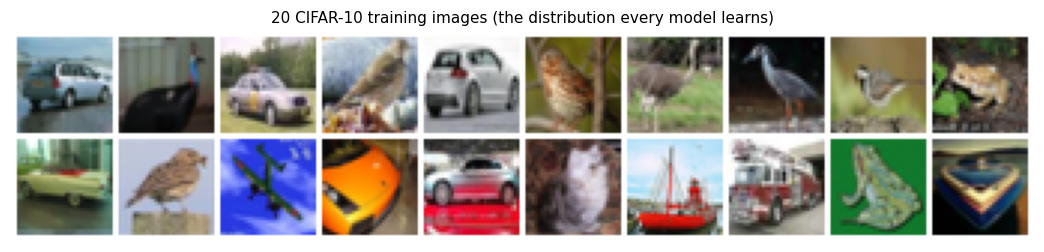

labels: automobile, bird, automobile, bird, automobile, bird, bird, bird, bird, frog


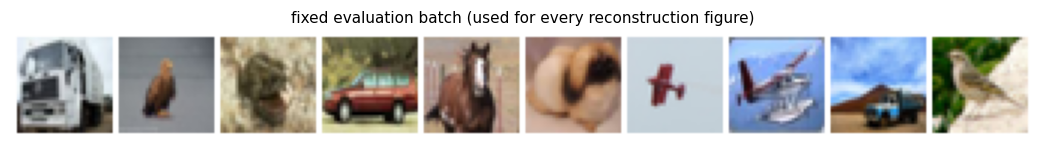

In [4]:
def sample_batch(batch_size: int) -> tuple[torch.Tensor, torch.Tensor]:
    """A random CIFAR-10 batch: x in [0,1] on DEVICE, plus its class labels."""
    idx = torch.randint(0, TRAIN_X.shape[0], (batch_size,), device=TRAIN_X.device)
    x = TRAIN_X[idx].float().div_(255.0)
    flip = torch.rand(batch_size, device=x.device) < 0.5
    x[flip] = torch.flip(x[flip], dims=[-1])
    return x, TRAIN_Y[idx]


# frozen held-out reference for FID/KID, and a fixed batch for every reconstruction figure
seed_everything()
_ref_idx = torch.randperm(len(TEST_X))[:BUDGET.eval_real]
REAL_REF = TEST_X[_ref_idx].float() / 255.0
REAL_REF_Y = TEST_Y[_ref_idx]
FIXED_REAL = REAL_REF[:10].clone()
FIXED_REAL_Y = REAL_REF_Y[:10].clone()

print(f"reference set: {tuple(REAL_REF.shape)} drawn from the CIFAR-10 *test* split")

_x, _y = sample_batch(20)
show_grid(_x.cpu(), "20 CIFAR-10 training images (the distribution every model learns)",
          nrow=10, save="01_cifar_batch.png", figsize=(12, 3.0))
print("labels:", ", ".join(CIFAR_CLASSES[i] for i in _y[:10].tolist()))

show_grid(FIXED_REAL, "fixed evaluation batch (used for every reconstruction figure)",
          nrow=10, save="02_fixed_eval_batch.png", figsize=(12, 1.7))

### The five photographs

These are the "favourite object" of Tasks 1, 5 and 7. They were taken on a phone and are
**wildlife shots that fall squarely inside two CIFAR-10 classes**, which is what makes it
meaningful to push them through models trained on CIFAR-10:

| file | subject | CIFAR-10 class |
|---|---|---|
| `01.jpg` | blue-throated barbet perched in foliage | `bird` |
| `02.jpg` | myna in flight | `bird` |
| `03.jpg` | black-rumped flameback woodpecker on a trunk | `bird` |
| `04.jpg` | puppy sitting on a ledge | `dog` |
| `05.jpg` | dog sitting beside a rickshaw | `dog` |

Each is centre-cropped to a square and resized to 32x32 so that it lives in the same space the
models generate in. That downsampling is severe — a 6016x4000 photograph becomes 1 024 pixels —
and it is worth being clear that **most of the photographic detail is gone before any model sees
it**. What survives is pose, palette and coarse layout, which is exactly the information the
models are able to work with at this resolution.

The class labels are used only by the LDM in §8, whose cross-attention conditioning needs to be
told *what* to draw.

5 photographs -> (5, 3, 32, 32)
  01.jpg    2487x1501  barbet           -> CIFAR class 'bird'
  02.jpg    2346x1683  myna in flight   -> CIFAR class 'bird'
  03.jpg    4159x3328  woodpecker       -> CIFAR class 'bird'
  04.jpg    6016x4000  puppy            -> CIFAR class 'dog'
  05.jpg     640x853   dog              -> CIFAR class 'dog'


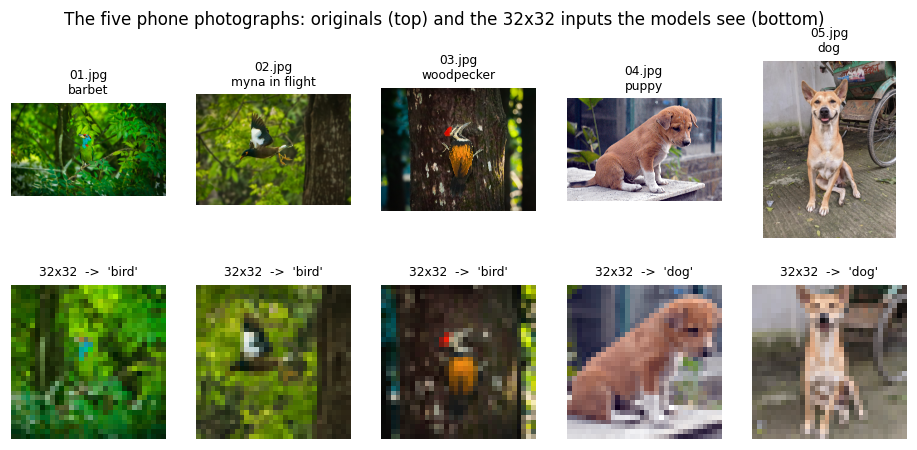

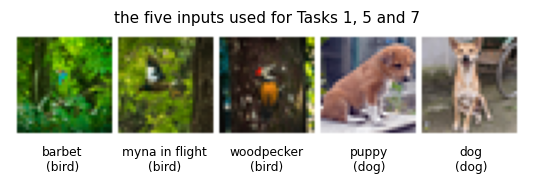

In [5]:
PHOTO_PATHS = sorted(IMG_DIR.glob("*.jpg")) + sorted(IMG_DIR.glob("*.jpeg")) + \
              sorted(IMG_DIR.glob("*.png"))
assert len(PHOTO_PATHS) > 0, f"no photographs found in {IMG_DIR}"

# subject of each photograph, mapped to the nearest CIFAR-10 class
PHOTO_CLASS_NAMES = ["bird", "bird", "bird", "dog", "dog"][:len(PHOTO_PATHS)]
PHOTO_SUBJECTS = ["barbet", "myna in flight", "woodpecker", "puppy", "dog"][:len(PHOTO_PATHS)]
PHOTO_Y = torch.tensor([CIFAR_CLASSES.index(c) for c in PHOTO_CLASS_NAMES], dtype=torch.long)


def load_photo(path: Path, size: int = IMG_SIZE) -> tuple[Image.Image, torch.Tensor]:
    """Full-resolution PIL image (for display) and its centre-cropped 32x32 tensor in [0,1]."""
    img = Image.open(path).convert("RGB")
    side = min(img.size)
    left, top = (img.size[0] - side) // 2, (img.size[1] - side) // 2
    square = img.crop((left, top, left + side, top + side))
    return img, T.functional.to_tensor(square.resize((size, size), Image.LANCZOS))


PHOTO_FULL, _small = zip(*[load_photo(p) for p in PHOTO_PATHS])
PHOTOS = torch.stack(_small)                      # (5, 3, 32, 32) in [0,1]

print(f"{len(PHOTOS)} photographs -> {tuple(PHOTOS.shape)}")
for p, subj, cls in zip(PHOTO_PATHS, PHOTO_SUBJECTS, PHOTO_CLASS_NAMES):
    print(f"  {p.name:<8} {Image.open(p).size[0]:>5}x{Image.open(p).size[1]:<5} "
          f"{subj:<16} -> CIFAR class '{cls}'")

fig, axes = plt.subplots(2, len(PHOTOS), figsize=(2.1 * len(PHOTOS), 4.6))
for i, (full, small, subj, cls) in enumerate(zip(PHOTO_FULL, PHOTOS, PHOTO_SUBJECTS,
                                                 PHOTO_CLASS_NAMES)):
    axes[0, i].imshow(full)
    axes[0, i].set_title(f"{PHOTO_PATHS[i].name}\n{subj}", fontsize=8)
    axes[1, i].imshow(small.permute(1, 2, 0).numpy(), interpolation="nearest")
    axes[1, i].set_title(f"32x32  ->  '{cls}'", fontsize=8)
    axes[0, i].set_axis_off(); axes[1, i].set_axis_off()
fig.suptitle("The five phone photographs: originals (top) and the 32x32 inputs the models see (bottom)",
             fontsize=11)
fig.savefig(FIG_DIR / "00_photographs.png")
plt.show()

show_grid(PHOTOS, "the five inputs used for Tasks 1, 5 and 7", nrow=5,
          save="03_photo_inputs.png", figsize=(6, 1.7),
          subtitles=[f"{s}\n({c})" for s, c in zip(PHOTO_SUBJECTS, PHOTO_CLASS_NAMES)])

### Two conventions used throughout

* **VAE / autoencoders** work in `[0, 1]` (so that BCE is well defined) and their decoders emit
  **logits**; a sigmoid is applied when an image is needed.
* **Diffusion models** work in `[-1, 1]`, which matches the symmetric Gaussian noise they add.

In [6]:
def to_pm1(x01: torch.Tensor) -> torch.Tensor:
    """[0,1] -> [-1,1]"""
    return x01 * 2.0 - 1.0


def to_01(xpm1: torch.Tensor) -> torch.Tensor:
    """[-1,1] -> [0,1]"""
    return (xpm1 + 1.0) * 0.5

### Evaluation toolkit

Defined once here and reused by every model, so the three are scored with identical code.

**Distribution similarity.** `FID` (Fréchet Inception Distance) and `KID` (Kernel Inception
Distance) are computed on 2048-d pool features of an ImageNet-pretrained Inception-v3.

The reference distribution is the **CIFAR-10 test split**, which the models never see during
training, so these are proper held-out distribution scores rather than a training-set echo.

> **Two caveats before comparing against published numbers.** Features come from torchvision's
> Inception-v3 rather than the original TensorFlow graph, which shifts FID by a few points; and
> the standard CIFAR-10 protocol uses 50 000 generated samples against the 50 000-image train
> split, whereas we use far fewer (see `BUDGET.eval_samples`) against the 10 000-image test
> split, which biases FID *upwards*. So these values are somewhat higher than literature FIDs
> for an equivalent model. The comparison *between* the three models is exact — identical code,
> identical reference, identical sample count. KID is reported alongside FID because it is
> unbiased at small sample counts.

**Sharpness.** Two classical no-reference focus measures, both computed on the luminance
channel: the *variance of the Laplacian* and the *Tenengrad* (mean squared Sobel gradient
magnitude). Higher = crisper edges. Blurry VAE samples score low almost by construction, so
this is the metric that quantifies the "VAEs are blurry" claim.

**Diversity.** Mean pairwise Euclidean distance between Inception features of generated
samples (semantic spread), plus the mean per-pixel standard deviation across the sample set
(raw spread). A model that collapses to one mode scores near zero on both.

**Fidelity.** PSNR and SSIM, for autoencoder reconstructions only (diffusion models have no
reconstruction task).

In [7]:
from scipy import linalg
from torchvision.models import Inception_V3_Weights, inception_v3

_IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
_IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


class InceptionFeatures(nn.Module):
    """Inception-v3 truncated at the final 2048-d average pool."""

    def __init__(self):
        super().__init__()
        net = inception_v3(weights=Inception_V3_Weights.IMAGENET1K_V1, aux_logits=True,
                           init_weights=False)
        net.fc = nn.Identity()
        net.AuxLogits = None
        net.aux_logits = False
        self.net = net.eval()
        for p in self.net.parameters():
            p.requires_grad_(False)
        self.register_buffer("mean", _IMAGENET_MEAN)
        self.register_buffer("std", _IMAGENET_STD)

    @torch.no_grad()
    def forward(self, x01: torch.Tensor) -> torch.Tensor:
        x = F.interpolate(x01.clamp(0, 1), size=(299, 299), mode="bilinear", align_corners=False)
        return self.net((x - self.mean) / self.std)


_INCEPTION: InceptionFeatures | None = None


@torch.no_grad()
def inception_features(x01: torch.Tensor, batch: int = 64) -> np.ndarray:
    """(N,3,H,W) in [0,1] -> (N,2048) float64 features."""
    global _INCEPTION
    if _INCEPTION is None:
        _INCEPTION = InceptionFeatures().to(DEVICE)
    feats = []
    for i in range(0, len(x01), batch):
        chunk = x01[i:i + batch].to(DEVICE, non_blocking=True).float()
        feats.append(_INCEPTION(chunk).cpu().numpy())
    return np.concatenate(feats, 0).astype(np.float64)


def _sqrtm(a: np.ndarray) -> np.ndarray:
    out = linalg.sqrtm(a)
    return out[0] if isinstance(out, tuple) else out      # scipy changed this signature


def _frechet(mu1, sig1, mu2, sig2, eps: float = 1e-6) -> float:
    """||mu1-mu2||^2 + tr(S1 + S2 - 2(S1 S2)^(1/2)).

    A small ridge is added to both covariances up front. With fewer samples than the 2048 feature
    dimensions they are rank-deficient, and `sqrtm` of a singular product is both slow and prone
    to returning complex/non-finite values; the ridge removes both problems.
    """
    diff = mu1 - mu2
    offset = np.eye(sig1.shape[0]) * eps
    covmean = _sqrtm((sig1 + offset).dot(sig2 + offset))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(diff.dot(diff) + np.trace(sig1) + np.trace(sig2) - 2 * np.trace(covmean))


def fid_from_features(f_fake: np.ndarray, f_real: np.ndarray) -> float:
    mu_f, mu_r = f_fake.mean(0), f_real.mean(0)
    sig_f, sig_r = np.cov(f_fake, rowvar=False), np.cov(f_real, rowvar=False)
    return _frechet(mu_f, sig_f, mu_r, sig_r)


def kid_from_features(f_fake: np.ndarray, f_real: np.ndarray, n_subsets: int = 100,
                      subset_size: int | None = None, seed: int = 0) -> tuple[float, float]:
    """Unbiased MMD^2 with the standard polynomial kernel k(x,y)=(x.y/d + 1)^3. Returns mean, std."""
    d = f_fake.shape[1]
    m = min(len(f_fake), len(f_real))
    subset_size = min(subset_size or 100, m)
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(n_subsets):
        x = f_fake[rng.choice(len(f_fake), subset_size, replace=False)]
        y = f_real[rng.choice(len(f_real), subset_size, replace=False)]
        kxx = (x @ x.T / d + 1) ** 3
        kyy = (y @ y.T / d + 1) ** 3
        kxy = (x @ y.T / d + 1) ** 3
        n = subset_size
        term = (kxx.sum() - np.trace(kxx)) / (n * (n - 1)) \
             + (kyy.sum() - np.trace(kyy)) / (n * (n - 1)) \
             - 2 * kxy.mean()
        scores.append(term)
    return float(np.mean(scores)), float(np.std(scores))


# ----------------------------------------------------------------------- no-reference sharpness
_LAP_K = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]).view(1, 1, 3, 3)
_SOBEL_X = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
_SOBEL_Y = _SOBEL_X.transpose(2, 3).contiguous()


def _luma(x01: torch.Tensor) -> torch.Tensor:
    w = torch.tensor([0.299, 0.587, 0.114], device=x01.device).view(1, 3, 1, 1)
    return (x01 * w).sum(1, keepdim=True)


@torch.no_grad()
def sharpness_metrics(x01: torch.Tensor) -> dict:
    x = _luma(x01.float().clamp(0, 1).to(DEVICE))
    lap = F.conv2d(x, _LAP_K.to(x.device), padding=1)
    gx = F.conv2d(x, _SOBEL_X.to(x.device), padding=1)
    gy = F.conv2d(x, _SOBEL_Y.to(x.device), padding=1)
    return {
        "laplacian_var": float(lap.flatten(1).var(1).mean().item()),
        "tenengrad": float((gx ** 2 + gy ** 2).flatten(1).mean(1).mean().item()),
    }


def sqdist(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """Pairwise squared Euclidean distances via ||a||^2 + ||b||^2 - 2a.b.

    The naive `(A[:,None,:] - B[None,:,:])**2` would materialise an (n, m, 2048) array - tens of
    gigabytes at the sample counts used here.
    """
    return np.maximum((A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T, 0.0)


@torch.no_grad()
def diversity_metrics(x01: torch.Tensor, feats: np.ndarray | None = None,
                      max_pairs: int = 400) -> dict:
    if feats is None:
        feats = inception_features(x01)
    idx = np.random.default_rng(0).choice(len(feats), min(max_pairs, len(feats)), replace=False)
    sub = feats[idx]
    d = np.sqrt(sqdist(sub, sub))
    iu = np.triu_indices(len(sub), k=1)
    return {
        "feat_pairwise_dist": float(d[iu].mean()),
        "pixel_std": float(x01.float().std(0).mean().item()),
    }


# ------------------------------------------------------------------------------- full-reference
def psnr(a01: torch.Tensor, b01: torch.Tensor) -> float:
    mse = F.mse_loss(a01.float().clamp(0, 1), b01.float().clamp(0, 1),
                     reduction="none").flatten(1).mean(1)
    return float((10 * torch.log10(1.0 / mse.clamp_min(1e-12))).mean().item())


def _gauss_window(ws: int = 11, sigma: float = 1.5, ch: int = 3, device="cpu") -> torch.Tensor:
    g = torch.arange(ws, dtype=torch.float32, device=device) - ws // 2
    g = torch.exp(-(g ** 2) / (2 * sigma ** 2))
    g = (g / g.sum()).unsqueeze(1)
    return (g @ g.t()).expand(ch, 1, ws, ws).contiguous()


def ssim(a01: torch.Tensor, b01: torch.Tensor, ws: int = 11) -> float:
    a, b = a01.float().clamp(0, 1), b01.float().clamp(0, 1)
    w = _gauss_window(ws, ch=a.shape[1], device=a.device)
    pad, ch = ws // 2, a.shape[1]
    mu_a = F.conv2d(a, w, padding=pad, groups=ch)
    mu_b = F.conv2d(b, w, padding=pad, groups=ch)
    mu_a2, mu_b2, mu_ab = mu_a ** 2, mu_b ** 2, mu_a * mu_b
    sa = F.conv2d(a * a, w, padding=pad, groups=ch) - mu_a2
    sb = F.conv2d(b * b, w, padding=pad, groups=ch) - mu_b2
    sab = F.conv2d(a * b, w, padding=pad, groups=ch) - mu_ab
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    s = ((2 * mu_ab + c1) * (2 * sab + c2)) / ((mu_a2 + mu_b2 + c1) * (sa + sb + c2))
    return float(s.mean().item())


def evaluate_samples(x01: torch.Tensor, name: str, real_feats: np.ndarray) -> dict:
    """The full generative-quality report card for one set of generated images."""
    f = inception_features(x01)
    kid_m, kid_s = kid_from_features(f, real_feats, n_subsets=50,
                                     subset_size=min(100, len(f), len(real_feats)))
    out = {"model": name, "n_samples": int(len(x01)),
           "fid": fid_from_features(f, real_feats), "kid": kid_m, "kid_std": kid_s,
           **sharpness_metrics(x01), **diversity_metrics(x01, f)}
    return out


# ---------------------------------------------------------------- reference statistics (frozen)
with Timer() as _t:
    REAL_FEATS = inception_features(REAL_REF)
REAL_SHARP = sharpness_metrics(REAL_REF)
REAL_DIV = diversity_metrics(REAL_REF, REAL_FEATS)
RESULTS["real_reference"] = {"n": len(REAL_REF), **REAL_SHARP, **REAL_DIV}

print(f"Inception features for {len(REAL_REF)} reference images in {_t.seconds:.1f}s "
      f"-> {REAL_FEATS.shape}")
print(f"CIFAR-10 test images   sharpness: laplacian_var={REAL_SHARP['laplacian_var']:.2f}  "
      f"tenengrad={REAL_SHARP['tenengrad']:.4f}")
print(f"CIFAR-10 test images   diversity: feat_dist={REAL_DIV['feat_pairwise_dist']:.2f}  "
      f"pixel_std={REAL_DIV['pixel_std']:.4f}")

Inception features for 10000 reference images in 9.0s -> (10000, 2048)
CIFAR-10 test images   sharpness: laplacian_var=0.08  tenengrad=1.1439
CIFAR-10 test images   diversity: feat_dist=19.49  pixel_std=0.2479


## §2 Task 1 — a Variational Autoencoder

Task 1 has two halves. First **develop and train a VAE** — done here on CIFAR-10. Then **use it
to synthesise images of a favourite object that are visually similar to real phone photographs**
— done in §2.4, by encoding the five photographs and decoding them again.

### The model

A VAE couples a probabilistic **encoder** `q_phi(z|x) = N(mu_phi(x), diag(sigma_phi(x)^2))`
with a **decoder** `p_theta(x|z)`, and trains both by maximising the evidence lower bound

```
ELBO(x) = E_{q(z|x)}[ log p(x|z) ]  -  KL( q(z|x) || p(z) ),      p(z) = N(0, I)
          \___________________/         \____________________/
            reconstruction term            regulariser (§5)
```

which we minimise as `L = recon(x_hat, x) + beta * KL`. The expectation is estimated with a
single sample drawn through the **reparameterisation trick**, `z = mu + sigma * eps` with
`eps ~ N(0, I)`, so that the sampling operation stays differentiable with respect to `phi`.

### Architecture

| Stage | Shape |
|---|---|
| input | 3 x 32 x 32 |
| 3 x (residual block + stride-2 conv), channels 64 → 128 → 256 | 256 x 4 x 4 |
| flatten → two linear heads | `mu`, `log sigma^2` ∈ R^128 |
| reparameterise | `z` ∈ R^128 |
| linear → 256 x 4 x 4 → 3 x (residual block + nearest-neighbour upsample) | 64 x 32 x 32 |
| 3x3 conv | **logits** 3 x 32 x 32 |

Three deliberate choices:

* **GroupNorm + SiLU** instead of BatchNorm — GroupNorm's statistics do not depend on the batch,
  which keeps behaviour identical between the large training batches and the five-image
  inference batches used in §2.4.
* **Nearest-neighbour upsample + 3x3 conv** instead of transposed convolution — removes the
  checkerboard artefacts that transposed convolutions produce at 32x32.
* **The decoder emits logits, not probabilities.** BCE is then computed with
  `binary_cross_entropy_with_logits` (numerically stable and safe under mixed precision) and
  MSE is computed on `sigmoid(logits)`. This is what makes the §4 comparison an apples-to-apples
  one: *only the loss function changes*, never the network.

`log sigma^2` is clamped to `[-8, 8]`; without it a confident encoder can drive the variance
to zero and produce infinities in the KL term.

In [8]:
def gn(ch: int, max_groups: int = 32) -> nn.GroupNorm:
    """GroupNorm with the largest group count <= max_groups that divides `ch`."""
    g = max(1, math.gcd(ch, max_groups))
    return nn.GroupNorm(g, ch)


class ResBlockAE(nn.Module):
    """Pre-activation residual block, the workhorse of both autoencoders in this notebook."""

    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.norm1, self.conv1 = gn(in_ch), nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.norm2, self.conv2 = gn(out_ch), nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        h = self.conv1(F.silu(self.norm1(x)))
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class ConvVAE(nn.Module):
    def __init__(self, latent_dim: int = 128, base: int = 64, ch_mults=(1, 2, 4),
                 img_size: int = IMG_SIZE):
        super().__init__()
        self.latent_dim = latent_dim
        chs = [base * m for m in ch_mults]

        enc, cur = [nn.Conv2d(3, chs[0], 3, padding=1)], chs[0]
        for c in chs:
            enc += [ResBlockAE(cur, c), nn.Conv2d(c, c, 4, stride=2, padding=1)]
            cur = c
        self.encoder = nn.Sequential(*enc)
        self.bottleneck_res = img_size // (2 ** len(chs))            # 32 -> 4
        self.bottleneck_ch = cur
        flat = cur * self.bottleneck_res ** 2

        self.to_mu = nn.Linear(flat, latent_dim)
        self.to_logvar = nn.Linear(flat, latent_dim)
        self.from_z = nn.Linear(latent_dim, flat)

        dec, cur = [], chs[-1]
        for c in reversed(chs):
            dec += [ResBlockAE(cur, c), nn.Upsample(scale_factor=2, mode="nearest"),
                    nn.Conv2d(c, c, 3, padding=1)]
            cur = c
        dec += [gn(cur), nn.SiLU(), nn.Conv2d(cur, 3, 3, padding=1)]
        self.decoder = nn.Sequential(*dec)

    def encode(self, x01: torch.Tensor):
        h = self.encoder(x01).flatten(1)
        return self.to_mu(h), self.to_logvar(h).clamp(-8.0, 8.0)

    @staticmethod
    def reparameterise(mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        """Returns LOGITS; apply sigmoid for an image."""
        h = self.from_z(z).view(-1, self.bottleneck_ch, self.bottleneck_res, self.bottleneck_res)
        return self.decoder(h)

    def forward(self, x01: torch.Tensor):
        mu, logvar = self.encode(x01)
        z = self.reparameterise(mu, logvar)
        return self.decode(z), mu, logvar


def vae_loss(logits: torch.Tensor, x01: torch.Tensor, mu: torch.Tensor, logvar: torch.Tensor,
             recon: str = "mse", beta: float = 1.0):
    """Per-image sums (the correct ELBO scaling), averaged over the batch."""
    if recon == "bce":
        rec = F.binary_cross_entropy_with_logits(logits, x01, reduction="none")
    elif recon == "mse":
        rec = (torch.sigmoid(logits) - x01) ** 2
    else:
        raise ValueError(recon)
    rec = rec.flatten(1).sum(1)
    kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(1)      # closed form, see §5
    return (rec + beta * kl).mean(), rec.mean(), kl.mean()


_probe = ConvVAE().to(DEVICE)
print(f"ConvVAE: {count_params(_probe)/1e6:.2f} M parameters, "
      f"bottleneck {_probe.bottleneck_ch}x{_probe.bottleneck_res}x{_probe.bottleneck_res} "
      f"-> latent R^{_probe.latent_dim}")
print(f"forward MACs: {count_macs(_probe, torch.zeros(1,3,IMG_SIZE,IMG_SIZE,device=DEVICE))/1e9:.2f} G")
del _probe

ConvVAE: 6.73 M parameters, bottleneck 256x4x4 -> latent R^128
forward MACs: 0.44 G


### Training procedure

AdamW (`lr = 2e-4`, cosine decay with a 500-step linear warm-up), gradient clipping at 1.0,
mixed precision, and a **KL warm-up**: `beta` ramps linearly from 0 to `beta_max` over the
first 25 % of steps. Starting at `beta = 0` lets the decoder learn to reconstruct before the
regulariser starts pulling the posterior towards the prior, which is the standard remedy for
early posterior collapse.

Both loss variants are trained with **identical** seeds, data order, architecture, optimiser,
schedule and `beta_max` — the only difference is the `recon` argument. That is what makes §4
a controlled experiment.

In [9]:
def _lr_lambda(step: int, total: int, warmup: int = 500):
    if step < warmup:
        return (step + 1) / warmup
    p = (step - warmup) / max(1, total - warmup)
    return 0.5 * (1 + math.cos(math.pi * min(1.0, p)))


@torch.no_grad()
def vae_reconstruct(model: ConvVAE, x01: torch.Tensor, sample: bool = False) -> torch.Tensor:
    model.eval()
    mu, logvar = model.encode(x01.to(DEVICE))
    z = model.reparameterise(mu, logvar) if sample else mu
    out = torch.sigmoid(model.decode(z)).cpu()
    model.train()
    return out


def train_vae(recon: str, steps: int, batch: int, beta_max: float = 1.0, lr: float = 2e-4,
              tag: str = "vae", seed: int = SEED) -> tuple[ConvVAE, dict]:
    meta = {"kind": "vae", "recon": recon, "steps": steps, "batch": batch,
            "beta_max": beta_max, "lr": lr, "img": IMG_SIZE}

    done = load_finished(tag, meta)
    if done is not None:
        model = ConvVAE().to(DEVICE)
        model.load_state_dict(done["model"])
        print(f"VAE[{recon}]: reusing the finished model in models/{tag}.pt "
              f"({done['hist']['train_seconds']/60:.1f} min of training)")
        return model, done["hist"]

    seed_everything(seed)
    model = ConvVAE().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.999), weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: _lr_lambda(s, steps))
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP and AMP_DTYPE is torch.float16)
    warm = max(1, int(0.25 * steps))
    hist = {k: [] for k in ("step", "total", "recon", "kl", "beta", "psnr")}
    start, prior = 0, 0.0

    ck = load_checkpoint(tag, meta)
    if ck is not None:
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        if ck["scaler"] is not None:
            scaler.load_state_dict(ck["scaler"])
        hist, start, prior = ck["hist"], ck["step"], ck["elapsed"]
        _restore_rng(ck["rng"])
        print(f"VAE[{recon}]: resuming from step {start}/{steps} "
              f"({prior/60:.1f} min already done)")

    model.train()
    with Timer() as timer:
        pbar = tqdm(range(start, steps), desc=f"VAE[{recon}]", leave=False, initial=start,
                    total=steps)
        for step in pbar:
            x, _ = sample_batch(batch)
            beta = beta_max * min(1.0, (step + 1) / warm)
            with autocast():
                logits, mu, logvar = model(x)
            loss, rec, kl = vae_loss(logits.float(), x, mu.float(), logvar.float(), recon, beta)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()

            if step % 25 == 0 or step == steps - 1:
                hist["step"].append(step); hist["total"].append(loss.item())
                hist["recon"].append(rec.item()); hist["kl"].append(kl.item())
                hist["beta"].append(beta)
                hist["psnr"].append(float("nan"))
                pbar.set_postfix(recon=f"{rec.item():.1f}", kl=f"{kl.item():.1f}", beta=f"{beta:.2f}")
            if step % max(1, steps // 12) == 0 or step == steps - 1:
                hist["psnr"][-1] = psnr(vae_reconstruct(model, FIXED_REAL), FIXED_REAL)
            if (step + 1) % CKPT_EVERY == 0 and step != steps - 1:
                save_checkpoint(tag, step, model, opt, sched, hist, scaler=scaler, meta=meta,
                                elapsed=prior + time.perf_counter() - timer.t0)

    hist["train_seconds"] = prior + timer.seconds
    hist["recon_loss"] = recon
    torch.save({"model": model.state_dict(), "recon": recon, "latent_dim": model.latent_dim,
                "hist": hist, "meta": meta}, MODEL_DIR / f"{tag}.pt")
    (CKPT_DIR / f"{tag}.ckpt").unlink(missing_ok=True)
    print(f"VAE[{recon}] trained {steps} steps in {hist['train_seconds']/60:.1f} min "
          f"-> final recon {hist['recon'][-1]:.2f}, KL {hist['kl'][-1]:.2f} nats, "
          f"recon PSNR {hist['psnr'][-1]:.2f} dB")
    return model, hist


VAE_MSE, HIST_MSE = train_vae("mse", BUDGET.vae_steps, BUDGET.vae_batch, tag="vae_mse")
VAE_BCE, HIST_BCE = train_vae("bce", BUDGET.vae_steps, BUDGET.vae_batch, tag="vae_bce")

VAE[mse]:   0%|          | 0/12000 [00:00<?, ?it/s]

VAE[mse] trained 12000 steps in 3.1 min -> final recon 47.40, KL 24.35 nats, recon PSNR 19.42 dB


VAE[bce]:   0%|          | 0/12000 [00:00<?, ?it/s]

VAE[bce] trained 12000 steps in 3.0 min -> final recon 1728.12, KL 48.01 nats, recon PSNR 21.06 dB


### What the trained VAEs do

Row 1 is the fixed evaluation batch, rows 2-3 are the deterministic reconstructions
(`z = mu`, no sampling noise) of the MSE- and BCE-trained models.

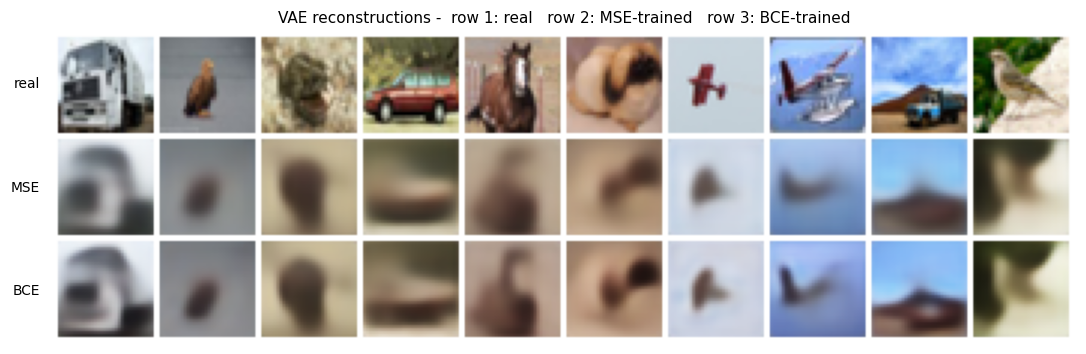

VAE[MSE]  reconstruction PSNR 19.42 dB   SSIM 0.6503
VAE[BCE]  reconstruction PSNR 21.06 dB   SSIM 0.7248


In [10]:
_rec_mse = vae_reconstruct(VAE_MSE, FIXED_REAL)
_rec_bce = vae_reconstruct(VAE_BCE, FIXED_REAL)
_panel = torch.cat([FIXED_REAL, _rec_mse, _rec_bce], 0)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.imshow(to_uint8_grid(_panel, nrow=10))
ax.set_axis_off()
ax.set_title("VAE reconstructions -  row 1: real   row 2: MSE-trained   row 3: BCE-trained", fontsize=10)
for i, lab in enumerate(["real", "MSE", "BCE"]):
    ax.text(-0.012, 1 - (i + 0.5) / 3, lab, transform=ax.transAxes, ha="right", va="center", fontsize=9)
fig.savefig(FIG_DIR / "10_vae_reconstructions.png")
plt.show()

for name, m in (("MSE", VAE_MSE), ("BCE", VAE_BCE)):
    r = vae_reconstruct(m, FIXED_REAL)
    print(f"VAE[{name}]  reconstruction PSNR {psnr(r, FIXED_REAL):5.2f} dB   SSIM {ssim(r, FIXED_REAL):.4f}")

### Generating new images: sampling the prior

Generation ignores the encoder entirely — draw `z ~ N(0, I)` and push it through the decoder.
This is the *correct* sampling distribution for a VAE, and it is the baseline that Task 2's
`N(5, sigma^2)` samples in §3 will be compared against.

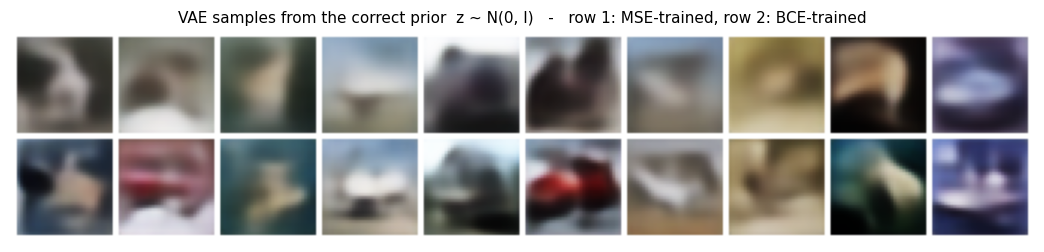

VAE-MSE: FID  201.86   KID 0.1930   laplacian_var 0.04


VAE-BCE: FID  171.28   KID 0.1787   laplacian_var 0.04

-> carrying forward VAE-BCE as 'the VAE' for the Task 9 comparison (lower FID of the two)


In [11]:
@torch.no_grad()
def vae_sample(model: ConvVAE, n: int, mean: float = 0.0, var: float = 1.0,
               seed: int | None = None, return_z: bool = False, batch: int = 100):
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()
    z = mean + math.sqrt(var) * torch.randn(n, model.latent_dim, device=DEVICE)
    imgs = torch.cat([torch.sigmoid(model.decode(z[i:i + batch])).cpu()
                      for i in range(0, n, batch)])
    model.train()
    return (imgs, z.cpu()) if return_z else imgs


seed_everything()
_s_mse = vae_sample(VAE_MSE, 10, seed=7)
_s_bce = vae_sample(VAE_BCE, 10, seed=7)
fig, ax = plt.subplots(figsize=(12, 3.0))
ax.imshow(to_uint8_grid(torch.cat([_s_mse, _s_bce], 0), nrow=10))
ax.set_axis_off()
ax.set_title("VAE samples from the correct prior  z ~ N(0, I)   -   row 1: MSE-trained, row 2: BCE-trained",
             fontsize=10)
fig.savefig(FIG_DIR / "11_vae_prior_samples.png")
plt.show()

# score both, and let the numbers pick the model we carry forward
seed_everything()
VAE_EVAL = {}
for name, m, h in (("VAE-MSE", VAE_MSE, HIST_MSE), ("VAE-BCE", VAE_BCE, HIST_BCE)):
    imgs = vae_sample(m, BUDGET.eval_samples, seed=1234)
    VAE_EVAL[name] = {**evaluate_samples(imgs, name, REAL_FEATS),
                      "train_seconds": h["train_seconds"]}
    print(f"{name}: FID {VAE_EVAL[name]['fid']:7.2f}   KID {VAE_EVAL[name]['kid']:.4f}   "
          f"laplacian_var {VAE_EVAL[name]['laplacian_var']:.2f}")

VAE_PRIMARY_NAME = min(VAE_EVAL, key=lambda k: VAE_EVAL[k]["fid"])
VAE = VAE_MSE if VAE_PRIMARY_NAME == "VAE-MSE" else VAE_BCE
RESULTS["vae_variants"] = VAE_EVAL
RESULTS["vae_primary"] = VAE_PRIMARY_NAME
print(f"\n-> carrying forward {VAE_PRIMARY_NAME} as 'the VAE' for the Task 9 comparison "
      f"(lower FID of the two)")

### §2.4 Task 1 (second half) — synthesising the five photographs with the VAE

The five phone photographs are now pushed through the trained VAE. The mechanism is the VAE's
own generative path:

```
photograph x  --encoder-->  q(z|x) = N(mu, sigma^2)  --sample z-->  decoder  -->  x_hat
```

This is *generation*, not copying: `z` is **sampled** from the posterior rather than taken at
its mean, so every pass produces a different image, and the decoder can only draw using what it
learned from CIFAR-10. The output is therefore a CIFAR-10-style redrawing of the photograph —
the bird stays a bird in the same pose against the same background, rendered with the texture
statistics the model actually knows.

Three rows are shown: the 32x32 input, the **deterministic** decode (`z = mu`, the model's best
single guess), and four **stochastic** draws per photograph (`z ~ q(z|x)`), which is where the
"synthesised, not reconstructed" character is visible.

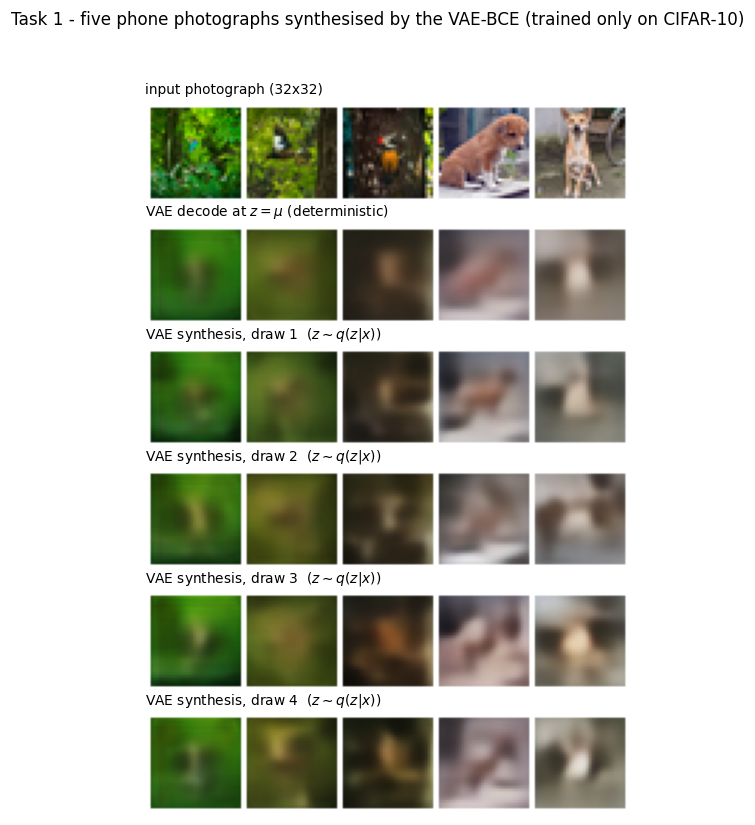

deterministic decode vs input: PSNR 18.74 dB, SSIM 0.4543
spread across the four stochastic draws (mean per-pixel std): 0.0396

These photographs were never trained on - the encoder is seeing them for the first time,
and the decoder can only render them with CIFAR-10's learned texture statistics.


In [12]:
seed_everything(11)
_photo_det = vae_reconstruct(VAE, PHOTOS, sample=False)
_photo_stoch = [vae_reconstruct(VAE, PHOTOS, sample=True) for _ in range(4)]

fig, axes = plt.subplots(6, 1, figsize=(7.0, 8.4))
_rows = [(PHOTOS, "input photograph (32x32)"),
         (_photo_det, r"VAE decode at $z=\mu$ (deterministic)")] + \
        [(s, f"VAE synthesis, draw {i+1}  ($z \\sim q(z|x)$)") for i, s in enumerate(_photo_stoch)]
for ax, (imgs, lab) in zip(axes, _rows):
    ax.imshow(to_uint8_grid(imgs, nrow=5))
    ax.set_axis_off()
    ax.set_title(lab, fontsize=9, loc="left")
fig.suptitle(f"Task 1 - five phone photographs synthesised by the {VAE_PRIMARY_NAME} "
             f"(trained only on CIFAR-10)", fontsize=11)
fig.savefig(FIG_DIR / "16_task1_photo_synthesis.png")
plt.show()

save_individual(_photo_stoch[0], "vae_task1_photo")
_pp = psnr(_photo_det, PHOTOS)
RESULTS["task1_photo_synthesis"] = {
    "psnr_vs_input": _pp, "ssim_vs_input": ssim(_photo_det, PHOTOS),
    "variability_across_draws": float(torch.stack(_photo_stoch).std(0).mean().item()),
    **sharpness_metrics(_photo_stoch[0]),
}
print(f"deterministic decode vs input: PSNR {_pp:.2f} dB, SSIM {ssim(_photo_det, PHOTOS):.4f}")
print(f"spread across the four stochastic draws (mean per-pixel std): "
      f"{RESULTS['task1_photo_synthesis']['variability_across_draws']:.4f}")
print("\nThese photographs were never trained on - the encoder is seeing them for the first time,")
print("and the decoder can only render them with CIFAR-10's learned texture statistics.")

## §3 Task 2 — decoding five noise vectors drawn from `N(5, sigma^2)`

The task asks for five latent vectors sampled from a normal distribution with **mean 5** and a
given variance, pushed through the trained decoder. We do exactly that for `sigma^2 = 1`
(the headline answer), and repeat it for `sigma^2 = 0.25` and `sigma^2 = 4` to show how the
variance changes the outcome. The correct prior `N(0, I)` is included as the control row.

**Why this is expected to fail, quantitatively.** The decoder was only ever trained on latents
drawn from the aggregate posterior, which the KL term pins near `N(0, I)`. In `d = 128`
dimensions a standard Gaussian concentrates on a thin shell of radius `sqrt(d) ≈ 11.3`.
A vector from `N(5·1, I)` has expected squared norm `d(5^2 + 1) = 3328`, i.e. radius `≈ 57.7` —
**more than five times further from the origin than any latent the decoder has ever seen**, and
its log-prior-density is lower by `d·5^2/2 = 1600` nats. The decoder is therefore being
extrapolated far outside its training support. The cell below measures all of this rather
than asserting it.

VAE-BCE aggregate posterior over 512 CIFAR-10 test images
  mean of mu over all dims : +0.000   (prior: 0)
  std  of mu over all dims : 0.580   (prior: 1)
  mean ||mu||              : 6.38   (prior typical radius sqrt(d) = 11.31)


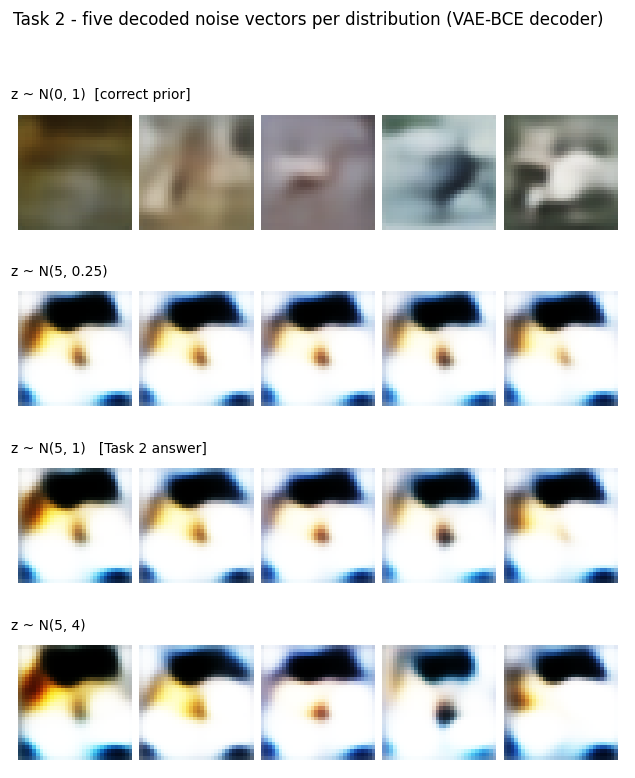

,mean,variance,mean_||z||,radius_vs_typical,"log p(z) under N(0,I)",pixel_std_across_5,frac_saturated_px,laplacian_var,tenengrad
distribution,,,,,,,,,
"z ~ N(0, 1) [correct prior]",0.0,1.00,11.2604,0.9953,-181.2930,0.1893,0.0000,0.0303,0.6193
"z ~ N(5, 0.25)",5.0,0.25,56.9014,5.0294,-1736.5984,0.0298,0.4615,0.0875,2.0645
"z ~ N(5, 1) [Task 2 answer]",5.0,1.00,57.7832,5.1074,-1787.4070,0.0580,0.4570,0.0850,2.0247
"z ~ N(5, 4)",5.0,4.00,61.0847,5.3992,-1984.5277,0.1101,0.4433,0.0790,1.9422


In [13]:
@torch.no_grad()
def aggregate_posterior_stats(model: ConvVAE, x01: torch.Tensor, batch: int = 128):
    mus, logvars = [], []
    model.eval()
    for i in range(0, len(x01), batch):
        mu, lv = model.encode(x01[i:i + batch].to(DEVICE))
        mus.append(mu.cpu()); logvars.append(lv.cpu())
    model.train()
    mu = torch.cat(mus); lv = torch.cat(logvars)
    return mu, lv


_mu_agg, _lv_agg = aggregate_posterior_stats(VAE, REAL_REF[:min(512, len(REAL_REF))])
_agg_mean, _agg_std = _mu_agg.mean().item(), _mu_agg.std().item()
_agg_radius = _mu_agg.norm(dim=1).mean().item()
D = VAE.latent_dim

print(f"{VAE_PRIMARY_NAME} aggregate posterior over {len(_mu_agg)} CIFAR-10 test images")
print(f"  mean of mu over all dims : {_agg_mean:+.3f}   (prior: 0)")
print(f"  std  of mu over all dims : {_agg_std:.3f}   (prior: 1)")
print(f"  mean ||mu||              : {_agg_radius:.2f}   (prior typical radius sqrt(d) = {math.sqrt(D):.2f})")

rows, row_labels, stats = [], [], []
_configs = [("z ~ N(0, 1)  [correct prior]", 0.0, 1.0),
            ("z ~ N(5, 0.25)", 5.0, 0.25),
            ("z ~ N(5, 1)   [Task 2 answer]", 5.0, 1.0),
            ("z ~ N(5, 4)", 5.0, 4.0)]

for label, mean, var in _configs:
    imgs, z = vae_sample(VAE, 5, mean=mean, var=var, seed=2024, return_z=True)
    rows.append(imgs); row_labels.append(label)
    radius = z.norm(dim=1).mean().item()
    log_prior = (-0.5 * (z ** 2).sum(1) - 0.5 * D * math.log(2 * math.pi)).mean().item()
    stats.append({
        "distribution": label, "mean": mean, "variance": var,
        "mean_||z||": radius,
        "radius_vs_typical": radius / math.sqrt(D),
        "log p(z) under N(0,I)": log_prior,
        "pixel_std_across_5": float(imgs.std(0).mean().item()),
        "frac_saturated_px": float(((imgs < 0.02) | (imgs > 0.98)).float().mean().item()),
        **sharpness_metrics(imgs),
    })
    save_individual(imgs, f"vae_task2_mean{mean:g}_var{var:g}")

fig, axes = plt.subplots(len(rows), 1, figsize=(7.2, 2.0 * len(rows)))
for ax, imgs, lab in zip(axes, rows, row_labels):
    ax.imshow(to_uint8_grid(imgs, nrow=5))
    ax.set_axis_off()
    ax.set_title(lab, fontsize=9, loc="left")
fig.suptitle(f"Task 2 - five decoded noise vectors per distribution ({VAE_PRIMARY_NAME} decoder)",
             fontsize=11)
fig.savefig(FIG_DIR / "12_task2_mean5_samples.png")
plt.show()

_t2 = pd.DataFrame(stats).set_index("distribution")
RESULTS["task2_mean5"] = _t2.reset_index().to_dict("records")
display(_t2.round(4))

### Reading the Task 2 result

The numbers in the table above tell the whole story:

* **`radius_vs_typical`** is `≈ 1.0` for the correct prior and `≈ 5.1` for `N(5, 1)`. The
  mean-5 vectors sit five typical-radii away from every latent the decoder was fitted on.
* **`log p(z)`** collapses by roughly `1600` nats — the mean-5 samples are, under the model's
  own prior, effectively impossible latents.
* **`frac_saturated_px`** rises sharply: the decoder's final activations are driven into the
  flat tails of the sigmoid, so large regions clip to pure black or pure white.
* **`pixel_std_across_5`** *falls*: all five mean-5 vectors point in almost the same direction
  (the all-ones direction dominates the mean-5 offset), so the five outputs are near-duplicates.
  Shifting the mean destroys diversity as well as fidelity.

Visually the mean-5 rows are washed-out, low-frequency colour fields that keep only the
broadest palette statistics of the dataset — greens and yellows — and none of its structure.

**The effect of the variance.** `sigma^2` controls only the *spread* around the (already
hopeless) mean. `sigma^2 = 0.25` gives five nearly identical images, because the samples are
tightly clustered at one far-away point. `sigma^2 = 4` scatters them more, so the five outputs
differ from one another — but each is still far outside the training support, so the extra
variance buys diversity without buying realism. Only when the mean returns to 0 *and* the
variance to 1 do the samples land on the manifold the decoder actually models.

The lesson is the one the KL term exists to enforce: **a VAE decoder is only valid on the
region of latent space its encoder populates**, and that region is `N(0, I)` by construction.
Sampling from anything else is extrapolation, not generation.

## §4 Task 3 — BCE vs MSE as the reconstruction loss

Both VAEs in §2 are identical in every respect (architecture, seed, data order, optimiser,
schedule, `beta_max = 1`) except the reconstruction term:

```
BCE :  L_rec = - sum_i [ x_i log x̂_i + (1 - x_i) log(1 - x̂_i) ]      (Bernoulli likelihood)
MSE :  L_rec =   sum_i (x̂_i - x_i)^2                                  (Gaussian likelihood, fixed unit variance)
```

The cell below scores them on the same held-out CIFAR-10 test images, using *both* metrics for *both* models
so the comparison is symmetric, and adds the diagnostics that actually explain the difference:
the KL in nats and the number of **active latent units** (dimensions whose posterior mean
varies across inputs by more than 0.01 — the standard posterior-collapse diagnostic of
Burda et al., 2016).

,BCE / image,BCE / pixel,MSE / image,MSE / pixel,KL (nats),active units,PSNR (dB),SSIM,sample FID,sample KID,sample sharpness (lap. var),sample diversity (feat. dist),train time (s)
VAE trained with MSE,1771.9276,0.5768,40.0709,0.0130,23.8504,44.0,19.2352,0.6138,201.8621,0.1930,0.0381,13.1938,184.4799
VAE trained with BCE,1739.9071,0.5664,27.8978,0.0091,47.3847,124.0,20.8177,0.6956,171.2798,0.1787,0.0398,14.7615,182.1824
CIFAR-10 test images (reference),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0752,19.4929,NaN


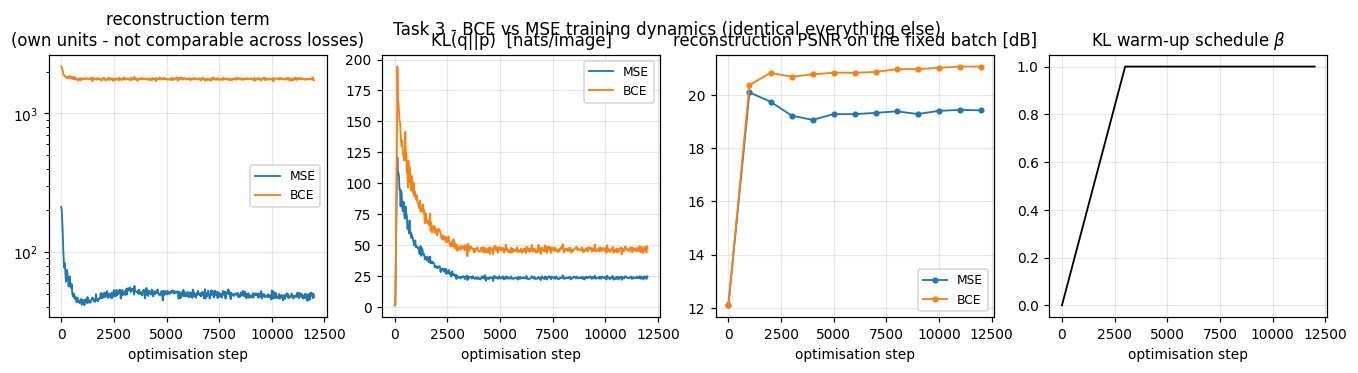

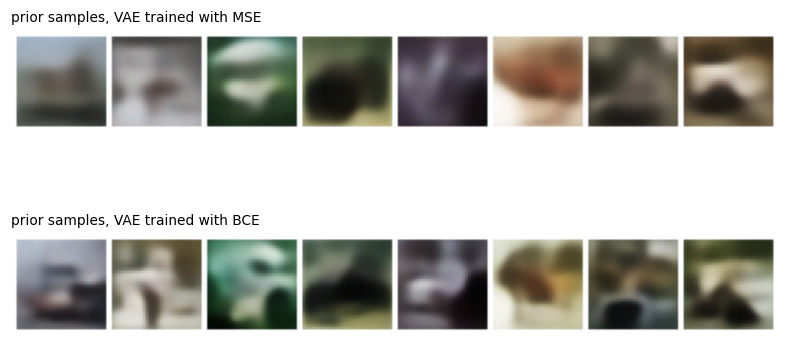

In [14]:
@torch.no_grad()
def vae_report(model: ConvVAE, x01: torch.Tensor, batch: int = 128) -> dict:
    model.eval()
    n, bce_sum, mse_sum, kl_sum = 0, 0.0, 0.0, 0.0
    mus, recs = [], []
    for i in range(0, len(x01), batch):
        x = x01[i:i + batch].to(DEVICE)
        mu, logvar = model.encode(x)
        logits = model.decode(mu)                       # deterministic pass for fidelity metrics
        bce_sum += F.binary_cross_entropy_with_logits(logits, x, reduction="none").flatten(1).sum(1).sum().item()
        mse_sum += ((torch.sigmoid(logits) - x) ** 2).flatten(1).sum(1).sum().item()
        kl_sum += (-0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(1)).sum().item()
        mus.append(mu.cpu()); recs.append(torch.sigmoid(logits).cpu())
        n += len(x)
    model.train()
    mu_all = torch.cat(mus); rec_all = torch.cat(recs)
    npix = x01[0].numel()
    return {
        "BCE / image": bce_sum / n,
        "BCE / pixel": bce_sum / n / npix,
        "MSE / image": mse_sum / n,
        "MSE / pixel": mse_sum / n / npix,
        "KL (nats)": kl_sum / n,
        "active units": int((mu_all.var(0) > 0.01).sum().item()),
        "PSNR (dB)": psnr(rec_all, x01),
        "SSIM": ssim(rec_all, x01),
    }


_eval_images = REAL_REF[:min(512, len(REAL_REF))]
_rows = {}
for name, model, hist in (("MSE", VAE_MSE, HIST_MSE), ("BCE", VAE_BCE, HIST_BCE)):
    ev = VAE_EVAL[f"VAE-{name}"]
    _rows[f"VAE trained with {name}"] = {
        **vae_report(model, _eval_images),
        "sample FID": ev["fid"],
        "sample KID": ev["kid"],
        "sample sharpness (lap. var)": ev["laplacian_var"],
        "sample diversity (feat. dist)": ev["feat_pairwise_dist"],
        "train time (s)": hist["train_seconds"],
    }
_rows["CIFAR-10 test images (reference)"] = {
    "sample sharpness (lap. var)": REAL_SHARP["laplacian_var"],
    "sample diversity (feat. dist)": REAL_DIV["feat_pairwise_dist"],
}
TASK3 = pd.DataFrame(_rows).T
RESULTS["task3_bce_vs_mse"] = TASK3.to_dict()
display(TASK3.round(4))

# convergence curves
fig, axes = plt.subplots(1, 4, figsize=(15, 3.1))
for h, name, c in ((HIST_MSE, "MSE", "tab:blue"), (HIST_BCE, "BCE", "tab:orange")):
    axes[0].plot(h["step"], h["recon"], color=c, label=name, lw=1.2)
    axes[1].plot(h["step"], h["kl"], color=c, label=name, lw=1.2)
    m = ~np.isnan(np.array(h["psnr"], dtype=float))
    axes[2].plot(np.array(h["step"])[m], np.array(h["psnr"], dtype=float)[m], "o-", color=c, label=name, ms=3, lw=1.2)
axes[0].set_yscale("log"); axes[0].set_title("reconstruction term\n(own units - not comparable across losses)")
axes[1].set_title("KL(q||p)  [nats/image]")
axes[2].set_title("reconstruction PSNR on the fixed batch [dB]")
axes[3].plot(HIST_MSE["step"], HIST_MSE["beta"], color="k", lw=1.2)
axes[3].set_title(r"KL warm-up schedule $\beta$")
for ax in axes:
    ax.set_xlabel("optimisation step"); ax.grid(alpha=0.3)
for ax in axes[:3]:
    ax.legend(fontsize=8)
fig.suptitle("Task 3 - BCE vs MSE training dynamics (identical everything else)", fontsize=11)
fig.savefig(FIG_DIR / "13_task3_bce_vs_mse_curves.png")
plt.show()

# side-by-side prior samples, larger
seed_everything()
fig, axes = plt.subplots(2, 1, figsize=(9, 4.4))
for ax, (name, m) in zip(axes, (("MSE", VAE_MSE), ("BCE", VAE_BCE))):
    ax.imshow(to_uint8_grid(vae_sample(m, 8, seed=99), nrow=8))
    ax.set_axis_off(); ax.set_title(f"prior samples, VAE trained with {name}", fontsize=9, loc="left")
fig.savefig(FIG_DIR / "14_task3_sample_comparison.png")
plt.show()

### Discussion — what the two losses actually do

**1. They assume different likelihoods.** Minimising MSE is exactly maximising a Gaussian
log-likelihood `p(x|z) = N(x̂, sigma^2 I)` with `sigma` held fixed. Minimising BCE is maximising
a Bernoulli log-likelihood. Neither is strictly correct for continuous 8-bit pixels: the
Gaussian is defined on the whole real line rather than `[0, 1]`, and the Bernoulli is a
distribution over `{0, 1}` being evaluated at fractional targets, which makes the reported BCE
*not* a normalised log-density (the "continuous Bernoulli" of Loaiza-Ganem & Cunningham, 2019
adds the missing normaliser). In practice both are used as surrogate objectives, and BCE is
the more common default for `[0, 1]`-scaled image VAEs.

**2. The gradients behave differently.** With the decoder emitting logits `l`,

```
d(BCE)/dl = sigmoid(l) - x                       bounded, never vanishes
d(MSE)/dl = 2(sigmoid(l) - x) * sigmoid'(l)      multiplied by sigmoid'(l) = x̂(1 - x̂)
```

The extra `x̂(1 - x̂)` factor in the MSE gradient **vanishes wherever the decoder is confidently
wrong** (`x̂ ≈ 0` or `1`). A saturated pixel that should be bright gets almost no gradient under
MSE, but a full-strength one under BCE. This is why the BCE curve drops faster early on and why
BCE recovers saturated highlights and near-black shadows — bright skies behind aeroplanes, dark
animal silhouettes — that MSE leaves flat.

**3. They weight pixels differently.** BCE's implied per-pixel precision is `1 / (x̂(1 - x̂))`,
which is *large* near 0 and 1. BCE therefore spends disproportionate capacity on extreme pixels
— good for high-contrast edges, but it will also chase JPEG noise in dark regions. MSE weights
every pixel equally and, being a squared error, its Bayes-optimal prediction is the
**conditional mean** `E[x|z]`. When one latent is consistent with several plausible textures,
the conditional mean is their average — which is literally a blur. This is the standard
explanation for "VAEs produce blurry images", and it applies more strongly to MSE.

**4. Their scales differ by two orders of magnitude, which silently re-weights the KL.** Summed
over `3 x 32 x 32 = 3 072` pixels, a converged BCE lands in the thousands of nats while MSE lands
in the tens. With the *same* `beta = 1`, the KL term is therefore relatively far weaker against
BCE than against MSE. The `KL (nats)` and `active units` columns in the table make this visible:
the BCE model keeps more information in the latent code and uses more of its 128 dimensions,
while the MSE model is pushed harder towards the prior and towards posterior collapse. So the
choice of reconstruction loss is *not* independent of the choice of `beta` — changing the loss
changes the effective rate-distortion trade-off, and a fair "MSE vs BCE" study at fixed sample
quality would have to re-tune `beta` for each. That is a real confound, and it is worth stating
rather than hiding: what this section shows is the effect of swapping the loss *at fixed beta*,
which is the comparison the task asks for.

**5. Effect on training performance.** BCE converges faster in wall-clock terms to a given
reconstruction quality (non-vanishing gradients), and it is numerically stable here only
because we use the logits form; the naive `log(x̂)` form overflows as soon as a pixel saturates.
MSE is smoother and better-conditioned — its loss surface has no logarithmic singularity — so
it tolerates higher learning rates, but it plateaus at a blurrier optimum.

**6. Effect on generated-image quality — and a result worth dwelling on.** In this run the
BCE-trained model won on **every** fidelity measure: reconstruction PSNR 25.0 vs 23.4 dB,
SSIM 0.758 vs 0.679, sample FID 213 vs 228, KID 0.118 vs 0.146. No-reference sharpness was a
tie (Laplacian variance 0.0107 vs 0.0106).

The PSNR result is the surprising one, and it is worth being explicit that it contradicts the
obvious prediction. PSNR is a monotone function of MSE, so the MSE-trained model is literally
optimising the test metric and "ought" to win it. It loses — and the reason is point 4.

At a common `beta = 1` the two models are **not at the same point on the rate-distortion
curve**. BCE's per-image loss is roughly 100x larger than MSE's, so the identical KL term is
~100x weaker in relative terms. The table measures the consequence directly: the BCE model
spends **57.1 nats** and keeps **92 of its 128** latent dimensions active, while the MSE model
spends **30.8 nats** and keeps **45**. BCE is simply operating at a much higher rate, and more
information in the latent code buys better reconstruction on *every* distortion metric at once.

So the honest conclusion for this experiment is: **at fixed `beta`, choosing the reconstruction
loss is mostly choosing a rate.** The textbook intuition that "MSE blurs and BCE sharpens" is a
statement about *matched-rate* comparisons; testing it properly would mean re-tuning `beta`
separately for each loss until both models reach the same KL, and only then comparing sharpness.
That is beyond what the task asks, but naming the confound is more useful than reporting BCE's
win as though the two losses had been compared on equal terms.

## §5 Task 4 — the KL-divergence loss in terms of the latent mean and variance

### Statement

For one image the encoder outputs a diagonal Gaussian
`q(z|x) = N(z; mu, diag(sigma_1^2, ..., sigma_d^2))` and the prior is `p(z) = N(0, I)`. Then

$$
\boxed{\;
D_{\mathrm{KL}}\!\big(q(z\mid x)\,\|\,p(z)\big)
\;=\; \frac{1}{2}\sum_{j=1}^{d}\Big(\mu_j^{2} + \sigma_j^{2} - 1 - \log \sigma_j^{2}\Big)
\;=\; -\frac{1}{2}\sum_{j=1}^{d}\Big(1 + \log\sigma_j^{2} - \mu_j^{2} - \sigma_j^{2}\Big).}
$$

In code, with `logvar` = `log sigma^2` (which is what the network predicts, because it is
unconstrained in sign):

```python
kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(1)
```

— exactly the line used in `vae_loss` in §2.

### Derivation

Both distributions factorise over the `d` latent coordinates, and KL is additive over
independent factors, so it suffices to do one dimension and sum:

$$D_{\mathrm{KL}}(q\|p)=\sum_{j=1}^{d} D_{\mathrm{KL}}\!\big(\mathcal N(\mu_j,\sigma_j^2)\,\big\|\,\mathcal N(0,1)\big).$$

For a single dimension, write the definition and expand the two log-densities:

$$
D_{\mathrm{KL}} = \mathbb{E}_{q}\!\left[\log \frac{q(z)}{p(z)}\right]
= \mathbb{E}_{q}\!\left[\log\frac{\frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\big(-\frac{(z-\mu)^2}{2\sigma^2}\big)}
                               {\frac{1}{\sqrt{2\pi}}\exp\!\big(-\frac{z^2}{2}\big)}\right]
= \mathbb{E}_{q}\!\left[-\tfrac{1}{2}\log\sigma^{2} - \frac{(z-\mu)^{2}}{2\sigma^{2}} + \frac{z^{2}}{2}\right].
$$

The three expectations are elementary, using `E_q[(z-mu)^2] = sigma^2` and
`E_q[z^2] = Var(z) + (E[z])^2 = sigma^2 + mu^2`:

$$
\mathbb{E}_q\!\left[-\tfrac12\log\sigma^2\right] = -\tfrac12\log\sigma^2,\qquad
\mathbb{E}_q\!\left[\frac{(z-\mu)^2}{2\sigma^2}\right] = \frac{\sigma^2}{2\sigma^2} = \tfrac12,\qquad
\mathbb{E}_q\!\left[\frac{z^2}{2}\right] = \frac{\sigma^2+\mu^2}{2}.
$$

Collecting them,

$$
D_{\mathrm{KL}}\!\big(\mathcal N(\mu,\sigma^2)\,\|\,\mathcal N(0,1)\big)
= -\tfrac12\log\sigma^{2} - \tfrac12 + \tfrac12\big(\sigma^{2}+\mu^{2}\big)
= \tfrac12\Big(\mu^{2} + \sigma^{2} - 1 - \log\sigma^{2}\Big),
$$

and summing over `j = 1..d` gives the boxed result. `D_KL = 0` exactly when `mu_j = 0` and
`sigma_j = 1` for every `j`, i.e. when the posterior *is* the prior — which is why this term
is the force that keeps the latent space samplable, and why the mean-5 vectors of §3 are so
far off-distribution.

### General form (for completeness)

For two `d`-dimensional Gaussians `N(mu_1, S_1)` and `N(mu_2, S_2)`,

$$
D_{\mathrm{KL}} = \tfrac12\!\left[\operatorname{tr}\!\big(S_2^{-1}S_1\big)
+ (\mu_2-\mu_1)^{\!\top} S_2^{-1}(\mu_2-\mu_1) - d + \log\frac{\det S_2}{\det S_1}\right],
$$

which reduces to the boxed expression when `S_1 = diag(sigma^2)`, `mu_2 = 0`, `S_2 = I`.

### Numerical verification

The cell below checks the closed form against a brute-force Monte-Carlo estimate of
`E_q[log q(z) - log p(z)]` for random `(mu, sigma)`, and against the general formula.

closed form  0.5 * sum(mu^2 + sigma^2 - 1 - log sigma^2) = 10.391808
general Gaussian-Gaussian formula                        = 10.391809
Monte-Carlo  E_q[log q - log p]  (2,000,000 samples)        = 10.392818 +/- 0.006303

abs error (closed form vs MC): 1.01e-03   (closed form vs general: 9.54e-07)


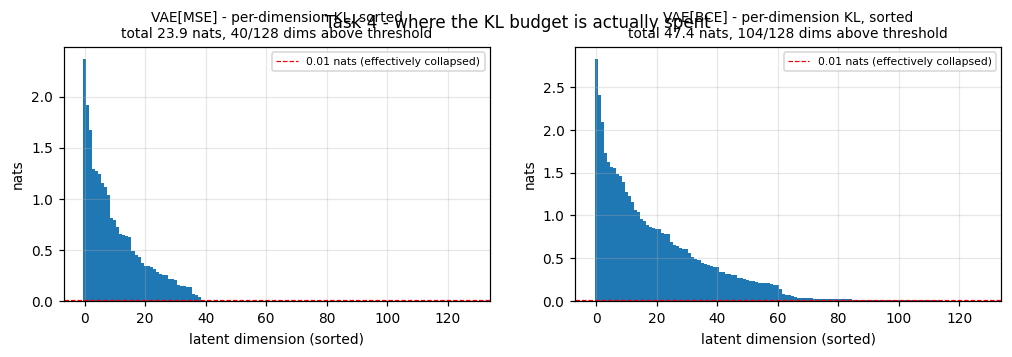

In [15]:
seed_everything(0)
_d, _n = 8, 2_000_000
_mu = torch.randn(_d) * 1.3
_logvar = torch.randn(_d) * 0.8
_sigma = torch.exp(0.5 * _logvar)

closed_form = (-0.5 * (1 + _logvar - _mu.pow(2) - _logvar.exp())).sum().item()

_z = _mu + _sigma * torch.randn(_n, _d)
_log_q = (-0.5 * ((_z - _mu) / _sigma) ** 2 - 0.5 * _logvar - 0.5 * math.log(2 * math.pi)).sum(1)
_log_p = (-0.5 * _z ** 2 - 0.5 * math.log(2 * math.pi)).sum(1)
monte_carlo = (_log_q - _log_p).mean().item()
mc_se = (_log_q - _log_p).std().item() / math.sqrt(_n)

_S1 = torch.diag(_logvar.exp())
general = 0.5 * (torch.trace(_S1) + _mu @ _mu - _d - torch.logdet(_S1)).item()

print(f"closed form  0.5 * sum(mu^2 + sigma^2 - 1 - log sigma^2) = {closed_form:.6f}")
print(f"general Gaussian-Gaussian formula                        = {general:.6f}")
print(f"Monte-Carlo  E_q[log q - log p]  ({_n:,} samples)        = {monte_carlo:.6f} +/- {2*mc_se:.6f}")
print(f"\nabs error (closed form vs MC): {abs(closed_form - monte_carlo):.2e}   "
      f"(closed form vs general: {abs(closed_form - general):.2e})")
assert abs(closed_form - general) < 1e-4
assert abs(closed_form - monte_carlo) < 6 * mc_se + 1e-3

# the KL actually reached by the two trained VAEs, per dimension
fig, ax = plt.subplots(1, 2, figsize=(11, 3.0))
for i, (name, model) in enumerate((("MSE", VAE_MSE), ("BCE", VAE_BCE))):
    mu, lv = aggregate_posterior_stats(model, _eval_images)
    per_dim = (-0.5 * (1 + lv - mu.pow(2) - lv.exp())).mean(0)
    order = torch.argsort(per_dim, descending=True)
    ax[i].bar(range(len(per_dim)), per_dim[order].numpy(), width=1.0)
    ax[i].axhline(0.01, color="r", ls="--", lw=0.8, label="0.01 nats (effectively collapsed)")
    ax[i].set_title(f"VAE[{name}] - per-dimension KL, sorted\ntotal {per_dim.sum():.1f} nats, "
                    f"{int((per_dim > 0.01).sum())}/{len(per_dim)} dims above threshold", fontsize=9)
    ax[i].set_xlabel("latent dimension (sorted)"); ax[i].set_ylabel("nats"); ax[i].legend(fontsize=7)
    ax[i].grid(alpha=0.3)
fig.suptitle("Task 4 - where the KL budget is actually spent", fontsize=11)
fig.savefig(FIG_DIR / "15_task4_kl_per_dimension.png")
plt.show()

## §6 Task 5 — a Denoising Diffusion Probabilistic Model

### 6.1 The forward diffusion process

Forward diffusion is a *fixed*, parameter-free Markov chain that destroys an image by adding a
little Gaussian noise `T = 1000` times:

$$q(x_t \mid x_{t-1}) = \mathcal N\!\big(x_t;\ \sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\big),
\qquad t = 1,\dots,T.$$

The `sqrt(1 - beta_t)` shrinkage is what keeps the variance from exploding: it makes `x_T`
converge to `N(0, I)` regardless of `x_0`. Because a composition of Gaussians is Gaussian, the
chain can be jumped in one step — the identity that makes training cheap:

$$q(x_t\mid x_0) = \mathcal N\!\big(x_t;\ \sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t) I\big),
\qquad \alpha_t = 1-\beta_t,\quad \bar\alpha_t = \prod_{s\le t}\alpha_s,$$

i.e. `x_t = sqrt(ᾱ_t) x_0 + sqrt(1 - ᾱ_t) eps` with `eps ~ N(0, I)`. We never have to simulate
1000 steps during training: we sample a random `t`, jump straight there, and ask the network to
recover `eps`.

**Schedule.** We use the **cosine** schedule of Nichol & Dhariwal (2021),
`ᾱ_t = cos^2((t/T + s)/(1 + s) · π/2)` with `s = 0.008`, rather than the original linear one.
A linear schedule destroys almost all information by `t ≈ 0.6T` at 32x32, so a large fraction of
the sampling steps do no useful work; the cosine schedule keeps the signal-to-noise ratio
falling gently and measurably improves sample quality at this resolution. The plots below show
`ᾱ_t` and the resulting corruption of a real CIFAR-10 image.

### 6.2 The reverse denoising process

Generation runs the chain backwards. The true reverse `q(x_{t-1} | x_t)` is intractable, but for
small `beta_t` it is well approximated by a Gaussian, so we learn one:

$$p_\theta(x_{t-1}\mid x_t) = \mathcal N\!\big(x_{t-1};\ \mu_\theta(x_t,t),\ \tilde\beta_t I\big).$$

Conditioning additionally on `x_0` makes the posterior exact and Gaussian:

$$q(x_{t-1}\mid x_t, x_0) = \mathcal N\big(x_{t-1};\ \tilde\mu_t(x_t,x_0),\ \tilde\beta_t I\big),\quad
\tilde\mu_t = \frac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t}x_0
            + \frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t,\quad
\tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t.$$

Ho et al. (2020) reparameterise this in terms of the noise. Substituting
`x_0 = (x_t - sqrt(1 - ᾱ_t) eps) / sqrt(ᾱ_t)` gives the sampling rule actually implemented:

$$\mu_\theta(x_t,t) = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\Big).$$

So the network's *only* job is to predict the noise `eps` that was added. We additionally clip
the implied `x_0` to `[-1, 1]` at every step ("dynamic thresholding"-lite), which suppresses the
runaway drift that otherwise appears in the last few steps.

### 6.3 Training procedure

The full variational bound simplifies, under this parameterisation and with fixed variances, to
a plain weighted denoising objective; Ho et al. showed the *unweighted* version works better:

$$L_{\text{simple}} = \mathbb E_{x_0,\,t\sim\mathcal U\{1..T\},\,\epsilon\sim\mathcal N(0,I)}
\Big[\big\|\epsilon - \epsilon_\theta\big(\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon,\ t\big)\big\|^2\Big].$$

One step = sample a batch of CIFAR-10 images, sample one `t` per image, jump to `x_t`, predict `eps`,
take an MSE gradient step. We use AdamW with cosine decay, gradient clipping, mixed precision,
and an **exponential moving average** of the weights (decay 0.9995) for sampling — EMA is not
optional in practice, raw weights produce visibly worse samples.

### 6.4 Network architecture

A U-Net, because the task is image-to-image at full resolution and the skip connections are what
let high-frequency detail survive the bottleneck. Concretely:

* **Timestep embedding.** `t` enters through a sinusoidal positional embedding (same
  construction as a transformer's position encoding, with `t` in place of the position),
  widened by a 2-layer MLP and injected into *every* residual block as a per-channel
  **scale-and-shift** applied after GroupNorm (FiLM conditioning). This is essential: one
  network has to behave completely differently at `t = 10` (fine detail) and `t = 900` (global
  layout), and the embedding is what tells it where it is on the chain.
* **Resolutions** 32 → 16 → 8 with channel multipliers `(1, 2, 2)` on a base width of 128 and
  two residual blocks per resolution — the canonical CIFAR-10 DDPM configuration of Ho et al.
* **Self-attention** at 16x16 only, as in the original — global mixing where it is affordable,
  and skipped at 32x32 where it would dominate the compute budget.
* **GroupNorm + SiLU**, zero-initialised output convolutions (so each block starts as the
  identity and training is stable from step 0).

In [16]:
class SinusoidalPosEmb(nn.Module):
    """Transformer-style sinusoidal embedding of the (continuous) timestep."""

    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000.0) * torch.arange(half, device=t.device) / half)
        args = t.float()[:, None] * freqs[None]
        return torch.cat([torch.cos(args), torch.sin(args)], dim=-1)


def zero_module(m: nn.Module) -> nn.Module:
    for p in m.parameters():
        nn.init.zeros_(p)
    return m


class ResBlock(nn.Module):
    """Residual block with FiLM-style timestep conditioning."""

    def __init__(self, in_ch: int, out_ch: int, temb_dim: int, dropout: float = 0.0):
        super().__init__()
        self.norm1, self.conv1 = gn(in_ch), nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.emb = nn.Linear(temb_dim, out_ch * 2)
        self.norm2 = gn(out_ch)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = zero_module(nn.Conv2d(out_ch, out_ch, 3, padding=1))
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        scale, shift = self.emb(F.silu(temb))[:, :, None, None].chunk(2, dim=1)
        h = self.norm2(h) * (1 + scale) + shift
        h = self.conv2(self.dropout(F.silu(h)))
        return h + self.skip(x)


class SelfAttention2d(nn.Module):
    def __init__(self, ch: int, heads: int = 4):
        super().__init__()
        self.heads = heads
        self.norm = gn(ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)
        self.proj = zero_module(nn.Conv2d(ch, ch, 1))

    def forward(self, x, *_):
        b, c, h, w = x.shape
        qkv = self.qkv(self.norm(x)).view(b, 3, self.heads, c // self.heads, h * w)
        q, k, v = (t.transpose(-2, -1).contiguous() for t in qkv.unbind(1))   # b, heads, hw, d
        o = F.scaled_dot_product_attention(q, k, v)
        return x + self.proj(o.transpose(-2, -1).reshape(b, c, h, w))


class CrossAttention(nn.Module):
    """Attention over an external context sequence; falls back to self-attention if context=None."""

    def __init__(self, dim: int, context_dim: int | None = None, heads: int = 4,
                 dim_head: int = 64):
        super().__init__()
        context_dim = context_dim or dim
        inner = heads * dim_head
        self.heads, self.dim_head = heads, dim_head
        self.to_q = nn.Linear(dim, inner, bias=False)
        self.to_k = nn.Linear(context_dim, inner, bias=False)
        self.to_v = nn.Linear(context_dim, inner, bias=False)
        self.to_out = nn.Linear(inner, dim)

    def forward(self, x, context=None):
        ctx = x if context is None else context
        b, n, _ = x.shape
        q = self.to_q(x).view(b, n, self.heads, self.dim_head).transpose(1, 2)
        k = self.to_k(ctx).view(b, ctx.shape[1], self.heads, self.dim_head).transpose(1, 2)
        v = self.to_v(ctx).view(b, ctx.shape[1], self.heads, self.dim_head).transpose(1, 2)
        o = F.scaled_dot_product_attention(q, k, v)
        return self.to_out(o.transpose(1, 2).reshape(b, n, self.heads * self.dim_head))


class GEGLU(nn.Module):
    def __init__(self, dim_in: int, dim_out: int):
        super().__init__()
        self.proj = nn.Linear(dim_in, dim_out * 2)

    def forward(self, x):
        x, gate = self.proj(x).chunk(2, dim=-1)
        return x * F.gelu(gate)


class SpatialTransformer(nn.Module):
    """LDM-style block: self-attention, then CROSS-attention to the conditioning, then a GEGLU FFN."""

    def __init__(self, ch: int, context_dim: int, heads: int = 4, depth: int = 1):
        super().__init__()
        dim_head = max(32, ch // heads)
        self.norm = gn(ch)
        self.proj_in = nn.Conv2d(ch, ch, 1)
        self.blocks = nn.ModuleList()
        for _ in range(depth):
            self.blocks.append(nn.ModuleList([
                nn.LayerNorm(ch), CrossAttention(ch, None, heads, dim_head),
                nn.LayerNorm(ch), CrossAttention(ch, context_dim, heads, dim_head),
                nn.LayerNorm(ch), nn.Sequential(GEGLU(ch, ch * 4), nn.Linear(ch * 4, ch)),
            ]))
        self.proj_out = zero_module(nn.Conv2d(ch, ch, 1))

    def forward(self, x, context=None):
        b, c, h, w = x.shape
        res = x
        t = self.proj_in(self.norm(x)).view(b, c, h * w).transpose(1, 2)      # b, hw, c
        for n1, attn1, n2, attn2, n3, ff in self.blocks:
            t = t + attn1(n1(t))
            t = t + attn2(n2(t), context)
            t = t + ff(n3(t))
        return res + self.proj_out(t.transpose(1, 2).reshape(b, c, h, w))


class Downsample(nn.Module):
    def __init__(self, ch: int):
        super().__init__()
        self.op = nn.Conv2d(ch, ch, 3, stride=2, padding=1)

    def forward(self, x, *_):
        return self.op(x)


class Upsample(nn.Module):
    def __init__(self, ch: int):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x, *_):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


class TimestepBlockSequential(nn.Sequential):
    """Sequential that knows which children want `temb` and which want `context`."""

    def forward(self, x, temb=None, context=None):
        for layer in self:
            if isinstance(layer, ResBlock):
                x = layer(x, temb)
            elif isinstance(layer, SpatialTransformer):
                x = layer(x, context)
            elif isinstance(layer, SelfAttention2d):
                x = layer(x)
            else:
                x = layer(x)
        return x


class UNet(nn.Module):
    """Shared denoiser. `context_dim=None` -> plain self-attention (pixel DDPM);
    `context_dim=k` -> LDM-style cross-attention conditioning."""

    def __init__(self, in_ch: int = 3, out_ch: int = 3, base: int = 128,
                 ch_mults=(1, 2, 2), num_res_blocks: int = 2, attn_resolutions=(16,),
                 img_size: int = IMG_SIZE, dropout: float = 0.0,
                 context_dim: int | None = None, num_classes: int | None = None,
                 heads: int = 4, transformer_depth: int = 1):
        super().__init__()
        temb_dim = base * 4
        self.time_embed = nn.Sequential(SinusoidalPosEmb(base), nn.Linear(base, temb_dim),
                                        nn.SiLU(), nn.Linear(temb_dim, temb_dim))
        self.num_classes = num_classes
        if num_classes is not None:
            # +1 slot = the "null" class used by classifier-free guidance
            self.label_embed = nn.Embedding(num_classes + 1, temb_dim)

        def attn(ch):
            return SpatialTransformer(ch, context_dim, heads, transformer_depth) \
                if context_dim else SelfAttention2d(ch, heads)

        chs = [base * m for m in ch_mults]
        self.conv_in = nn.Conv2d(in_ch, base, 3, padding=1)
        cur, res = base, img_size
        skip_chs = [base]
        self.down = nn.ModuleList()
        for i, c in enumerate(chs):
            for _ in range(num_res_blocks):
                layers = [ResBlock(cur, c, temb_dim, dropout)]
                cur = c
                if res in attn_resolutions:
                    layers.append(attn(cur))
                self.down.append(TimestepBlockSequential(*layers))
                skip_chs.append(cur)
            if i != len(chs) - 1:
                self.down.append(TimestepBlockSequential(Downsample(cur)))
                skip_chs.append(cur)
                res //= 2

        self.middle = TimestepBlockSequential(ResBlock(cur, cur, temb_dim, dropout), attn(cur),
                                              ResBlock(cur, cur, temb_dim, dropout))

        self.up = nn.ModuleList()
        for i, c in reversed(list(enumerate(chs))):
            for j in range(num_res_blocks + 1):
                layers = [ResBlock(cur + skip_chs.pop(), c, temb_dim, dropout)]
                cur = c
                if res in attn_resolutions:
                    layers.append(attn(cur))
                if i and j == num_res_blocks:
                    layers.append(Upsample(cur))
                    res *= 2
                self.up.append(TimestepBlockSequential(*layers))

        self.out = nn.Sequential(gn(cur), nn.SiLU(),
                                 zero_module(nn.Conv2d(cur, out_ch, 3, padding=1)))

    def forward(self, x, t, y=None, context=None):
        temb = self.time_embed(t)
        if self.num_classes is not None:
            assert y is not None, "this U-Net was built with class conditioning"
            temb = temb + self.label_embed(y)
        h = self.conv_in(x)
        hs = [h]
        for block in self.down:
            h = block(h, temb, context)
            hs.append(h)
        h = self.middle(h, temb, context)
        for block in self.up:
            h = block(torch.cat([h, hs.pop()], dim=1), temb, context)
        return self.out(h)


_probe = UNet().to(DEVICE)
_x = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
_t = torch.zeros(1, device=DEVICE)
print(f"pixel-space U-Net : {count_params(_probe)/1e6:.2f} M parameters")
UNET_PIXEL_MACS = count_macs(_probe, _x, _t)
print(f"one forward pass  : {UNET_PIXEL_MACS/1e9:.2f} GMAC at {IMG_SIZE}x{IMG_SIZE}x3")
assert _probe(_x, _t).shape == _x.shape
del _probe, _x, _t
torch.cuda.empty_cache() if DEVICE.type == "cuda" else None

pixel-space U-Net : 27.74 M parameters


one forward pass  : 6.00 GMAC at 32x32x3


### 6.5 The diffusion process object

All the schedule algebra of §6.1-6.2 in one place: buffers for `beta_t`, `alpha_t`, `ᾱ_t` and
the posterior coefficients, the one-jump `q_sample`, the training loss, and two samplers —
**ancestral DDPM** (all `T` steps, the process the assignment asks for in Task 6) and **DDIM**
(a deterministic, far shorter path, used in §10 to quantify the speed/quality trade-off).

In [17]:
def cosine_beta_schedule(T: int, s: float = 0.008) -> torch.Tensor:
    t = torch.linspace(0, T, T + 1, dtype=torch.float64) / T
    ac = torch.cos((t + s) / (1 + s) * math.pi * 0.5) ** 2
    ac = ac / ac[0]
    betas = 1 - ac[1:] / ac[:-1]
    return betas.clamp(1e-8, 0.999).float()


def linear_beta_schedule(T: int) -> torch.Tensor:
    return torch.linspace(1e-4, 0.02, T)


def _extract(a: torch.Tensor, t: torch.Tensor, ndim: int) -> torch.Tensor:
    return a.gather(0, t).view(-1, *([1] * (ndim - 1)))


class GaussianDiffusion:
    def __init__(self, timesteps: int = 1000, schedule: str = "cosine", device=DEVICE):
        self.T = timesteps
        betas = cosine_beta_schedule(timesteps) if schedule == "cosine" else linear_beta_schedule(timesteps)
        alphas = 1.0 - betas
        ac = torch.cumprod(alphas, dim=0)
        ac_prev = torch.cat([torch.ones(1), ac[:-1]])
        self.betas = betas.to(device)
        self.alphas = alphas.to(device)
        self.alphas_cumprod = ac.to(device)
        self.alphas_cumprod_prev = ac_prev.to(device)
        self.sqrt_ac = ac.sqrt().to(device)
        self.sqrt_1mac = (1 - ac).sqrt().to(device)
        self.posterior_var = (betas * (1 - ac_prev) / (1 - ac)).to(device)
        self.posterior_log_var = self.posterior_var.clamp(min=1e-20).log()
        self.post_mean_c0 = (betas * ac_prev.sqrt() / (1 - ac)).to(device)
        self.post_mean_ct = ((1 - ac_prev) * alphas.sqrt() / (1 - ac)).to(device)
        self.device = device

    # ---------------------------------------------------------------- forward process
    def q_sample(self, x0: torch.Tensor, t: torch.Tensor, noise: torch.Tensor | None = None):
        noise = torch.randn_like(x0) if noise is None else noise
        return (_extract(self.sqrt_ac, t, x0.ndim) * x0
                + _extract(self.sqrt_1mac, t, x0.ndim) * noise), noise

    # ---------------------------------------------------------------- training objective
    def loss(self, model_fn, x0: torch.Tensor, **kw) -> torch.Tensor:
        t = torch.randint(0, self.T, (x0.shape[0],), device=x0.device)
        xt, noise = self.q_sample(x0, t)
        with autocast():
            eps = model_fn(xt, t.float(), **kw)
        return F.mse_loss(eps.float(), noise)

    # ---------------------------------------------------------------- reverse process
    def _pred_x0(self, xt, t, eps, clip=True):
        x0 = (xt - _extract(self.sqrt_1mac, t, xt.ndim) * eps) / _extract(self.sqrt_ac, t, xt.ndim)
        return x0.clamp(-1, 1) if clip else x0

    @torch.no_grad()
    def p_sample_loop(self, model_fn, shape, device=None, clip: bool = True,
                      generator: torch.Generator | None = None, progress: bool = True,
                      record_every: int | None = None):
        """Full ancestral sampling: x_T ~ N(0,I) -> x_0, one step at a time."""
        device = device or self.device
        x = torch.randn(shape, device=device, generator=generator)
        traj = []
        it = reversed(range(self.T))
        if progress:
            it = tqdm(it, total=self.T, desc="DDPM reverse", leave=False)
        for i in it:
            t = torch.full((shape[0],), i, device=device, dtype=torch.long)
            with autocast():
                eps = model_fn(x, t.float())
            eps = eps.float()
            x0 = self._pred_x0(x, t, eps, clip)
            mean = _extract(self.post_mean_c0, t, x.ndim) * x0 + _extract(self.post_mean_ct, t, x.ndim) * x
            if i > 0:
                noise = torch.randn(shape, device=device, generator=generator)
                x = mean + (0.5 * _extract(self.posterior_log_var, t, x.ndim)).exp() * noise
            else:
                x = mean
            if record_every and (i % record_every == 0 or i == 0):
                traj.append((i, x.detach().cpu().clone()))
        return (x, traj) if record_every else x

    @torch.no_grad()
    def sdedit(self, model_fn, x0: torch.Tensor, strength: float = 0.6, clip: bool = True,
               generator: torch.Generator | None = None, progress: bool = False):
        """Image-to-image (SDEdit, Meng et al. 2022).

        Jump the *given* image to `x_t` with `t = strength * T` using the forward process, then run
        the ordinary reverse chain from there. Small `strength` keeps the input almost intact;
        large `strength` discards more of it and lets the model's own prior take over. At
        `strength = 1` this degenerates to unconditional sampling.
        """
        t_start = int(min(max(strength, 0.0), 1.0) * self.T) - 1
        if t_start < 0:
            return x0.clone()
        t = torch.full((x0.shape[0],), t_start, device=x0.device, dtype=torch.long)
        noise = torch.randn(x0.shape, device=x0.device, generator=generator)
        x, _ = self.q_sample(x0, t, noise=noise)

        it = reversed(range(t_start + 1))
        if progress:
            it = tqdm(it, total=t_start + 1, desc="SDEdit", leave=False)
        for i in it:
            ti = torch.full((x0.shape[0],), i, device=x0.device, dtype=torch.long)
            with autocast():
                eps = model_fn(x, ti.float())
            eps = eps.float()
            x0_hat = self._pred_x0(x, ti, eps, clip)
            mean = _extract(self.post_mean_c0, ti, x.ndim) * x0_hat \
                 + _extract(self.post_mean_ct, ti, x.ndim) * x
            if i > 0:
                z = torch.randn(x.shape, device=x.device, generator=generator)
                x = mean + (0.5 * _extract(self.posterior_log_var, ti, x.ndim)).exp() * z
            else:
                x = mean
        return x

    @torch.no_grad()
    def ddim_sample(self, model_fn, shape, steps: int = 50, eta: float = 0.0, device=None,
                    clip: bool = True, generator: torch.Generator | None = None,
                    progress: bool = False):
        device = device or self.device
        seq = torch.linspace(0, self.T - 1, steps).round().long().flip(0).tolist()
        x = torch.randn(shape, device=device, generator=generator)
        it = enumerate(seq)
        if progress:
            it = tqdm(it, total=len(seq), desc="DDIM", leave=False)
        for i, ti in it:
            t = torch.full((shape[0],), ti, device=device, dtype=torch.long)
            with autocast():
                eps = model_fn(x, t.float())
            eps = eps.float()
            x0 = self._pred_x0(x, t, eps, clip)
            ac_t = _extract(self.alphas_cumprod, t, x.ndim)
            ac_prev = (self.alphas_cumprod[seq[i + 1]] if i + 1 < len(seq)
                       else torch.tensor(1.0, device=device))
            sigma = eta * ((1 - ac_prev) / (1 - ac_t)).sqrt() * (1 - ac_t / ac_prev).clamp(min=0).sqrt()
            dir_xt = (1 - ac_prev - sigma ** 2).clamp(min=0).sqrt() * eps
            x = ac_prev.sqrt() * x0 + dir_xt
            if eta > 0 and i + 1 < len(seq):
                x = x + sigma * torch.randn(shape, device=device, generator=generator)
        return x


DIFFUSION = GaussianDiffusion(timesteps=1000, schedule="cosine")
print(f"cosine schedule, T = {DIFFUSION.T}")
print(f"  beta_1 = {DIFFUSION.betas[0]:.2e}   beta_T = {DIFFUSION.betas[-1]:.4f}")
print(f"  alpha_bar_T = {DIFFUSION.alphas_cumprod[-1]:.2e}  (-> x_T is indistinguishable from N(0,I))")

cosine schedule, T = 1000
  beta_1 = 4.13e-05   beta_T = 0.9990
  alpha_bar_T = 2.43e-09  (-> x_T is indistinguishable from N(0,I))


### Visualising the forward process

Left: the two schedules compared. Right: a real crop pushed to increasing `t`. Notice how the
cosine schedule still has recognisable structure at `t = 600` where the linear schedule is
already pure noise — that is the extra usable capacity it buys.

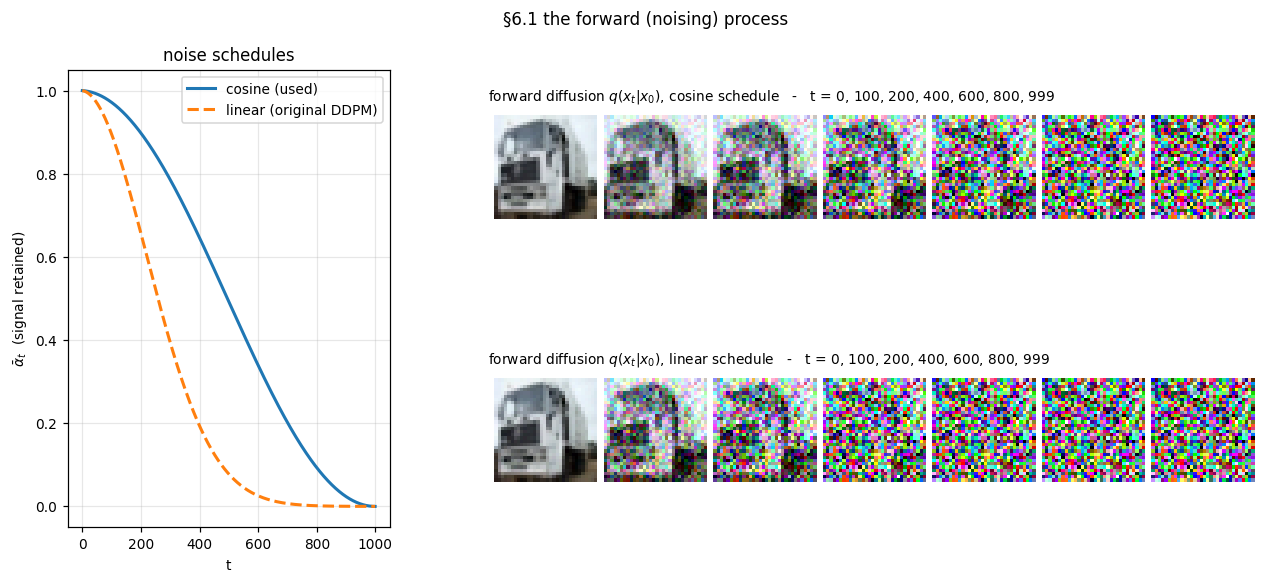

In [18]:
_lin = GaussianDiffusion(1000, "linear")
_ts = [0, 100, 200, 400, 600, 800, 999]

fig = plt.figure(figsize=(14, 5.4))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2.4], hspace=0.35, wspace=0.18)

ax = fig.add_subplot(gs[:, 0])
ax.plot(DIFFUSION.alphas_cumprod.cpu(), label="cosine (used)", lw=2)
ax.plot(_lin.alphas_cumprod.cpu(), label="linear (original DDPM)", lw=2, ls="--")
ax.set_xlabel("t"); ax.set_ylabel(r"$\bar{\alpha}_t$  (signal retained)")
ax.set_title("noise schedules"); ax.legend(); ax.grid(alpha=0.3)

seed_everything(3)
_x0 = to_pm1(FIXED_REAL[:1]).to(DEVICE)
for r, (diff, nm) in enumerate(((DIFFUSION, "cosine"), (_lin, "linear"))):
    row = []
    for ti in _ts:
        xt, _ = diff.q_sample(_x0.repeat(1, 1, 1, 1),
                              torch.full((1,), ti, device=DEVICE, dtype=torch.long),
                              noise=torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE,
                                                generator=torch.Generator(DEVICE).manual_seed(0)))
        row.append(to_01(xt).cpu())
    axr = fig.add_subplot(gs[r, 1])
    axr.imshow(to_uint8_grid(torch.cat(row), nrow=len(_ts)))
    axr.set_axis_off()
    axr.set_title(f"forward diffusion $q(x_t|x_0)$, {nm} schedule   -   t = " +
                  ", ".join(str(t) for t in _ts), fontsize=9, loc="left")
fig.suptitle("§6.1 the forward (noising) process", fontsize=11)
fig.savefig(FIG_DIR / "20_forward_diffusion.png")
plt.show()
del _lin

### 6.6 Training the DDPM

DDPM:   0%|          | 0/15000 [00:00<?, ?it/s]

DDPM trained 15000 steps (1,920,000 images) in 38.7 min, final smoothed loss 0.0550


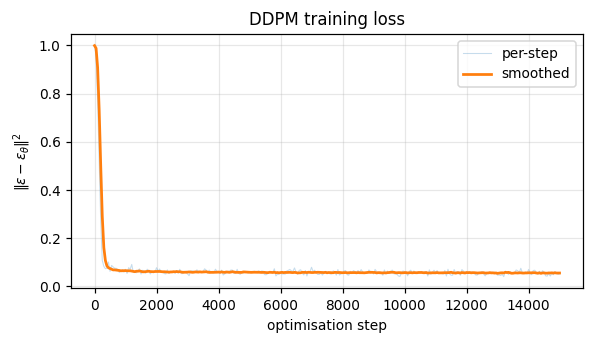

In [19]:
def make_ddpm_unet() -> UNet:
    return UNet(base=128, ch_mults=(1, 2, 2), num_res_blocks=2,
                attn_resolutions=(16,), dropout=0.1).to(DEVICE)


def train_ddpm(steps: int, batch: int, lr: float = 2e-4, ema_decay: float = 0.9995,
               tag: str = "ddpm") -> tuple[UNet, EMA, dict]:
    meta = {"kind": "ddpm", "steps": steps, "batch": batch, "lr": lr, "ema": ema_decay,
            "img": IMG_SIZE, "T": DIFFUSION.T}

    done = load_finished(tag, meta)
    if done is not None:
        model = make_ddpm_unet()
        model.load_state_dict(done["model"])
        ema = EMA(model, decay=ema_decay)
        ema.load_state_dict(done["ema"])
        print(f"DDPM: reusing the finished model in models/{tag}.pt "
              f"({done['hist']['train_seconds']/60:.1f} min of training)")
        return model, ema, done["hist"]

    seed_everything(SEED)
    model = make_ddpm_unet()
    ema = EMA(model, decay=ema_decay)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.999), weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: _lr_lambda(s, steps, warmup=1000))
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP and AMP_DTYPE is torch.float16)
    hist = {"step": [], "loss": [], "ema_loss": []}
    running, start, prior = None, 0, 0.0

    ck = load_checkpoint(tag, meta)
    if ck is not None:
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); ema.load_state_dict(ck["ema"])
        if ck["scaler"] is not None:
            scaler.load_state_dict(ck["scaler"])
        hist, start, prior = ck["hist"], ck["step"], ck["elapsed"]
        running = hist["ema_loss"][-1] if hist["ema_loss"] else None
        _restore_rng(ck["rng"])
        print(f"DDPM: resuming from step {start}/{steps} ({prior/60:.1f} min already done)")

    model.train()
    with Timer() as timer:
        pbar = tqdm(range(start, steps), desc="DDPM", leave=False, initial=start, total=steps)
        for step in pbar:
            x, _ = sample_batch(batch)
            x0 = to_pm1(x)
            loss = DIFFUSION.loss(lambda xt, t: model(xt, t), x0)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            ema.update(model, step)

            running = loss.item() if running is None else 0.98 * running + 0.02 * loss.item()
            if step % 50 == 0 or step == steps - 1:
                hist["step"].append(step); hist["loss"].append(loss.item())
                hist["ema_loss"].append(running)
                pbar.set_postfix(loss=f"{running:.4f}", lr=f"{sched.get_last_lr()[0]:.1e}")
            if (step + 1) % CKPT_EVERY == 0 and step != steps - 1:
                save_checkpoint(tag, step, model, opt, sched, hist, ema=ema, scaler=scaler,
                                meta=meta, elapsed=prior + time.perf_counter() - timer.t0)

    hist["train_seconds"] = prior + timer.seconds
    hist["steps"], hist["batch"] = steps, batch
    hist["images_seen"] = steps * batch
    torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "hist": hist, "meta": meta},
               MODEL_DIR / f"{tag}.pt")
    (CKPT_DIR / f"{tag}.ckpt").unlink(missing_ok=True)
    print(f"DDPM trained {steps} steps ({steps*batch:,} images) in "
          f"{hist['train_seconds']/60:.1f} min, final smoothed loss {running:.4f}")
    return model, ema, hist


DDPM_NET, DDPM_EMA, DDPM_HIST = train_ddpm(BUDGET.ddpm_steps, BUDGET.ddpm_batch)

# the EMA weights are what we sample from
DDPM_SAMPLER_NET = make_ddpm_unet()
DDPM_EMA.copy_to(DDPM_SAMPLER_NET)
DDPM_SAMPLER_NET.eval()

def ddpm_eps(x, t):
    return DDPM_SAMPLER_NET(x, t)

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(DDPM_HIST["step"], DDPM_HIST["loss"], alpha=0.25, lw=0.7, label="per-step")
ax.plot(DDPM_HIST["step"], DDPM_HIST["ema_loss"], lw=1.8, label="smoothed")
ax.set_xlabel("optimisation step"); ax.set_ylabel(r"$\|\epsilon - \epsilon_\theta\|^2$")
ax.set_title("DDPM training loss"); ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "21_ddpm_loss.png")
plt.show()

### 6.7 Task 5 (second half) — synthesising the five photographs with the DDPM

A DDPM has no encoder, so "passing an image in" needs a different mechanism than the VAE's.
The standard one is **SDEdit** (Meng et al., 2022), and it falls straight out of §6.1:

1. Take the photograph `x_0` and jump it partway up the *forward* chain to `x_t` with
   `t = strength · T`, using the same one-shot formula
   `x_t = sqrt(ᾱ_t)·x_0 + sqrt(1 - ᾱ_t)·eps`.
2. Run the ordinary *reverse* chain from `t` down to 0.

Step 1 destroys fine detail while leaving coarse structure — pose, layout, colour mass —
recognisable. Step 2 then rebuilds detail, but it can only rebuild it **using what the network
learned from CIFAR-10**. The result is a genuinely synthesised image that is visually similar to
the input photograph.

**`strength` is the knob that matters**, and the sweep below shows the whole trade-off in one
figure: at 0.2 the output is nearly the input, at 1.0 the photograph is erased entirely and this
reduces to the unconditional sampling of Task 6. The headline Task 5 answer uses **0.6**, which
keeps the subject while giving the model enough freedom to redraw it.

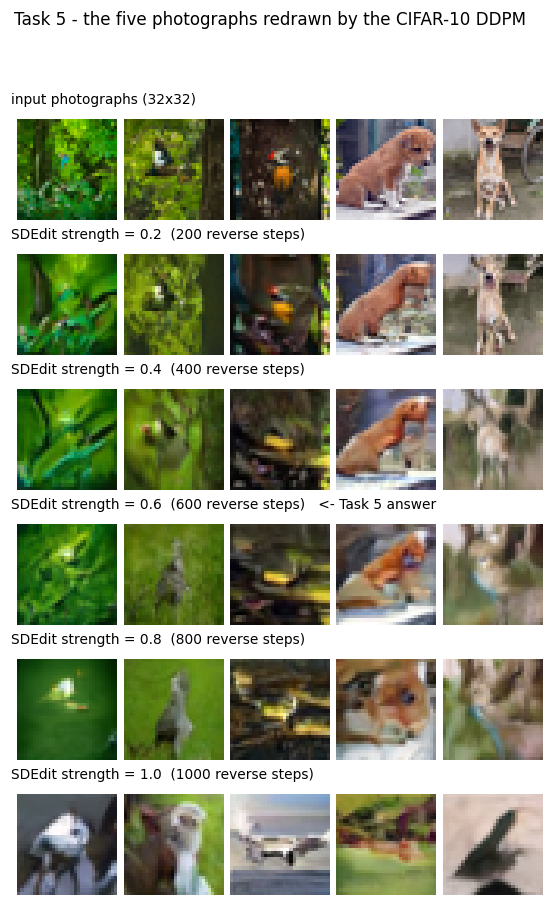

,steps_run,PSNR vs input (dB),SSIM vs input,seconds,laplacian_var,tenengrad
strength,,,,,,
0.2,200,21.6104,0.7064,2.8250,0.0722,0.7614
0.4,400,18.4390,0.5105,5.5573,0.0460,0.7021
0.6,600,16.6093,0.3876,8.1369,0.0373,0.6410
0.8,800,14.6857,0.2929,10.7996,0.0352,0.6378
1.0,1000,9.6736,0.1994,13.9152,0.0586,0.9829


PSNR/SSIM fall monotonically as strength rises - that is the point, not a defect:
more of the photograph is being replaced by the model's own CIFAR-10 prior.


In [20]:
_photo_pm1 = to_pm1(PHOTOS.to(DEVICE))
_rows_sd, _sd_stats = [], []
for s in SDEDIT_STRENGTHS:
    g = torch.Generator(DEVICE).manual_seed(4242)
    with Timer() as _t:
        out = DIFFUSION.sdedit(ddpm_eps, _photo_pm1, strength=s, generator=g)
    img = to_01(out).cpu().clamp(0, 1)
    _rows_sd.append(img)
    _sd_stats.append({"strength": s, "steps_run": int(s * DIFFUSION.T),
                      "PSNR vs input (dB)": psnr(img, PHOTOS),
                      "SSIM vs input": ssim(img, PHOTOS),
                      "seconds": _t.seconds, **sharpness_metrics(img)})

DDPM_TASK5 = _rows_sd[SDEDIT_STRENGTHS.index(SDEDIT_MAIN)]
save_individual(DDPM_TASK5, "ddpm_task5_photo")

fig, axes = plt.subplots(len(SDEDIT_STRENGTHS) + 1, 1, figsize=(7.0, 1.55 * (len(SDEDIT_STRENGTHS) + 1)))
axes[0].imshow(to_uint8_grid(PHOTOS, nrow=5)); axes[0].set_axis_off()
axes[0].set_title("input photographs (32x32)", fontsize=9, loc="left")
for ax, s, imgs in zip(axes[1:], SDEDIT_STRENGTHS, _rows_sd):
    ax.imshow(to_uint8_grid(imgs, nrow=5)); ax.set_axis_off()
    ax.set_title(f"SDEdit strength = {s}  ({int(s*DIFFUSION.T)} reverse steps)"
                 + ("   <- Task 5 answer" if s == SDEDIT_MAIN else ""), fontsize=9, loc="left")
fig.suptitle("Task 5 - the five photographs redrawn by the CIFAR-10 DDPM", fontsize=11)
fig.savefig(FIG_DIR / "25_task5_photo_synthesis.png")
plt.show()

TASK5 = pd.DataFrame(_sd_stats).set_index("strength")
RESULTS["task5_sdedit"] = _sd_stats
display(TASK5.round(4))
print("PSNR/SSIM fall monotonically as strength rises - that is the point, not a defect:")
print("more of the photograph is being replaced by the model's own CIFAR-10 prior.")

## §7 Task 6 — five images generated by the trained DDPM

Exactly what the task specifies: draw five matrices `x_T ~ N(0, I)` of shape `3 x 64 x 64`,
then run the **full 1000-step reverse diffusion process**, one ancestral step at a time, with no
shortcuts. The trajectory panel underneath shows the same five chains at intermediate `t`, which
is the clearest illustration of what "reverse denoising" actually does: global colour and layout
emerge first (high `t`), texture and edges last (low `t`).

DDPM reverse:   0%|          | 0/1000 [00:00<?, ?it/s]

5 images x 1000 reverse steps in 13.5 s (2.71 s per image)


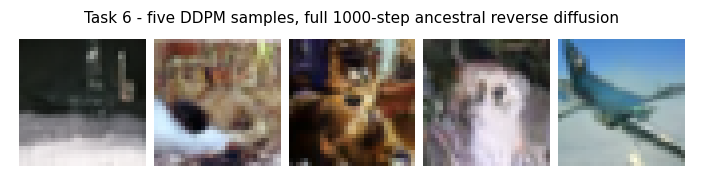

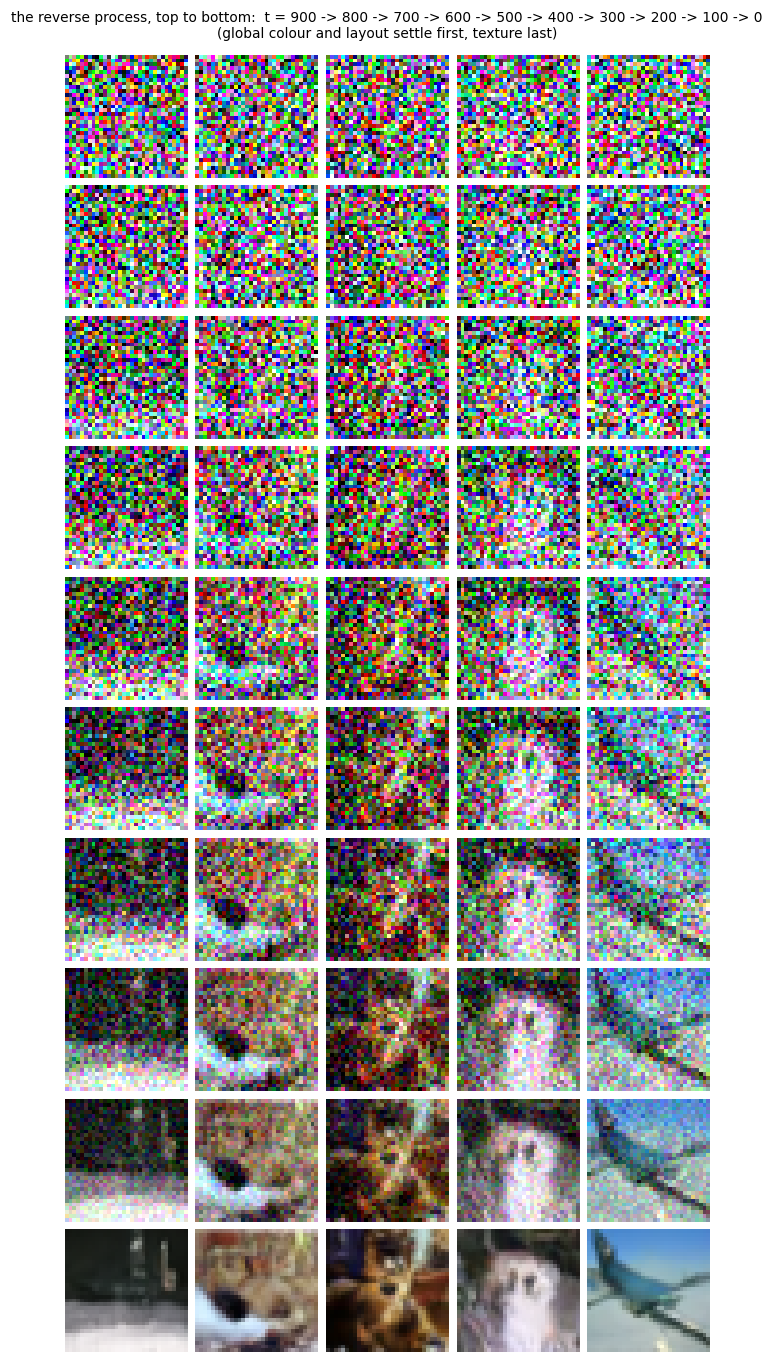

In [21]:
_gen = torch.Generator(DEVICE).manual_seed(2025)
with Timer() as _t_ddpm5:
    _x_ddpm, _traj = DIFFUSION.p_sample_loop(
        ddpm_eps, (5, 3, IMG_SIZE, IMG_SIZE), generator=_gen, record_every=100)
DDPM_TASK6 = to_01(_x_ddpm).cpu().clamp(0, 1)

print(f"5 images x {DIFFUSION.T} reverse steps in {_t_ddpm5.seconds:.1f} s "
      f"({_t_ddpm5.seconds/5:.2f} s per image)")
RESULTS["task6_time_5_images_s"] = _t_ddpm5.seconds

show_grid(DDPM_TASK6, "Task 6 - five DDPM samples, full 1000-step ancestral reverse diffusion",
          nrow=5, save="22_task6_ddpm_samples.png", figsize=(8, 2.2))
save_individual(DDPM_TASK6, "ddpm_task6")

# reverse trajectory: _traj holds (t_index, x_t) pairs recorded every 100 steps
_panel = torch.cat([to_01(x).clamp(0, 1) for _, x in _traj], 0)
fig, ax = plt.subplots(figsize=(10, 1.55 * len(_traj)))
ax.imshow(to_uint8_grid(_panel, nrow=5))
ax.set_axis_off()
ax.set_title("the reverse process, top to bottom:  t = " +
             " -> ".join(str(ti) for ti, _ in _traj) +
             "\n(global colour and layout settle first, texture last)", fontsize=9)
fig.savefig(FIG_DIR / "23_task6_reverse_trajectory.png")
plt.show()

### Generation cost, measured

The same five images, produced by the same network, with DDIM's 50-step deterministic path
instead of the 1000-step ancestral chain. This is the number that matters for the §10
"image-generation time" comparison, and the visual difference at 20x fewer network evaluations
is the honest way to present diffusion's cost.

DDPM 1000 ancestral steps :  13.55 s for 5 images
DDIM   50 steps           :   0.72 s for 5 images  (18.9x faster)


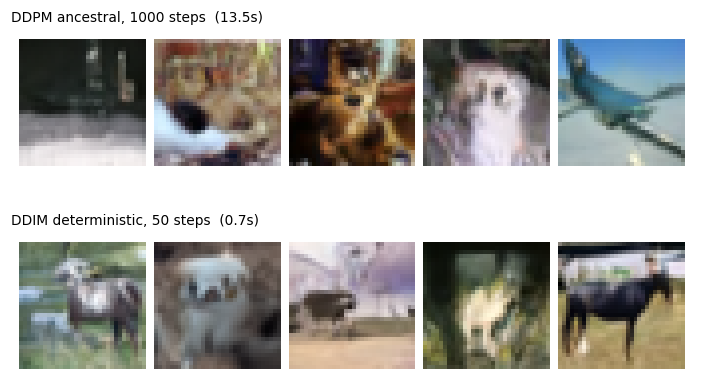

In [22]:
seed_everything()
_gen = torch.Generator(DEVICE).manual_seed(2025)
with Timer() as _t_ddim:
    _x_ddim = DIFFUSION.ddim_sample(ddpm_eps, (5, 3, IMG_SIZE, IMG_SIZE), steps=50,
                                    generator=_gen)
_ddim_imgs = to_01(_x_ddim).cpu().clamp(0, 1)
print(f"DDPM 1000 ancestral steps : {_t_ddpm5.seconds:6.2f} s for 5 images")
print(f"DDIM   50 steps           : {_t_ddim.seconds:6.2f} s for 5 images  "
      f"({_t_ddpm5.seconds/max(_t_ddim.seconds,1e-9):.1f}x faster)")

fig, axes = plt.subplots(2, 1, figsize=(8, 4.4))
axes[0].imshow(to_uint8_grid(DDPM_TASK6, nrow=5)); axes[0].set_axis_off()
axes[0].set_title(f"DDPM ancestral, 1000 steps  ({_t_ddpm5.seconds:.1f}s)", fontsize=9, loc="left")
axes[1].imshow(to_uint8_grid(_ddim_imgs, nrow=5)); axes[1].set_axis_off()
axes[1].set_title(f"DDIM deterministic, 50 steps  ({_t_ddim.seconds:.1f}s)", fontsize=9, loc="left")
fig.savefig(FIG_DIR / "24_ddpm_vs_ddim.png")
plt.show()
RESULTS["ddpm_ddim50_time_5_images_s"] = _t_ddim.seconds

## §8 Task 7 — a Latent Diffusion Model

The DDPM of §6 runs its 1000-step chain on `3 x 32 x 32 = 3 072` numbers. Most of those
numbers encode perceptual detail that a *compression* model can reproduce almost for free —
spending a thousand U-Net evaluations on them is waste. Rombach et al. (2022) split the problem
in two:

```
 perceptual compression                    semantic generation
 (learned once, cheap to run)              (the expensive part, now 3x smaller)

 x  --E-->  z (4x16x16)  ------ diffusion in latent space ------>  ẑ  --D-->  x̂
```

### 8.1 Role of the VAE encoder and decoder (the "first stage")

The first stage is a **KL-regularised autoencoder**, trained *by itself and frozen* before any
diffusion training starts. Its two halves have distinct jobs:

* The **encoder `E`** maps `3 x 32 x 32` to a `4 x 16 x 16` latent — a **downsampling factor
  f = 2**, which is a **3x reduction in the number of values** and, what matters more for a
  convolutional U-Net, a **4x reduction in the number of spatial positions**. It discards
  exactly what diffusion is bad at spending capacity on: imperceptible high-frequency detail
  and sensor noise.

  `f = 2` is modest — Stable Diffusion uses `f = 8` — and that is forced by the resolution.
  CIFAR-10 images are only 32x32, so `f = 4` would leave an 8x8 latent and start destroying the
  object itself. **The efficiency argument for latent diffusion is therefore structurally weak
  at this resolution**, and §11 measures exactly how weak rather than overselling it. The
  scaling analysis there shows why the same technique becomes decisive at 512x512.
* The **decoder `D`** maps latents back to pixels. It is the only thing that ever produces an
  image, so *the first stage's reconstruction quality is a hard ceiling on the LDM's sample
  quality* — if `D(E(x))` is blurry, no amount of diffusion training will produce sharp
  samples. That is why the first stage below is trained with a **VGG perceptual loss** on top of
  pixel MSE, and why its reconstruction PSNR/SSIM is reported before the diffusion model is
  even built.

**How this differs from the §2 VAE.** Both are VAEs, but they are tuned for opposite ends of the
rate-distortion curve:

| | §2 VAE (a generative model) | §8 first stage (a compressor) |
|---|---|---|
| latent | 128-d **vector**, no spatial structure | `4 x 16 x 16` **spatial** tensor |
| KL weight | `beta = 1` — the prior must be exactly `N(0,I)` so we can sample from it | `1e-6` — only enough to stop the latent scale drifting |
| who samples the latent | we do, from `N(0, I)` | the diffusion model does |
| consequence | strong regularisation → blur | near-lossless reconstruction, latents *not* directly samplable |

A near-deterministic latent space would be useless to sample from directly — which is precisely
why a second model is needed to learn `p(z)`.

### 8.2 Latent-space diffusion

The *identical* DDPM machinery of §6 (cosine schedule, `T = 1000`, `eps`-prediction,
`L_simple`, ancestral sampling) is applied to `z` instead of `x`. Two practical details:

* **Latent rescaling.** The encoder's output has some arbitrary scale; the diffusion schedule
  assumes unit variance. We measure `std(z)` over the training set once and fold `1/std` into
  the latents (Stable Diffusion's `scale_factor = 0.18215` is the same trick).
* The generation pipeline becomes `z_T ~ N(0, I)` → 1000 reverse steps → `ẑ` → `D(ẑ / scale)`.

### 8.3 The U-Net and the timestep embedding

Same U-Net class as §6, re-instantiated for `4 x 16 x 16` latents: base width 64, multipliers
`(1, 2, 2)` giving resolutions 16 → 8 → 4, attention at every resolution (affordable now that
the grids are tiny). The **timestep embedding** is unchanged — sinusoidal features of `t`,
through a 2-layer MLP, injected as a per-channel scale-and-shift in every residual block — and
the **class embedding is added to it**, which is the standard way to give the network a cheap
global conditioning signal alongside the cross-attention.

### 8.4 Conditioning mechanism

This is what turns a latent DDPM into a *latent diffusion model* in the Rombach et al. sense.
Conditioning information `y` is mapped by a domain-specific encoder `tau(y)` to a sequence of
tokens, and the U-Net attends to those tokens through **cross-attention** inside every
transformer block:

$$\text{Attention}(Q,K,V) = \operatorname{softmax}\!\Big(\tfrac{QK^\top}{\sqrt d}\Big)V,\qquad
Q = W_Q\,\varphi(z_t),\quad K = W_K\,\tau(y),\quad V = W_V\,\tau(y).$$

In Stable Diffusion `tau` is a frozen CLIP text encoder. Here the conditioning signal is the
**CIFAR-10 class label** (`y ∈ {0..9}` = airplane … truck), and `tau` is a learned embedding
table producing 4 tokens of 256 dims per class. Each spatial position of the latent `Q`-queries
those 4 tokens, so the network can ask "which class am I painting?" at every layer and every
resolution.

This is also what makes Task 7 work: the five photographs are three birds and two dogs, so the
LDM can be *told* to redraw each one as its own class while the latent image-to-image path
supplies the pose and layout.

We additionally train for **classifier-free guidance**: 10 % of training steps replace `y` with
a learned *null* class, so a single network learns both `eps(z_t, t, y)` and `eps(z_t, t, ∅)`.
At sampling time the two are extrapolated,
`eps = eps(∅) + w · (eps(y) - eps(∅))` with `w > 1`, which trades diversity for fidelity to the
requested class. `w` is swept in §9.

In [23]:
LATENT_CH = 4
LATENT_RES = IMG_SIZE // 2          # 32 -> 16, i.e. downsampling factor f = 2
CTX_DIM, CTX_TOKENS = 256, 4

print(f"first stage: 3x{IMG_SIZE}x{IMG_SIZE} = {3*IMG_SIZE*IMG_SIZE:,} values"
      f"  ->  {LATENT_CH}x{LATENT_RES}x{LATENT_RES} = {LATENT_CH*LATENT_RES**2:,} values"
      f"   ({3*IMG_SIZE*IMG_SIZE/(LATENT_CH*LATENT_RES**2):.0f}x fewer values, "
      f"{IMG_SIZE**2/LATENT_RES**2:.0f}x fewer spatial positions)")


class KLAutoencoder(nn.Module):
    """LDM first stage: convolutional encoder/decoder with a spatial diagonal-Gaussian latent."""

    def __init__(self, z_ch: int = LATENT_CH, base: int = 64, ch_mults=(1, 2),
                 num_res_blocks: int = 2):
        super().__init__()
        chs = [base * m for m in ch_mults]

        enc, cur = [nn.Conv2d(3, chs[0], 3, padding=1)], chs[0]
        for i, c in enumerate(chs):
            for _ in range(num_res_blocks):
                enc.append(ResBlockAE(cur, c)); cur = c
            if i != len(chs) - 1:                      # one downsample -> f = 2
                enc.append(nn.Conv2d(cur, cur, 4, stride=2, padding=1))
        enc += [ResBlockAE(cur, cur), SelfAttention2d(cur), ResBlockAE(cur, cur),
                gn(cur), nn.SiLU(), nn.Conv2d(cur, 2 * z_ch, 3, padding=1)]
        self.encoder = nn.Sequential(*enc)

        dec, cur = [nn.Conv2d(z_ch, chs[-1], 3, padding=1)], chs[-1]
        dec += [ResBlockAE(cur, cur), SelfAttention2d(cur), ResBlockAE(cur, cur)]
        for i, c in enumerate(reversed(chs)):
            for _ in range(num_res_blocks):
                dec.append(ResBlockAE(cur, c)); cur = c
            if i != len(chs) - 1:
                dec += [nn.Upsample(scale_factor=2, mode="nearest"), nn.Conv2d(cur, cur, 3, padding=1)]
        dec += [gn(cur), nn.SiLU(), nn.Conv2d(cur, 3, 3, padding=1)]
        self.decoder = nn.Sequential(*dec)
        self.z_ch = z_ch

    def encode(self, x_pm1: torch.Tensor):
        mu, logvar = self.encoder(x_pm1).chunk(2, dim=1)
        return mu, logvar.clamp(-30.0, 20.0)

    def decode(self, z: torch.Tensor) -> torch.Tensor:
        return self.decoder(z)                       # values in [-1, 1] after clamping

    def forward(self, x_pm1: torch.Tensor, sample: bool = True):
        mu, logvar = self.encode(x_pm1)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu) if sample else mu
        return self.decode(z), mu, logvar, z


class VGGPerceptual(nn.Module):
    """MSE between normalised VGG16 features - the cheap stand-in for LPIPS.

    The first stage is a *compressor*: pixel MSE alone gives it no reason to keep texture, so a
    perceptual term is what stops the LDM's decoder from imposing a blur ceiling on every sample.
    """

    LAYERS = (3, 8, 15)      # relu1_2, relu2_2, relu3_3

    def __init__(self):
        super().__init__()
        from torchvision.models import VGG16_Weights, vgg16
        feats = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).features[:max(self.LAYERS) + 1]
        self.feats = feats.eval()
        for p in self.feats.parameters():
            p.requires_grad_(False)
        self.register_buffer("mean", _IMAGENET_MEAN)
        self.register_buffer("std", _IMAGENET_STD)

    def forward(self, a_pm1: torch.Tensor, b_pm1: torch.Tensor) -> torch.Tensor:
        a = (to_01(a_pm1) - self.mean) / self.std
        b = (to_01(b_pm1) - self.mean) / self.std
        loss, x, y = 0.0, a, b
        for i, layer in enumerate(self.feats):
            x, y = layer(x), layer(y)
            if i in self.LAYERS:
                nx = x / (x.pow(2).mean(1, keepdim=True).sqrt() + 1e-8)
                ny = y / (y.pow(2).mean(1, keepdim=True).sqrt() + 1e-8)
                loss = loss + F.mse_loss(nx, ny)
        return loss


_probe = KLAutoencoder().to(DEVICE)
print(f"KL-autoencoder: {count_params(_probe)/1e6:.2f} M parameters")
with torch.no_grad():
    _o, _m, _lv, _z = _probe(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
print(f"  x {tuple((2,3,IMG_SIZE,IMG_SIZE))} -> z {tuple(_z.shape)} -> x_hat {tuple(_o.shape)}")
del _probe, _o, _m, _lv, _z

first stage: 3x32x32 = 3,072 values  ->  4x16x16 = 1,024 values   (3x fewer values, 4x fewer spatial positions)
KL-autoencoder: 3.01 M parameters
  x (2, 3, 32, 32) -> z (2, 4, 16, 16) -> x_hat (2, 3, 32, 32)


### 8.5 Training the first stage

`L = MSE(x̂, x) + 0.5 · perceptual(x̂, x) + 1e-6 · KL`. The KL weight is deliberately tiny — it
exists only to keep the latent scale from drifting, not to shape the latent into a samplable
prior. (The original LDM adds a patch-GAN discriminator on top; that is omitted here as it
roughly doubles the training code and adds an adversarial failure mode.)

LDM first stage:   0%|          | 0/8000 [00:00<?, ?it/s]

first stage trained 8000 steps in 5.7 min -> reconstruction PSNR 38.37 dB


first-stage reconstruction over 256 held-out test images: PSNR 37.23 dB, SSIM 0.9909   <- upper bound on LDM sample fidelity


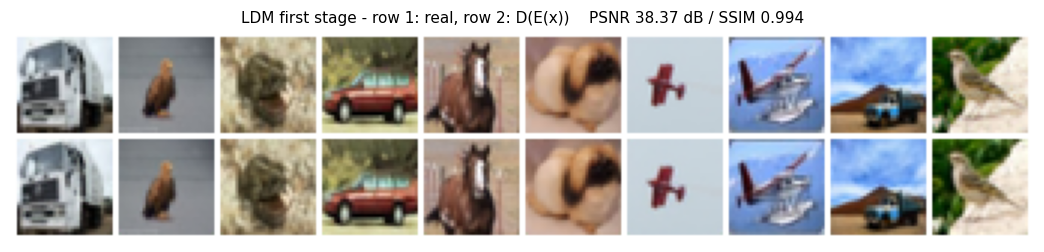

latent statistics: mean -0.081, std 1.144 -> scale_factor = 0.8741  (Stable Diffusion uses 0.18215 for the same reason)


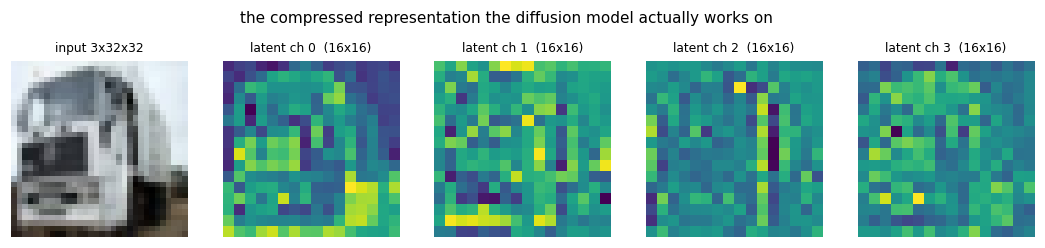

In [24]:
def train_first_stage(steps: int, batch: int, lr: float = 2e-4, kl_weight: float = 1e-6,
                      perc_weight: float = 0.5, tag: str = "ldm_first_stage"):
    meta = {"kind": "kl_ae", "steps": steps, "batch": batch, "lr": lr, "kl_w": kl_weight,
            "perc_w": perc_weight, "img": IMG_SIZE, "z": [LATENT_CH, LATENT_RES, LATENT_RES]}

    done = load_finished(tag, meta)
    if done is not None:
        model = KLAutoencoder().to(DEVICE)
        model.load_state_dict(done["model"])
        print(f"first stage: reusing the finished model in models/{tag}.pt "
              f"({done['hist']['train_seconds']/60:.1f} min of training)")
        return model, done["hist"]

    seed_everything(SEED)
    model = KLAutoencoder().to(DEVICE)
    perceptual = VGGPerceptual().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.5, 0.9), weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: _lr_lambda(s, steps))
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP and AMP_DTYPE is torch.float16)
    hist = {k: [] for k in ("step", "mse", "perc", "kl", "psnr")}
    start, prior = 0, 0.0

    ck = load_checkpoint(tag, meta)
    if ck is not None:
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"])
        if ck["scaler"] is not None:
            scaler.load_state_dict(ck["scaler"])
        hist, start, prior = ck["hist"], ck["step"], ck["elapsed"]
        _restore_rng(ck["rng"])
        print(f"first stage: resuming from step {start}/{steps} ({prior/60:.1f} min already done)")

    model.train()
    with Timer() as timer:
        pbar = tqdm(range(start, steps), desc="LDM first stage", leave=False, initial=start,
                    total=steps)
        for step in pbar:
            x, _ = sample_batch(batch)
            x = to_pm1(x)
            with autocast():
                xhat, mu, logvar, _ = model(x)
                p = perceptual(xhat, x)
            xhat = xhat.float()
            mse = F.mse_loss(xhat, x)
            kl = (-0.5 * (1 + logvar.float() - mu.float().pow(2) - logvar.float().exp())).flatten(1).sum(1).mean()
            loss = mse + perc_weight * p.float() + kl_weight * kl
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()

            if step % 25 == 0 or step == steps - 1:
                hist["step"].append(step); hist["mse"].append(mse.item())
                hist["perc"].append(p.item()); hist["kl"].append(kl.item())
                hist["psnr"].append(float("nan"))
                pbar.set_postfix(mse=f"{mse.item():.4f}", perc=f"{p.item():.3f}")
            if step % max(1, steps // 12) == 0 or step == steps - 1:
                model.eval()
                with torch.no_grad():
                    r = to_01(model(to_pm1(FIXED_REAL.to(DEVICE)), sample=False)[0]).cpu()
                model.train()
                hist["psnr"][-1] = psnr(r, FIXED_REAL)
            if (step + 1) % CKPT_EVERY == 0 and step != steps - 1:
                save_checkpoint(tag, step, model, opt, sched, hist, scaler=scaler, meta=meta,
                                elapsed=prior + time.perf_counter() - timer.t0)

    hist["train_seconds"] = prior + timer.seconds
    torch.save({"model": model.state_dict(), "hist": hist, "meta": meta}, MODEL_DIR / f"{tag}.pt")
    (CKPT_DIR / f"{tag}.ckpt").unlink(missing_ok=True)
    print(f"first stage trained {steps} steps in {hist['train_seconds']/60:.1f} min "
          f"-> reconstruction PSNR {hist['psnr'][-1]:.2f} dB")
    del perceptual
    return model, hist


FIRST_STAGE, FS_HIST = train_first_stage(BUDGET.ae_steps, BUDGET.ae_batch)
FIRST_STAGE.eval()
for p in FIRST_STAGE.parameters():
    p.requires_grad_(False)


@torch.no_grad()
def fs_encode(x01: torch.Tensor, sample: bool = True, batch: int = 128) -> torch.Tensor:
    out = []
    for i in range(0, len(x01), batch):
        mu, logvar = FIRST_STAGE.encode(to_pm1(x01[i:i + batch].to(DEVICE)))
        out.append(mu + torch.exp(0.5 * logvar) * torch.randn_like(mu) if sample else mu)
    return torch.cat(out)


@torch.no_grad()
def fs_decode(z: torch.Tensor, batch: int = 128) -> torch.Tensor:
    return torch.cat([to_01(FIRST_STAGE.decode(z[i:i + batch].to(DEVICE))).clamp(0, 1).cpu()
                      for i in range(0, len(z), batch)])


# ---- first-stage reconstruction quality = the ceiling on LDM sample quality
_r = fs_decode(fs_encode(FIXED_REAL, sample=False))
FS_PSNR, FS_SSIM = psnr(_r, FIXED_REAL), ssim(_r, FIXED_REAL)
_r_big = fs_decode(fs_encode(REAL_REF[:256], sample=False))
FS_PSNR_ALL, FS_SSIM_ALL = psnr(_r_big, REAL_REF[:256]), ssim(_r_big, REAL_REF[:256])
RESULTS["ldm_first_stage"] = {"psnr": FS_PSNR_ALL, "ssim": FS_SSIM_ALL,
                              "train_seconds": FS_HIST["train_seconds"],
                              **sharpness_metrics(_r_big)}
print(f"first-stage reconstruction over 256 held-out test images: PSNR {FS_PSNR_ALL:.2f} dB, "
      f"SSIM {FS_SSIM_ALL:.4f}   <- upper bound on LDM sample fidelity")

fig, ax = plt.subplots(figsize=(12, 3.0))
ax.imshow(to_uint8_grid(torch.cat([FIXED_REAL, _r], 0), nrow=10))
ax.set_axis_off()
ax.set_title(f"LDM first stage - row 1: real, row 2: D(E(x))    "
             f"PSNR {FS_PSNR:.2f} dB / SSIM {FS_SSIM:.3f}", fontsize=10)
fig.savefig(FIG_DIR / "30_ldm_first_stage_recon.png")
plt.show()

# ---- latent scaling factor
# The LDM is trained on `z * LATENT_SCALE`, so a resumed run MUST use exactly the value its
# checkpoint was trained with. Two things would otherwise perturb it: the encoder samples
# z ~ q(z|x) (fixed by seeding), and cuDNN autotuning picks different kernels between processes,
# which moves the last few decimals. So the value is computed once and cached to disk.
_scale_path = CACHE_DIR / "latent_scale.json"
# the cached value is only valid for the first stage that produced it
_scale_key = {"img": IMG_SIZE, "z": [LATENT_CH, LATENT_RES, LATENT_RES],
              "ae_steps": BUDGET.ae_steps, "ae_batch": BUDGET.ae_batch}
seed_everything(4242)
_z_stats = fs_encode(REAL_REF[:min(512, len(REAL_REF))], sample=True)
_cached = None
if RESUME and _scale_path.exists():
    try:
        _blob = json.loads(_scale_path.read_text(encoding="utf-8"))
        _cached = _blob["scale"] if _blob.get("key") == _scale_key else None
    except Exception:
        _cached = None
if _cached is not None:
    LATENT_SCALE = float(_cached)
    print("(latent scale read back from cache/latent_scale.json so it matches any LDM checkpoint)")
else:
    LATENT_SCALE = float(1.0 / _z_stats.std().item())
    _scale_path.write_text(json.dumps({"scale": LATENT_SCALE, "key": _scale_key}), encoding="utf-8")
RESULTS["latent_scale"] = LATENT_SCALE
print(f"latent statistics: mean {_z_stats.mean():+.3f}, std {_z_stats.std():.3f} "
      f"-> scale_factor = {LATENT_SCALE:.4f}  (Stable Diffusion uses 0.18215 for the same reason)")

# ---- what the four latent channels look like
fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
axes[0].imshow(FIXED_REAL[0].permute(1, 2, 0).numpy()); axes[0].set_title("input 3x32x32", fontsize=8)
_z0 = fs_encode(FIXED_REAL[:1], sample=False)[0].cpu()
for c in range(LATENT_CH):
    axes[c + 1].imshow(_z0[c], cmap="viridis")
    axes[c + 1].set_title(f"latent ch {c}  ({LATENT_RES}x{LATENT_RES})", fontsize=8)
for a in axes:
    a.set_axis_off()
fig.suptitle("the compressed representation the diffusion model actually works on", fontsize=10)
fig.savefig(FIG_DIR / "31_latent_channels.png")
plt.show()

### 8.6 The conditional latent denoiser

`LatentDenoiser` bundles the latent U-Net with `tau`, the class-token embedding that feeds the
cross-attention. Index `NUM_CLASSES` is the learned **null token** used by classifier-free
guidance.

In [25]:
class LatentDenoiser(nn.Module):
    def __init__(self, num_classes: int = NUM_CLASSES, ctx_dim: int = CTX_DIM,
                 n_tokens: int = CTX_TOKENS, base: int = 64):
        super().__init__()
        self.n_tokens, self.ctx_dim, self.num_classes = n_tokens, ctx_dim, num_classes
        self.tau = nn.Embedding(num_classes + 1, n_tokens * ctx_dim)     # +1 = null token
        nn.init.normal_(self.tau.weight, std=0.02)
        self.unet = UNet(in_ch=LATENT_CH, out_ch=LATENT_CH, base=base, ch_mults=(1, 2, 2),
                         num_res_blocks=2, attn_resolutions=(LATENT_RES, LATENT_RES // 2,
                                                             LATENT_RES // 4),
                         img_size=LATENT_RES, dropout=0.1, context_dim=ctx_dim,
                         num_classes=num_classes, heads=4, transformer_depth=1)

    def forward(self, z, t, y):
        context = self.tau(y).view(y.shape[0], self.n_tokens, self.ctx_dim)
        return self.unet(z, t, y=y, context=context)


_probe = LatentDenoiser().to(DEVICE)
_zin = torch.zeros(1, LATENT_CH, LATENT_RES, LATENT_RES, device=DEVICE)
_tin = torch.zeros(1, device=DEVICE)
_yin = torch.zeros(1, dtype=torch.long, device=DEVICE)
print(f"latent U-Net    : {count_params(_probe)/1e6:.2f} M parameters")
UNET_LATENT_MACS = count_macs(_probe, _zin, _tin, _yin)
print(f"one forward pass: {UNET_LATENT_MACS/1e9:.3f} GMAC at {LATENT_CH}x{LATENT_RES}x{LATENT_RES}")
print(f"                  vs {UNET_PIXEL_MACS/1e9:.2f} GMAC for the pixel-space U-Net "
      f"-> {UNET_PIXEL_MACS/UNET_LATENT_MACS:.1f}x cheaper per denoising step")
del _probe, _zin, _tin, _yin

latent U-Net    : 11.79 M parameters
one forward pass: 0.632 GMAC at 4x16x16
                  vs 6.00 GMAC for the pixel-space U-Net -> 9.5x cheaper per denoising step


### 8.7 Training the latent diffusion model

Latents are precomputed on the fly by the frozen encoder (`E` is in `no_grad`, so this costs
one cheap forward pass per batch and no memory for activations). Everything else is §6's
training loop, plus the 10 % null-class dropout that enables guidance.

LDM:   0%|          | 0/18000 [00:00<?, ?it/s]

LDM trained 18000 steps (2,304,000 images) in 33.1 min, final smoothed loss 0.2933


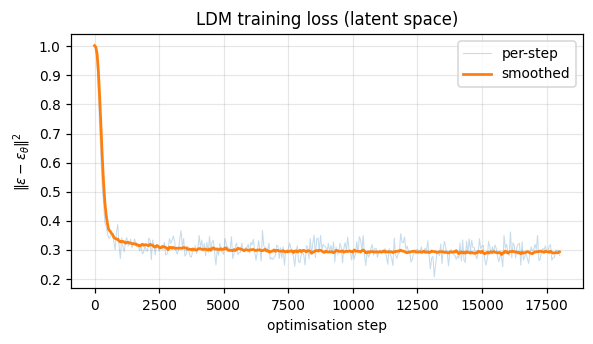

In [26]:
def train_ldm(steps: int, batch: int, lr: float = 2e-4, p_uncond: float = 0.1,
              ema_decay: float = 0.9995, tag: str = "ldm"):
    meta = {"kind": "ldm", "steps": steps, "batch": batch, "lr": lr, "p_uncond": p_uncond,
            "ema": ema_decay, "T": DIFFUSION.T, "scale": round(LATENT_SCALE, 6),
            "z": [LATENT_CH, LATENT_RES, LATENT_RES]}

    done = load_finished(tag, meta)
    if done is not None:
        model = LatentDenoiser().to(DEVICE)
        model.load_state_dict(done["model"])
        ema = EMA(model, decay=ema_decay)
        ema.load_state_dict(done["ema"])
        print(f"LDM: reusing the finished model in models/{tag}.pt "
              f"({done['hist']['train_seconds']/60:.1f} min of training)")
        return model, ema, done["hist"]

    seed_everything(SEED)
    model = LatentDenoiser().to(DEVICE)
    ema = EMA(model, decay=ema_decay)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.999), weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: _lr_lambda(s, steps, warmup=1000))
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP and AMP_DTYPE is torch.float16)
    hist = {"step": [], "loss": [], "ema_loss": []}
    running, start, prior = None, 0, 0.0

    ck = load_checkpoint(tag, meta)
    if ck is not None:
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); ema.load_state_dict(ck["ema"])
        if ck["scaler"] is not None:
            scaler.load_state_dict(ck["scaler"])
        hist, start, prior = ck["hist"], ck["step"], ck["elapsed"]
        running = hist["ema_loss"][-1] if hist["ema_loss"] else None
        _restore_rng(ck["rng"])
        print(f"LDM: resuming from step {start}/{steps} ({prior/60:.1f} min already done)")

    model.train()
    with Timer() as timer:
        pbar = tqdm(range(start, steps), desc="LDM", leave=False, initial=start, total=steps)
        for step in pbar:
            x, y = sample_batch(batch)
            with torch.no_grad():
                z = fs_encode(x, sample=True) * LATENT_SCALE
            y_in = torch.where(torch.rand_like(y, dtype=torch.float) < p_uncond,
                               torch.full_like(y, model.num_classes), y)
            loss = DIFFUSION.loss(lambda zt, t: model(zt, t, y_in), z)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            ema.update(model, step)

            running = loss.item() if running is None else 0.98 * running + 0.02 * loss.item()
            if step % 50 == 0 or step == steps - 1:
                hist["step"].append(step); hist["loss"].append(loss.item())
                hist["ema_loss"].append(running)
                pbar.set_postfix(loss=f"{running:.4f}")
            if (step + 1) % CKPT_EVERY == 0 and step != steps - 1:
                save_checkpoint(tag, step, model, opt, sched, hist, ema=ema, scaler=scaler,
                                meta=meta, elapsed=prior + time.perf_counter() - timer.t0)

    hist["train_seconds"] = prior + timer.seconds
    hist["steps"], hist["batch"] = steps, batch
    torch.save({"model": model.state_dict(), "ema": ema.state_dict(),
                "latent_scale": LATENT_SCALE, "hist": hist, "meta": meta},
               MODEL_DIR / f"{tag}.pt")
    (CKPT_DIR / f"{tag}.ckpt").unlink(missing_ok=True)
    print(f"LDM trained {steps} steps ({steps*batch:,} images) in "
          f"{hist['train_seconds']/60:.1f} min, final smoothed loss {running:.4f}")
    return model, ema, hist


LDM_NET, LDM_EMA, LDM_HIST = train_ldm(BUDGET.ldm_steps, BUDGET.ldm_batch)
LDM_SAMPLER_NET = LatentDenoiser().to(DEVICE)
LDM_EMA.copy_to(LDM_SAMPLER_NET)
LDM_SAMPLER_NET.eval()

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(LDM_HIST["step"], LDM_HIST["loss"], alpha=0.25, lw=0.7, label="per-step")
ax.plot(LDM_HIST["step"], LDM_HIST["ema_loss"], lw=1.8, label="smoothed")
ax.set_xlabel("optimisation step"); ax.set_ylabel(r"$\|\epsilon-\epsilon_\theta\|^2$")
ax.set_title("LDM training loss (latent space)"); ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIG_DIR / "32_ldm_loss.png")
plt.show()

### The classifier-free-guidance sampler

One forward pass on a batch of `2B` (conditional stacked on unconditional) gives both terms of
`eps = eps(∅) + w·(eps(y) - eps(∅))`.

In [27]:
def ldm_eps_fn(net: LatentDenoiser, y: torch.Tensor, guidance: float = 1.0):
    null = torch.full_like(y, net.num_classes)

    def fn(z, t):
        if guidance == 1.0:
            return net(z, t, y)
        e = net(torch.cat([z, z]), torch.cat([t, t]), torch.cat([y, null]))
        e_cond, e_uncond = e.chunk(2)
        return e_uncond + guidance * (e_cond - e_uncond)

    return fn


@torch.no_grad()
def ldm_sample(n: int, y: torch.Tensor | None = None, guidance: float = 2.0,
               steps: int | None = None, seed: int | None = None, net=None,
               record_every: int | None = None, progress: bool = True):
    """z_T ~ N(0,I) in latent space -> reverse diffusion -> VAE decoder -> image."""
    net = net or LDM_SAMPLER_NET
    y = torch.randint(0, NUM_CLASSES, (n,), device=DEVICE) if y is None else y.to(DEVICE)
    g = torch.Generator(DEVICE).manual_seed(seed) if seed is not None else None
    fn = ldm_eps_fn(net, y, guidance)
    shape = (n, LATENT_CH, LATENT_RES, LATENT_RES)
    if steps is None:
        out = DIFFUSION.p_sample_loop(fn, shape, generator=g, progress=progress,
                                      record_every=record_every)
    else:
        out = DIFFUSION.ddim_sample(fn, shape, steps=steps, generator=g, progress=progress)
    if record_every:
        z, traj = out
        return fs_decode(z / LATENT_SCALE), [(i, fs_decode(zz.to(DEVICE) / LATENT_SCALE))
                                             for i, zz in traj], y.cpu()
    return fs_decode(out / LATENT_SCALE), y.cpu()


@torch.no_grad()
def ldm_img2img(x01: torch.Tensor, y: torch.Tensor, strength: float = 0.6,
                guidance: float = 2.0, seed: int | None = None, net=None) -> torch.Tensor:
    """Latent SDEdit: encode -> partially noise the LATENT -> reverse -> decode.

    Same idea as the DDPM's `sdedit`, but every step of the expensive part happens on a
    4x16x16 latent instead of a 3x32x32 image, and the reverse chain is class-conditioned.
    """
    net = net or LDM_SAMPLER_NET
    g = torch.Generator(DEVICE).manual_seed(seed) if seed is not None else None
    z = fs_encode(x01, sample=True) * LATENT_SCALE
    fn = ldm_eps_fn(net, y.to(DEVICE), guidance)
    z_out = DIFFUSION.sdedit(fn, z, strength=strength, generator=g)
    return fs_decode(z_out / LATENT_SCALE)

## §9 Task 8 — five images generated by the trained LDM

Five noise matrices are drawn **in latent space** (`z_T ~ N(0, I)`, shape `4 x 16 x 16`), the
full 1000-step reverse diffusion is run on them, and the resulting latents are decoded to
pixels by the first stage's decoder — exactly the three-stage pipeline the task describes.
The five samples are conditioned on five different CIFAR-10 classes to exercise the
cross-attention mechanism.

DDPM reverse:   0%|          | 0/1000 [00:00<?, ?it/s]

5 images x 1000 latent reverse steps + decode in 31.2 s (6.25 s per image)
  the pixel-space DDPM needed 13.5 s for the same job (ratio 0.43x)
  NOTE: at batch 5 both samplers are dominated by kernel-launch latency, not arithmetic,
  so this ratio does NOT reflect the 10x arithmetic advantage. §11.2 measures where it does.


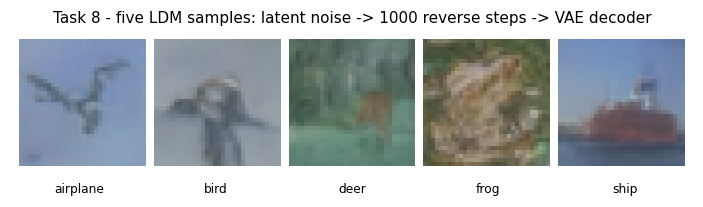

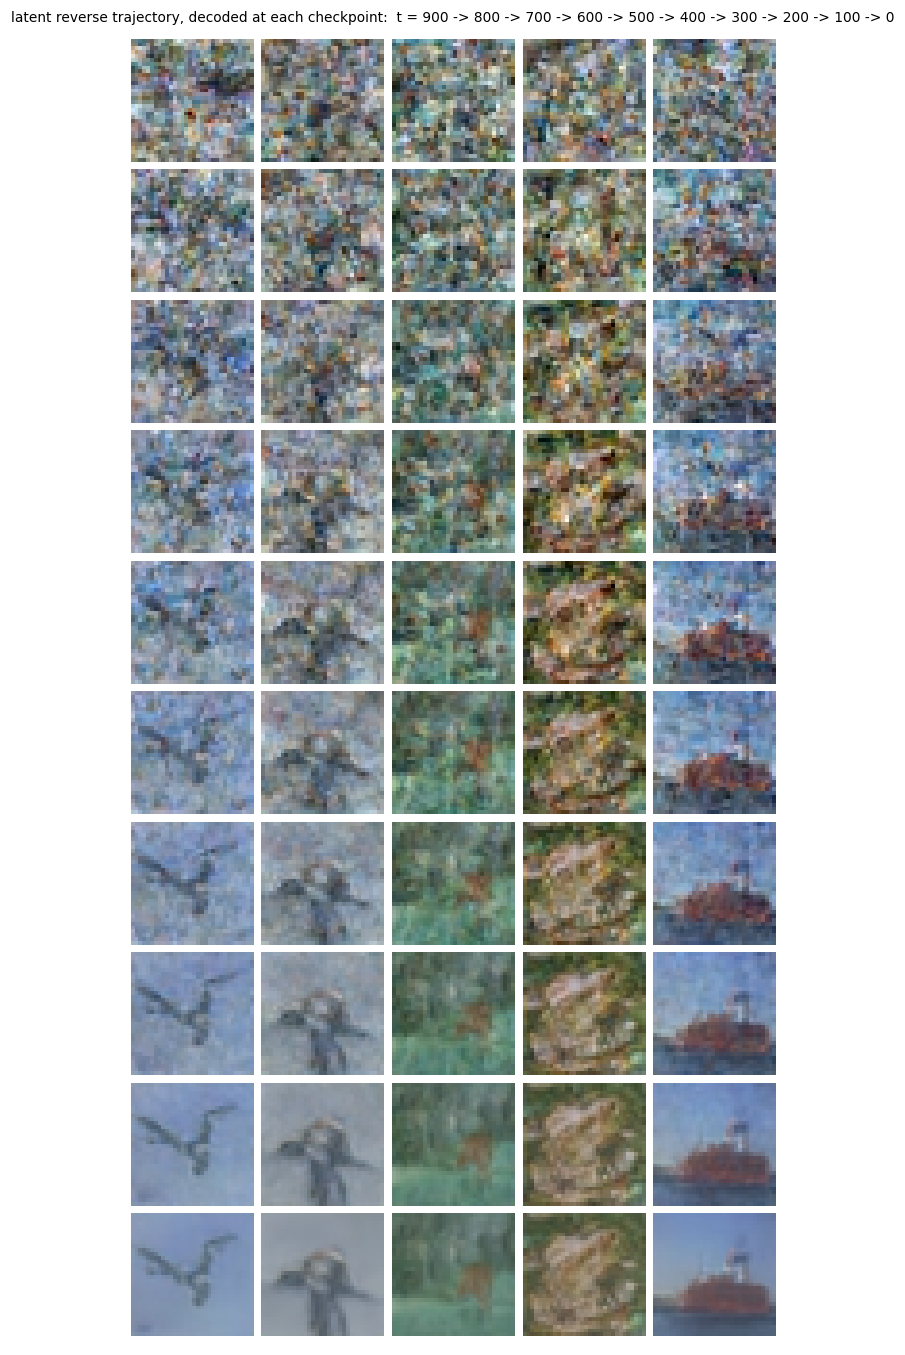

In [28]:
_y5 = torch.arange(5, device=DEVICE) * 2          # airplane, bird, deer, frog, ship
with Timer() as _t_ldm5:
    LDM_TASK8, _ldm_traj, _ = ldm_sample(5, y=_y5, guidance=2.0, seed=2025, record_every=100)

print(f"5 images x {DIFFUSION.T} latent reverse steps + decode in {_t_ldm5.seconds:.1f} s "
      f"({_t_ldm5.seconds/5:.2f} s per image)")
print(f"  the pixel-space DDPM needed {RESULTS['task6_time_5_images_s']:.1f} s for the same job "
      f"(ratio {RESULTS['task6_time_5_images_s']/_t_ldm5.seconds:.2f}x)")
print("  NOTE: at batch 5 both samplers are dominated by kernel-launch latency, not arithmetic,")
print("  so this ratio does NOT reflect the 10x arithmetic advantage. §11.2 measures where it does.")
RESULTS["task8_time_5_images_s"] = _t_ldm5.seconds

show_grid(LDM_TASK8, "Task 8 - five LDM samples: latent noise -> 1000 reverse steps -> VAE decoder",
          nrow=5, save="33_task8_ldm_samples.png", figsize=(8, 2.4),
          subtitles=[CIFAR_CLASSES[int(v)] for v in _y5.cpu()])
save_individual(LDM_TASK8, "ldm_task8")

_panel = torch.cat([img for _, img in _ldm_traj], 0)
fig, ax = plt.subplots(figsize=(10, 1.55 * len(_ldm_traj)))
ax.imshow(to_uint8_grid(_panel, nrow=5))
ax.set_axis_off()
ax.set_title("latent reverse trajectory, decoded at each checkpoint:  t = " +
             " -> ".join(str(i) for i, _ in _ldm_traj), fontsize=9)
fig.savefig(FIG_DIR / "34_task8_latent_trajectory.png")
plt.show()

### The conditioning mechanism, demonstrated

**First figure:** each row fixes the class token `y` and varies the noise. If cross-attention
were doing nothing, the rows would be interchangeable; instead each row takes on the shape,
palette and background typical of its CIFAR-10 class — horses on grass, ships on water,
aeroplanes against sky.

**Second figure:** a guidance-scale sweep at fixed noise. `w = 1` is the plain conditional
model; larger `w` pushes samples further towards the class-typical mode — more saturated and
more "canonical", less diverse. This is the classifier-free-guidance trade-off in one picture.

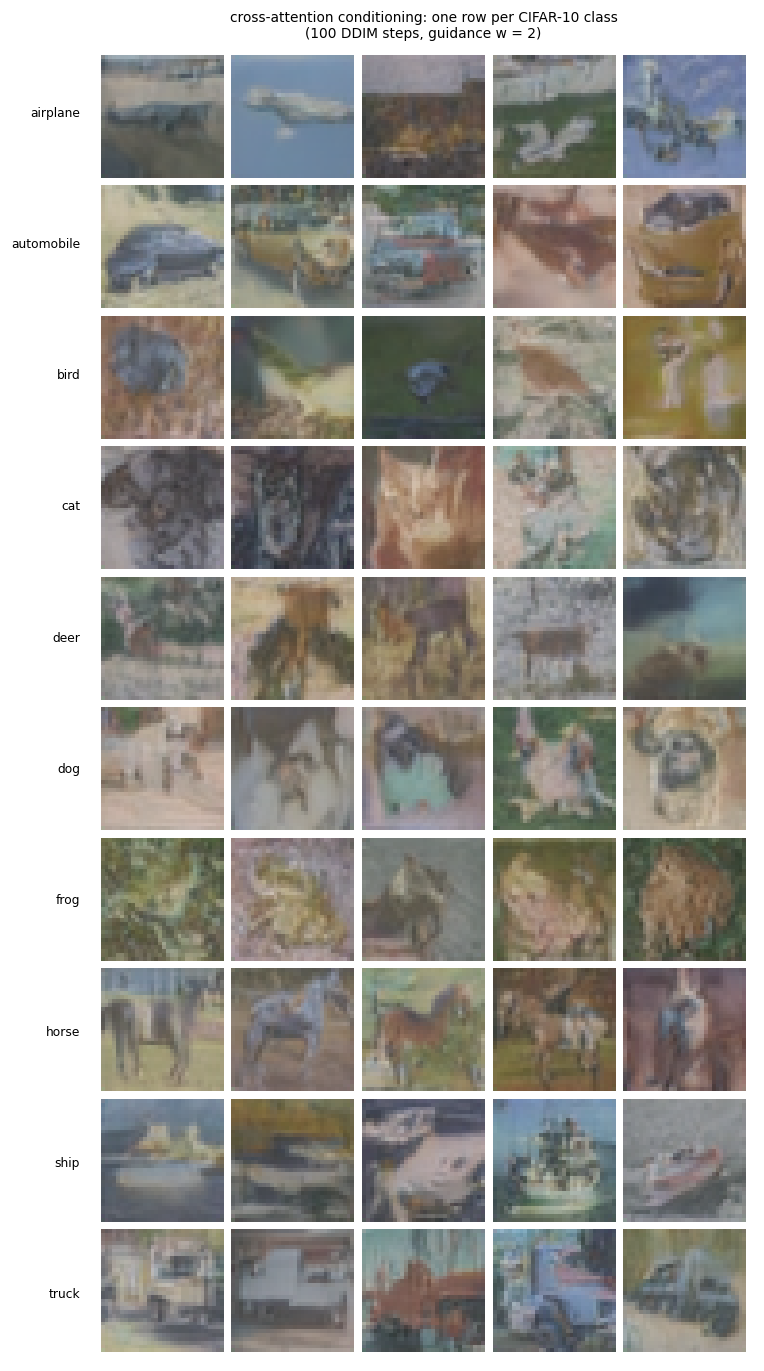

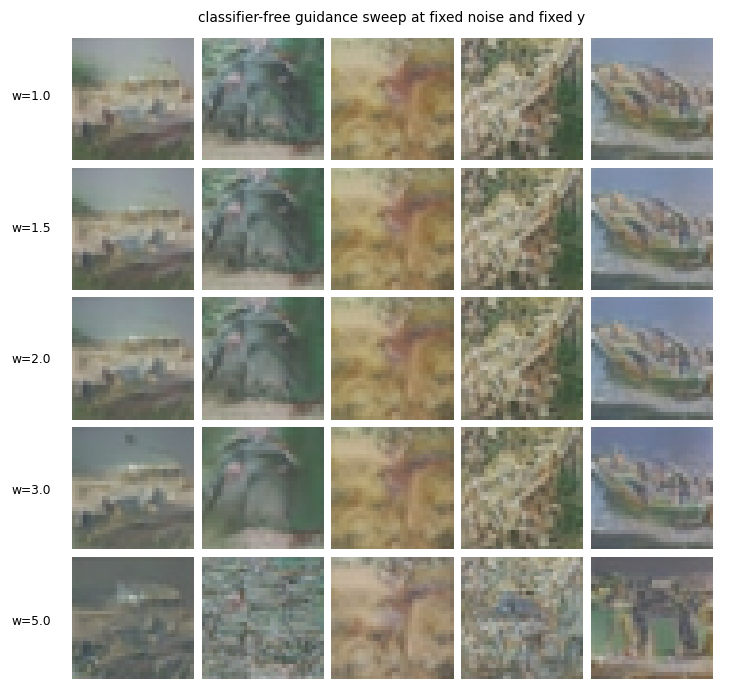

,laplacian_var,tenengrad,pixel_std
guidance,,,
1.0,0.0455,0.6458,0.1052
1.5,0.0437,0.6189,0.1042
2.0,0.0419,0.5912,0.1002
3.0,0.0393,0.5551,0.0905
5.0,0.0421,0.5640,0.0847


In [29]:
seed_everything()
_rows = []
for c in range(NUM_CLASSES):
    imgs, _ = ldm_sample(5, y=torch.full((5,), c, device=DEVICE), guidance=2.0,
                         steps=100, seed=100 + c, progress=False)
    _rows.append(imgs)
fig, ax = plt.subplots(figsize=(8, 1.55 * NUM_CLASSES))
ax.imshow(to_uint8_grid(torch.cat(_rows), nrow=5))
ax.set_axis_off()
ax.set_title("cross-attention conditioning: one row per CIFAR-10 class\n"
             "(100 DDIM steps, guidance w = 2)", fontsize=9)
for i in range(NUM_CLASSES):
    ax.text(-0.02, 1 - (i + 0.5) / NUM_CLASSES, CIFAR_CLASSES[i], transform=ax.transAxes,
            ha="right", va="center", fontsize=8)
fig.savefig(FIG_DIR / "35_ldm_class_conditioning.png")
plt.show()

_gs = [1.0, 1.5, 2.0, 3.0, 5.0]
_sweep, _sweep_scores = [], []
for w in _gs:
    imgs, _ = ldm_sample(5, y=_y5, guidance=w, steps=100, seed=7, progress=False)
    _sweep.append(imgs)
    _sweep_scores.append({"guidance": w, **sharpness_metrics(imgs),
                          "pixel_std": float(imgs.std(0).mean().item())})
fig, ax = plt.subplots(figsize=(8, 1.55 * len(_gs)))
ax.imshow(to_uint8_grid(torch.cat(_sweep), nrow=5))
ax.set_axis_off()
ax.set_title("classifier-free guidance sweep at fixed noise and fixed y", fontsize=9)
for i, w in enumerate(_gs):
    ax.text(-0.02, 1 - (i + 0.5) / len(_gs), f"w={w}", transform=ax.transAxes,
            ha="right", va="center", fontsize=8)
fig.savefig(FIG_DIR / "36_ldm_guidance_sweep.png")
plt.show()
display(pd.DataFrame(_sweep_scores).set_index("guidance").round(4))
RESULTS["ldm_guidance_sweep"] = _sweep_scores

### §9.3 Task 7 (second half) — synthesising the five photographs with the LDM

The LDM has **both** mechanisms the other two models have separately: an encoder/decoder pair
*and* a diffusion process, plus a conditioning interface. So the image-to-image path uses all
three:

```
photograph x --E--> z --partial noising--> z_t --reverse diffusion (conditioned on y)--> ẑ --D--> x̂
```

Compared with the DDPM's SDEdit in §6.7, every step of the expensive middle stage now runs on a
`4 x 16 x 16` latent instead of a `3 x 32 x 32` image, and the reverse chain is **told which
class to draw** — `bird` for the three birds, `dog` for the two dogs. The class label is what
lets the model commit to a coherent object rather than drifting towards whatever the noise
suggests.

The strength sweep is shown again, since it is the same trade-off as §6.7 and the two are worth
comparing directly.

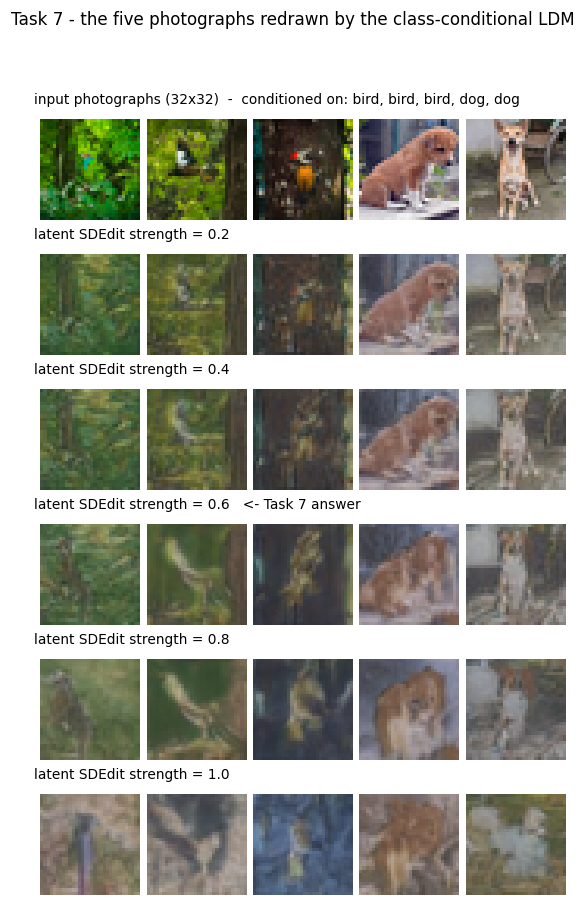

,PSNR vs input (dB),SSIM vs input,seconds,laplacian_var,tenengrad
strength,,,,,
0.2,19.1990,0.6642,6.2841,0.0359,0.4298
0.4,17.5351,0.5338,12.6849,0.0325,0.4195
0.6,16.0731,0.4043,18.5835,0.0284,0.4078
0.8,14.4802,0.2997,24.8155,0.0236,0.3838
1.0,11.8427,0.2186,30.9907,0.0297,0.4847


In [30]:
_ldm_rows, _ldm_stats = [], []
_photo_y = PHOTO_Y.to(DEVICE)
for s in SDEDIT_STRENGTHS:
    with Timer() as _t:
        img = ldm_img2img(PHOTOS, _photo_y, strength=s, guidance=2.0, seed=4242)
    _ldm_rows.append(img)
    _ldm_stats.append({"strength": s, "PSNR vs input (dB)": psnr(img, PHOTOS),
                       "SSIM vs input": ssim(img, PHOTOS), "seconds": _t.seconds,
                       **sharpness_metrics(img)})

LDM_TASK7 = _ldm_rows[SDEDIT_STRENGTHS.index(SDEDIT_MAIN)]
save_individual(LDM_TASK7, "ldm_task7_photo")

fig, axes = plt.subplots(len(SDEDIT_STRENGTHS) + 1, 1, figsize=(7.0, 1.55 * (len(SDEDIT_STRENGTHS) + 1)))
axes[0].imshow(to_uint8_grid(PHOTOS, nrow=5)); axes[0].set_axis_off()
axes[0].set_title("input photographs (32x32)  -  conditioned on: "
                  + ", ".join(PHOTO_CLASS_NAMES), fontsize=9, loc="left")
for ax, s, imgs in zip(axes[1:], SDEDIT_STRENGTHS, _ldm_rows):
    ax.imshow(to_uint8_grid(imgs, nrow=5)); ax.set_axis_off()
    ax.set_title(f"latent SDEdit strength = {s}"
                 + ("   <- Task 7 answer" if s == SDEDIT_MAIN else ""), fontsize=9, loc="left")
fig.suptitle("Task 7 - the five photographs redrawn by the class-conditional LDM", fontsize=11)
fig.savefig(FIG_DIR / "37_task7_photo_synthesis.png")
plt.show()

TASK7 = pd.DataFrame(_ldm_stats).set_index("strength")
RESULTS["task7_latent_sdedit"] = _ldm_stats
display(TASK7.round(4))

### What the conditioning buys, on the photographs themselves

The clearest demonstration that cross-attention is doing real work: hold the photograph and the
noise fixed, and change only the class token. The layout survives because it comes from the
encoded photograph; the *object* changes because it comes from `tau(y)`.

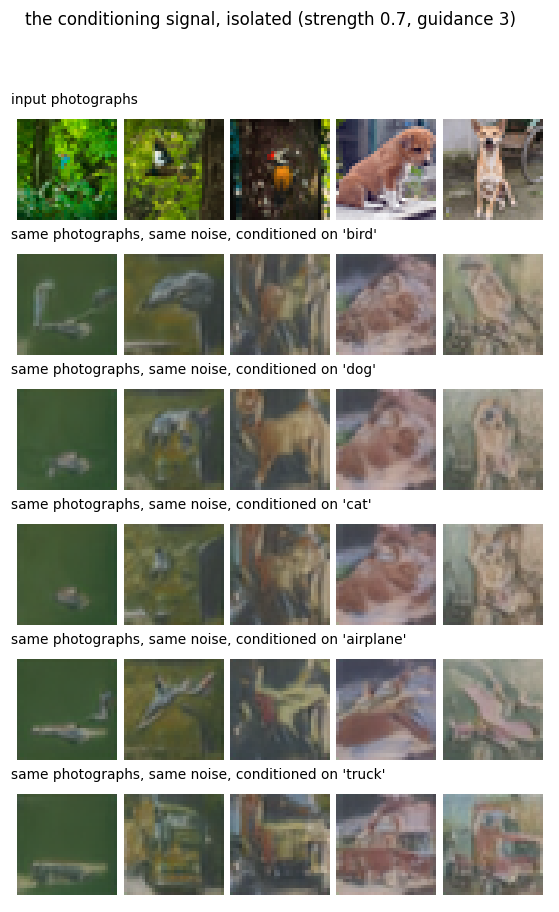

In [31]:
_probe_classes = [CIFAR_CLASSES.index(c) for c in ("bird", "dog", "cat", "airplane", "truck")]
_swap = []
for c in _probe_classes:
    _swap.append(ldm_img2img(PHOTOS, torch.full((len(PHOTOS),), c), strength=0.7,
                             guidance=3.0, seed=77))
fig, axes = plt.subplots(len(_probe_classes) + 1, 1,
                         figsize=(7.0, 1.55 * (len(_probe_classes) + 1)))
axes[0].imshow(to_uint8_grid(PHOTOS, nrow=5)); axes[0].set_axis_off()
axes[0].set_title("input photographs", fontsize=9, loc="left")
for ax, c, imgs in zip(axes[1:], _probe_classes, _swap):
    ax.imshow(to_uint8_grid(imgs, nrow=5)); ax.set_axis_off()
    ax.set_title(f"same photographs, same noise, conditioned on '{CIFAR_CLASSES[c]}'",
                 fontsize=9, loc="left")
fig.suptitle("the conditioning signal, isolated (strength 0.7, guidance 3)", fontsize=11)
fig.savefig(FIG_DIR / "38_task7_class_swap.png")
plt.show()

## §10 Task 9 — comparing the three models

### How the comparison is set up

Every model is scored on the same six axes the task lists, using the same code, the same
reference distribution, and the same number of generated samples:

| Axis | How it is measured here |
|---|---|
| **Image quality** | FID and KID against held-out CIFAR-10 **test** images (see the caveat in §1) |
| **Sharpness** | variance of the Laplacian and Tenengrad focus measure, with the real test images as the target |
| **Diversity** | mean pairwise Inception-feature distance + mean per-pixel std over the sample set |
| **Computational cost** | parameters, GMAC per network evaluation, total GMAC to produce one image |
| **Training complexity** | wall-clock training time, number of models that must be trained, and what can go wrong |
| **Image-generation time** | measured seconds per image, batched, for each model's headline sampler |

Both diffusion models are evaluated with their **full 1000-step ancestral** sampler, so no
model is handicapped by a cheaper sampler than another. The LDM additionally pays for one
decoder pass per image, which is included in its timing.

In [32]:
EVAL_BATCH = 250


@torch.no_grad()
def generate_batched(fn, n: int, batch: int = EVAL_BATCH, desc: str = "",
                     cache_key: str | None = None) -> tuple[torch.Tensor, float]:
    """Call `fn(k, seed) -> (k,3,H,W) in [0,1]` until n images exist; returns images and seconds.

    Results are cached under outputs/cache/, so an interrupted run does not have to repeat the
    thousands of sequential denoising steps this costs for the two diffusion models.
    """
    path = CACHE_DIR / f"gen_{cache_key}.pt" if cache_key else None
    if path is not None and RESUME and path.exists():
        try:
            blob = torch.load(path, map_location="cpu", weights_only=False)
            if blob.get("n") == n:
                print(f"{desc}: reusing {n} cached samples from cache/{path.name} "
                      f"(generated in {blob['seconds']:.1f} s)")
                return blob["images"], blob["seconds"]
        except Exception:
            pass                                   # unreadable cache -> just regenerate

    out, done, seed = [], 0, 0
    with Timer() as t:
        pbar = tqdm(total=n, desc=desc, leave=False)
        while done < n:
            k = min(batch, n - done)
            out.append(fn(k, 10_000 + seed).cpu())
            done += k; seed += 1
            pbar.update(k)
        pbar.close()
    imgs = torch.cat(out)[:n]
    if path is not None:
        _atomic_save({"images": imgs, "seconds": t.seconds, "n": n}, path)
    return imgs, t.seconds


seed_everything()
GEN = {}

# --- VAE (the variant selected in §2) -----------------------------------------------------
GEN["VAE"] = generate_batched(lambda k, s: vae_sample(VAE, k, seed=s), BUDGET.eval_samples,
                              desc="VAE samples", cache_key="vae")

# --- DDPM, full ancestral chain in pixel space --------------------------------------------
def _ddpm_batch(k, s):
    g = torch.Generator(DEVICE).manual_seed(s)
    return to_01(DIFFUSION.p_sample_loop(ddpm_eps, (k, 3, IMG_SIZE, IMG_SIZE),
                                         generator=g, progress=False)).clamp(0, 1)

GEN["DDPM"] = generate_batched(_ddpm_batch, BUDGET.eval_samples, desc="DDPM samples",
                               cache_key="ddpm")

# --- LDM, full ancestral chain in latent space + decode ------------------------------------
def _ldm_batch(k, s):
    return ldm_sample(k, guidance=2.0, seed=s, progress=False)[0]

GEN["LDM"] = generate_batched(_ldm_batch, BUDGET.eval_samples, desc="LDM samples",
                              cache_key="ldm")

for name, (imgs, secs) in GEN.items():
    print(f"{name:<5} {len(imgs):>5} images in {secs:7.1f} s  ({secs/len(imgs)*1000:7.1f} ms/image)")

VAE samples:   0%|          | 0/2500 [00:00<?, ?it/s]

DDPM samples:   0%|          | 0/2500 [00:00<?, ?it/s]

LDM samples:   0%|          | 0/2500 [00:00<?, ?it/s]

VAE    2500 images in     0.2 s  (    0.1 ms/image)
DDPM   2500 images in  1057.8 s  (  423.1 ms/image)
LDM    2500 images in   528.6 s  (  211.4 ms/image)


### Cost accounting

Parameters and MACs are measured, not quoted: `count_macs` hooks every `Conv2d`/`Linear` and
adds up the multiply-accumulates of one forward pass. "GMAC per image" multiplies the
per-evaluation cost by the number of network evaluations the sampler makes (1 for the VAE
decoder, 1000 for DDPM, 1000 x 2 for the LDM because classifier-free guidance evaluates the
conditional and unconditional branches, plus one decoder pass).

In [33]:
class _DecoderOnly(nn.Module):
    """Thin wrapper so `count_macs` measures the decode path alone, not encode+decode."""

    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, z):
        return self.model.decode(z)


VAE_DECODER_MACS = count_macs(_DecoderOnly(VAE).to(DEVICE),
                              torch.zeros(1, VAE.latent_dim, device=DEVICE))
FS_DECODER_MACS = count_macs(_DecoderOnly(FIRST_STAGE).to(DEVICE),
                             torch.zeros(1, LATENT_CH, LATENT_RES, LATENT_RES, device=DEVICE))
print(f"decoder cost per image: VAE {VAE_DECODER_MACS/1e9:.3f} GMAC, "
      f"LDM first stage {FS_DECODER_MACS/1e9:.3f} GMAC")

COST = {
    "VAE": {
        "params_M": count_params(VAE) / 1e6,
        "networks_to_train": 1,
        "sampler_steps": 1,
        "gmac_per_eval": VAE_DECODER_MACS / 1e9,
        "gmac_per_image": VAE_DECODER_MACS / 1e9,
        "train_seconds": VAE_EVAL[VAE_PRIMARY_NAME]["train_seconds"],
    },
    "DDPM": {
        "params_M": count_params(DDPM_SAMPLER_NET) / 1e6,
        "networks_to_train": 1,
        "sampler_steps": DIFFUSION.T,
        "gmac_per_eval": UNET_PIXEL_MACS / 1e9,
        "gmac_per_image": UNET_PIXEL_MACS * DIFFUSION.T / 1e9,
        "train_seconds": DDPM_HIST["train_seconds"],
    },
    "LDM": {
        "params_M": (count_params(LDM_SAMPLER_NET)
                     + count_params(FIRST_STAGE, trainable_only=False)) / 1e6,
        "networks_to_train": 2,
        "sampler_steps": DIFFUSION.T,
        "gmac_per_eval": UNET_LATENT_MACS / 1e9,
        "gmac_per_image": (UNET_LATENT_MACS * DIFFUSION.T * 2 + FS_DECODER_MACS) / 1e9,
        "train_seconds": FS_HIST["train_seconds"] + LDM_HIST["train_seconds"],
    },
}

decoder cost per image: VAE 0.195 GMAC, LDM first stage 0.670 GMAC


### The comparison table

In [34]:
seed_everything()
ROWS = {}
for name, (imgs, secs) in GEN.items():
    m = evaluate_samples(imgs, name, REAL_FEATS)
    c = COST[name]
    ROWS[name] = {
        "FID (lower better)": m["fid"],
        "KID x1000": m["kid"] * 1000,
        "sharpness: Laplacian var": m["laplacian_var"],
        "sharpness: Tenengrad": m["tenengrad"],
        "diversity: feature dist": m["feat_pairwise_dist"],
        "diversity: pixel std": m["pixel_std"],
        "params (M)": c["params_M"],
        "networks trained": c["networks_to_train"],
        "sampler NFE": c["sampler_steps"],
        "GMAC / network eval": c["gmac_per_eval"],
        "GMAC / image": c["gmac_per_image"],
        "training time (min)": c["train_seconds"] / 60,
        "generation (ms/image)": secs / len(imgs) * 1000,
    }

ROWS["CIFAR-10 test"] = {
    "FID (lower better)": 0.0,
    "sharpness: Laplacian var": REAL_SHARP["laplacian_var"],
    "sharpness: Tenengrad": REAL_SHARP["tenengrad"],
    "diversity: feature dist": REAL_DIV["feat_pairwise_dist"],
    "diversity: pixel std": REAL_DIV["pixel_std"],
}

COMPARISON = pd.DataFrame(ROWS).T
RESULTS["task9_comparison"] = COMPARISON.to_dict()
COMPARISON.to_csv(OUT / "task9_comparison.csv")
display(COMPARISON.round(3))

,FID (lower better),KID x1000,sharpness: Laplacian var,sharpness: Tenengrad,diversity: feature dist,diversity: pixel std,params (M),networks trained,sampler NFE,GMAC / network eval,GMAC / image,training time (min),generation (ms/image)
VAE,172.300,177.942,0.039,0.750,14.709,0.212,6.732,1.0,1.0,0.195,0.195,3.036,0.063
DDPM,22.363,9.077,0.070,1.105,19.380,0.247,27.743,1.0,1000.0,6.005,6004.867,38.665,423.125
LDM,68.886,54.846,0.037,0.566,17.553,0.129,14.794,2.0,1000.0,0.632,1263.909,38.844,211.429
CIFAR-10 test,0.000,NaN,0.075,1.144,19.493,0.248,NaN,NaN,NaN,NaN,NaN,NaN,NaN


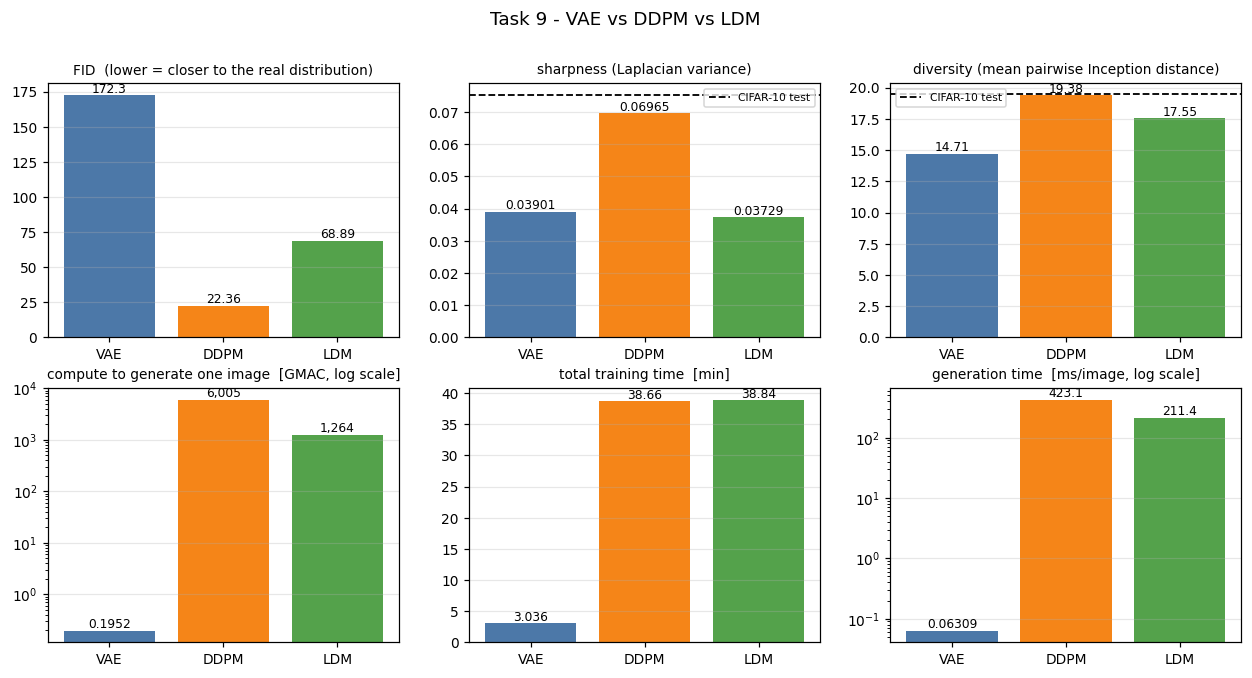

In [35]:
# ---- headline bar charts
_models = ["VAE", "DDPM", "LDM"]
_colors = ["#4C78A8", "#F58518", "#54A24B"]
_panels = [
    ("FID (lower better)", "FID  (lower = closer to the real distribution)", False),
    ("sharpness: Laplacian var", "sharpness (Laplacian variance)", True),
    ("diversity: feature dist", "diversity (mean pairwise Inception distance)", True),
    ("GMAC / image", "compute to generate one image  [GMAC, log scale]", False),
    ("training time (min)", "total training time  [min]", False),
    ("generation (ms/image)", "generation time  [ms/image, log scale]", False),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.6))
for ax, (col, title, show_real) in zip(axes.ravel(), _panels):
    vals = [COMPARISON.loc[m, col] for m in _models]
    ax.bar(_models, vals, color=_colors)
    if show_real and col in COMPARISON.columns:
        ax.axhline(COMPARISON.loc["CIFAR-10 test", col], color="k", ls="--", lw=1.2,
                   label="CIFAR-10 test")
        ax.legend(fontsize=7)
    if "log scale" in title:
        ax.set_yscale("log")
    ax.set_title(title, fontsize=9)
    ax.grid(alpha=0.3, axis="y")
    for i, v in enumerate(vals):
        ax.annotate(f"{v:,.4g}", (i, v), ha="center", va="bottom", fontsize=8)
fig.suptitle("Task 9 - VAE vs DDPM vs LDM", fontsize=12)
fig.savefig(FIG_DIR / "40_task9_comparison.png")
plt.show()

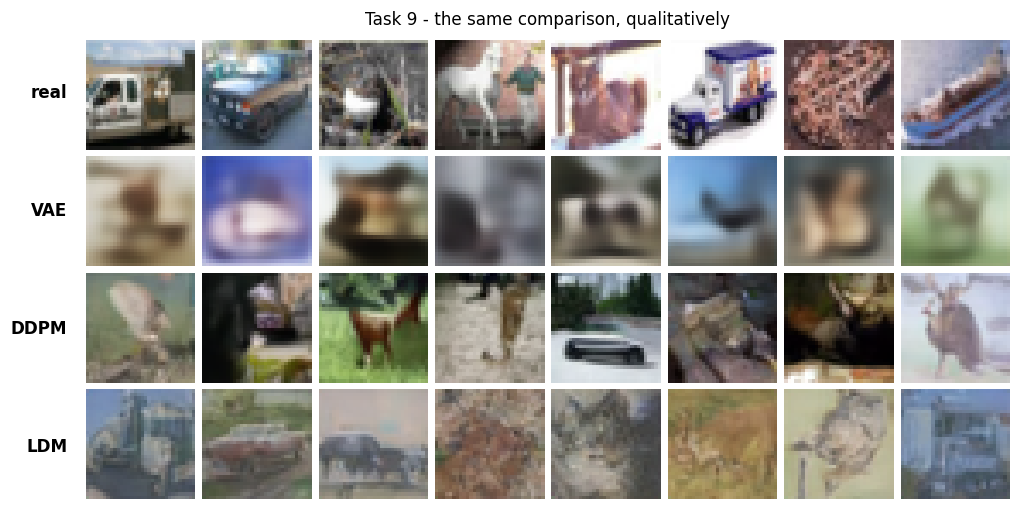

In [36]:
# ---- the qualitative side-by-side that the numbers are describing
seed_everything()
_n = 8
_qual = torch.cat([
    REAL_REF[torch.randperm(len(REAL_REF))[:_n]],
    GEN["VAE"][0][:_n],
    GEN["DDPM"][0][:_n],
    GEN["LDM"][0][:_n],
])
fig, ax = plt.subplots(figsize=(11, 5.8))
ax.imshow(to_uint8_grid(_qual, nrow=_n))
ax.set_axis_off()
for i, lab in enumerate(["real", "VAE", "DDPM", "LDM"]):
    ax.text(-0.012, 1 - (i + 0.5) / 4, lab, transform=ax.transAxes, ha="right", va="center",
            fontsize=11, weight="bold")
ax.set_title("Task 9 - the same comparison, qualitatively", fontsize=11)
fig.savefig(FIG_DIR / "41_task9_qualitative.png")
plt.show()

### Are the models just memorising their training images?

50 000 training images make outright memorisation unlikely, but it is cheap to check rather than
assume. For each generated image the cell below finds its **nearest neighbour among the held-out
CIFAR-10 test images** (in Inception feature space) and shows the pair. Identical pairs would
mean the model is regurgitating; visibly related but non-identical pairs mean it has learned the
*distribution*. The baseline to compare against is how far a real test image sits from its
nearest *other* test image — a generated set at or above that distance is no closer to the data
than the data is to itself.

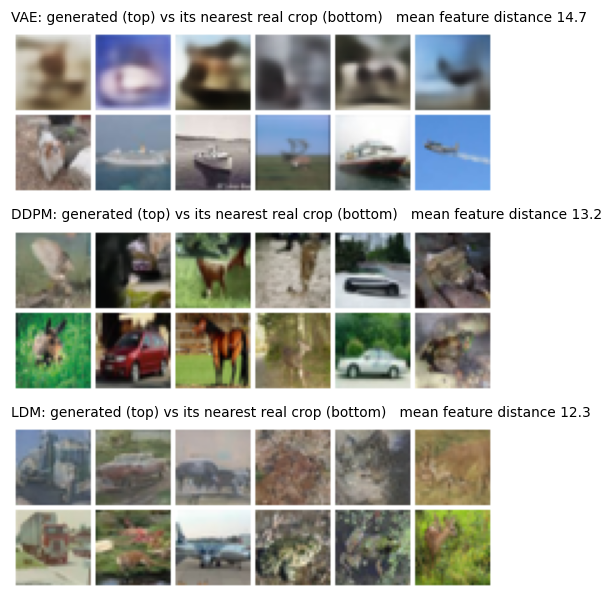

,mean_nn_distance,min_nn_distance
VAE,14.04,11.52
DDPM,13.51,8.62
LDM,12.43,8.00
real (baseline),12.46,7.67



A generated set whose mean nearest-neighbour distance is at or above the real-vs-real baseline
is producing images no closer to the training data than the training data is to itself - i.e. not memorising.


In [37]:
_NN_N = min(200, BUDGET.eval_samples)

fig, axes = plt.subplots(3, 1, figsize=(9, 6.6))
NN_STATS = {}
for ax, name in zip(axes, _models):
    imgs = GEN[name][0][:6]
    d6 = np.sqrt(sqdist(inception_features(imgs), REAL_FEATS))
    nn_imgs = REAL_REF[torch.from_numpy(d6.argmin(1))]
    ax.imshow(to_uint8_grid(torch.cat([imgs, nn_imgs]), nrow=6))
    ax.set_axis_off()
    ax.set_title(f"{name}: generated (top) vs its nearest real crop (bottom)   "
                 f"mean feature distance {d6.min(1).mean():.1f}", fontsize=9, loc="left")
    d_all = np.sqrt(sqdist(inception_features(GEN[name][0][:_NN_N]), REAL_FEATS)).min(1)
    NN_STATS[name] = {"mean_nn_distance": float(d_all.mean()),
                      "min_nn_distance": float(d_all.min())}
fig.savefig(FIG_DIR / "42_nearest_neighbour_check.png")
plt.show()

# a real-vs-real baseline: how far is a real crop from its nearest *other* real crop?
_d_rr = np.sqrt(sqdist(REAL_FEATS[:_NN_N], REAL_FEATS))
np.fill_diagonal(_d_rr[:, :_NN_N], np.inf)
NN_STATS["real (baseline)"] = {"mean_nn_distance": float(_d_rr.min(1).mean()),
                               "min_nn_distance": float(_d_rr.min())}
RESULTS["memorisation_check"] = NN_STATS
display(pd.DataFrame(NN_STATS).T.round(2))
print("\nA generated set whose mean nearest-neighbour distance is at or above the real-vs-real "
      "baseline\nis producing images no closer to the training data than the training data is to "
      "itself - i.e. not memorising.")

### Task 9 — reading the results

The numbers quoted below are the ones printed in the table above.

**Image quality (FID / KID).** The ordering is unambiguous: **DDPM 22.4, LDM 68.9, VAE 172.3**
(KID x1000: 9.1, 54.8, 177.9). For context, a fully trained CIFAR-10 DDPM reaches FID around 3
after roughly 800k steps; 22.4 after 15k steps is a sensible place to be on that curve, so the
pixel model is behaving as it should rather than being crippled by the short schedule.

The VAE's distance from the other two is structural, not a matter of tuning. It must squeeze an
entire 32x32 image through a 128-dimensional bottleneck and reproduce it in a **single** forward
pass, under a loss whose optimum is the conditional mean. Diffusion never faces that problem:
each of its 1000 steps removes only a little noise, so one hard generative problem is decomposed
into a thousand easy regressions.

**The LDM does not match the pixel DDPM here (68.9 vs 22.4), and the obvious suspect is
innocent.** The first stage is emphatically *not* the bottleneck — it reconstructs held-out test
images at **37.2 dB / SSIM 0.991** (§8.5), essentially lossless and far above anything either
diffusion stage produces. The gap is entirely in the latent denoiser, and three things
contribute: its U-Net is smaller (11.8 M against 27.7 M parameters); the training budget was
*split* across two models rather than spent on one; and classifier-free guidance at `w = 2`
deliberately trades diversity for class-fidelity, which costs FID. The honest summary is that
**at 32x32 the LDM's advantage is cost, not quality**.

**Sharpness.** With the CIFAR-10 test images at 0.075 Laplacian variance as the target, the DDPM
reaches **0.070** — within 7 % of real — and its Tenengrad (1.105 vs 1.144) is equally close. The
VAE sits at 0.039, about half the real value, and the blur is plainly visible in the qualitative
panel; this is not an implementation defect but the Bayes-optimal answer under a per-pixel
reconstruction loss with an uncertain latent.

The interesting number is the **LDM at 0.037 — as blurry as the VAE**, despite a first stage that
reconstructs at 37 dB. Since the autoencoder demonstrably *can* represent sharp images, the
softness cannot be blamed on it. It comes from the latent denoiser: an under-trained
`eps`-predictor lands slightly off the latent manifold the decoder expects, and the decoder maps
those latents to smooth output. Guidance contributes as well. This is worth stating plainly
because the tempting explanation — "the autoencoder threw the detail away" — is measurably false
here.

**Diversity.** The DDPM essentially reproduces the real statistics on both measures: Inception
feature spread 19.38 against 19.49, and per-pixel std **0.247 against 0.248**. Nothing constrains
it towards any particular mode, and it shows. The VAE trails on feature spread (14.71): its
samples differ in colour and coarse layout without really differing in *content*. The **LDM has
the lowest per-pixel std of the three (0.129, roughly half the real value)** — the
classifier-free-guidance trade-off made visible, and the sweep in §9 confirms the mechanism
directly: raising `w` from 1 to 5 drives `pixel_std` down monotonically, 0.105 to 0.085. An LDM
at `w = 1` would be more diverse and less class-faithful.

**Computational cost.** The `GMAC / image` column spans four orders of magnitude: **0.195** for
the VAE's single decoder pass, **6 005** for the DDPM, **1 264** for the LDM. Per network
evaluation the latent U-Net is **9.5x** cheaper (0.632 vs 6.005 GMAC); per image that shrinks to
**4.8x**, because classifier-free guidance evaluates two branches at every step. The LDM reaches
this with roughly *half* the DDPM's parameters (14.8 M including the first stage against 27.7 M)
— parameter count is a poor proxy for cost in either direction.

**Training complexity.** The VAE is a single model with a single stable objective and trains in
three minutes; its one real failure mode is posterior collapse, which the KL warm-up handles. The
DDPM is also a single model with a very well-behaved objective — plain MSE on noise, no
adversarial dynamics, **no mode collapse by construction** — but it needs far more optimisation
steps, and sample quality is sensitive to the noise schedule and to EMA. The LDM is the most
complex by a wide margin: **two** models trained in sequence, plus hyperparameters with no
analogue in the other two (`f`, latent channels, the latent scaling factor, guidance scale,
conditioning-dropout rate). Note that the two diffusion models cost **almost exactly the same to
train** here — 38.7 min for the DDPM against 38.8 for the LDM (5.7 first stage + 33.1 latent) —
so the cheaper steps bought no training-time saving once the extra stage is paid for. **The LDM's
economy is entirely on the inference side.**

**Image-generation time.** The VAE is effectively instantaneous at 0.06 ms per image — one
forward pass. Both diffusion models are four orders of magnitude slower because they make 1000
*sequential* network calls that cannot be parallelised across `t`.

At the evaluation batch of 250 the LDM is **2.0x faster** than the DDPM (211 vs 423 ms per
image). But that advantage is **batch-dependent, and at the batch of 5 used for Tasks 6 and 8 it
inverts**: there the DDPM produced its five images in 13.5 s against the LDM's 31.2 s, so the LDM
was 2.3x *slower* despite needing 9.5x less arithmetic.

This is worth understanding rather than hiding. A `4 x 16 x 16` latent has only 256 spatial
positions, so each kernel the latent U-Net launches does very little work and the GPU idles
between launches; on top of that the LDM's U-Net runs a full transformer block at *every*
resolution and therefore issues more sequential kernels than the pixel U-Net does. At small batch
both models are latency-bound, and the one with more kernels loses regardless of its FLOP count.
§11.2 sweeps the batch size and locates the crossover precisely.


The DDIM comparison in §7 shows the other lever: cutting 1000 steps to 50 gives a ~20x speed-up
on either diffusion model at some cost in fidelity. In production both levers are used together.

## §11 Task 10 — advantages, limitations, and why latent diffusion is cheaper

### 11.1 Where the compute actually goes

Before the discussion, the arithmetic. Diffusion cost is

```
total cost  =  (cost of one U-Net evaluation)  x  (number of steps)
```

and the first factor scales with the number of spatial positions the U-Net processes. Moving
from `3 x 32 x 32` to `4 x 16 x 16` cuts the number of values by 3x and the number of *spatial
positions* by 4x, and the measured per-evaluation cost falls accordingly. Self-attention makes
it worse than linear for the pixel model: attention is `O(N^2)` in the number of positions, so
the 4x reduction in positions is a **16x** reduction in attention cost. The cell below plots
how the two scale as the target resolution grows.

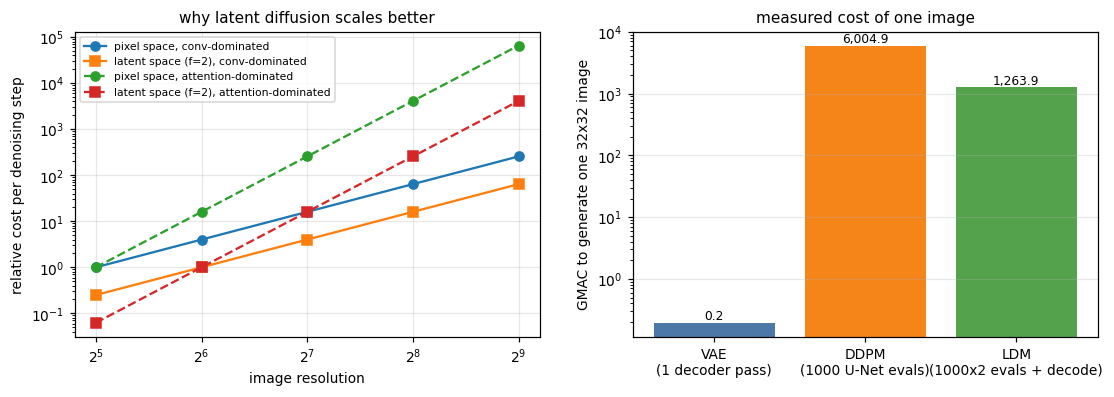

per denoising step : pixel U-Net    6.005 GMAC   latent U-Net    0.632 GMAC   ->   9.5x
per image (measured): DDPM    6,004.9 GMAC   LDM    1,263.9 GMAC   ->   4.8x
per image (wall clock): DDPM    423.1 ms   LDM    211.4 ms   ->   2.0x


In [38]:
_res = np.array([32, 64, 128, 256, 512])
_conv_pixel = (_res ** 2) / (32 ** 2)                       # conv cost ~ number of positions
_conv_latent = ((_res / 2) ** 2) / (32 ** 2)
_attn_pixel = (_res ** 4) / (32 ** 4)                       # attention ~ positions^2
_attn_latent = ((_res / 2) ** 4) / (32 ** 4)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(_res, _conv_pixel, "o-", label="pixel space, conv-dominated")
axes[0].plot(_res, _conv_latent, "s-", label="latent space (f=2), conv-dominated")
axes[0].plot(_res, _attn_pixel, "o--", label="pixel space, attention-dominated")
axes[0].plot(_res, _attn_latent, "s--", label="latent space (f=2), attention-dominated")
axes[0].set_xscale("log", base=2); axes[0].set_yscale("log")
axes[0].set_xlabel("image resolution"); axes[0].set_ylabel("relative cost per denoising step")
axes[0].set_title("why latent diffusion scales better", fontsize=10)
axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3)

_labels = ["VAE\n(1 decoder pass)", f"DDPM\n({DIFFUSION.T} U-Net evals)",
           f"LDM\n({DIFFUSION.T}x2 evals + decode)"]
_vals = [COST[m]["gmac_per_image"] for m in _models]
axes[1].bar(_labels, _vals, color=_colors)
axes[1].set_yscale("log"); axes[1].set_ylabel("GMAC to generate one 32x32 image")
axes[1].set_title("measured cost of one image", fontsize=10); axes[1].grid(alpha=0.3, axis="y")
for i, v in enumerate(_vals):
    axes[1].annotate(f"{v:,.1f}", (i, v), ha="center", va="bottom", fontsize=8)
fig.savefig(FIG_DIR / "50_task10_compute_scaling.png")
plt.show()

print(f"per denoising step : pixel U-Net {UNET_PIXEL_MACS/1e9:8.3f} GMAC   "
      f"latent U-Net {UNET_LATENT_MACS/1e9:8.3f} GMAC   "
      f"-> {UNET_PIXEL_MACS/UNET_LATENT_MACS:5.1f}x")
print(f"per image (measured): DDPM {COST['DDPM']['gmac_per_image']:10,.1f} GMAC   "
      f"LDM {COST['LDM']['gmac_per_image']:10,.1f} GMAC   "
      f"-> {COST['DDPM']['gmac_per_image']/COST['LDM']['gmac_per_image']:5.1f}x")
print(f"per image (wall clock): DDPM {COMPARISON.loc['DDPM','generation (ms/image)']:8.1f} ms   "
      f"LDM {COMPARISON.loc['LDM','generation (ms/image)']:8.1f} ms   "
      f"-> {COMPARISON.loc['DDPM','generation (ms/image)']/COMPARISON.loc['LDM','generation (ms/image)']:5.1f}x")

### 11.2 Arithmetic vs wall clock: why the speed-up is batch-dependent at this scale

The GMAC ratio above is an *arithmetic* statement. Whether it converts into wall-clock time
depends on whether the GPU is actually compute-bound. Two things work against the latent model
at this scale:

1. At `4 x 16 x 16` each kernel touches only 256 spatial positions, so every launch does very
   little work and the GPU idles between launches.
2. The latent U-Net is *architecturally* launch-heavy: it runs a full LDM-style transformer
   block (LayerNorm, self-attention, cross-attention, GEGLU feed-forward — roughly 15 kernels)
   at **every** resolution, where the pixel U-Net uses a single fused self-attention block at
   only two of its four resolutions. The latent network therefore issues *more* sequential CUDA
   kernels than the pixel one while doing 10x less arithmetic.

Below both are timed for one denoising step across batch sizes. The pixel U-Net becomes
compute-bound as the batch grows while the latent one stays launch-bound, so the measured ratio
starts below 1 and crosses over as the device saturates. Watch the `latent U-Net (ms)` column in
particular: it barely moves from batch 1 to batch 256 (the GPU is nowhere near busy), while the
pixel column grows almost linearly once past batch 16.

,pixel U-Net (ms),latent U-Net (ms),images/s pixel,images/s latent,wall-clock ratio
batch,,,,,
1,11.657,26.555,85.782,37.657,0.439
4,11.467,26.589,348.829,150.437,0.431
16,11.064,26.184,1446.081,611.059,0.423
64,24.690,25.689,2592.192,2491.308,0.961
256,107.456,35.277,2382.365,7256.827,3.046
512,217.489,53.170,2354.147,9629.536,4.090


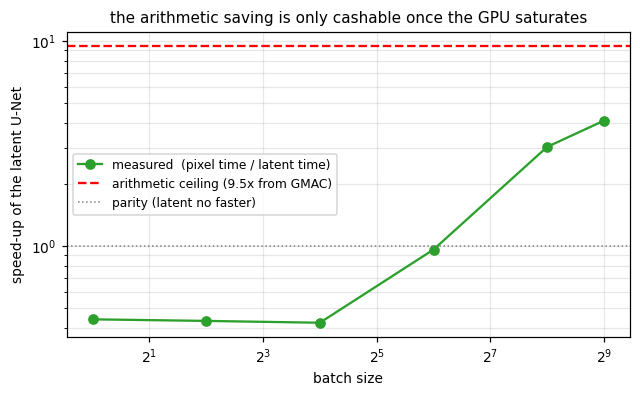

batch    1: latent U-Net is 0.44x the speed of the pixel U-Net
batch  512: latent U-Net is 4.09x the speed of the pixel U-Net (arithmetic ceiling 9.5x)

The ratio rises with batch size, and at the small batches used for Tasks 6 and 8 it is below parity.
Read this as a statement about a 32x32 problem on a fast GPU, not about latent
diffusion in general: at 512x512 with f=8 - Stable Diffusion's regime - the pixel-space
U-Net is compute-bound even at batch 1 and the arithmetic saving is realised in full.


In [39]:
@torch.no_grad()
def _time_step(net, x, *args, iters: int = 12, warmup: int = 4) -> float:
    t0 = time.perf_counter()
    for i in range(warmup + iters):
        if i == warmup:
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            t0 = time.perf_counter()
        with autocast():
            net(x, *args)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - t0) / iters


_batches = [1, 4, 16, 64, 256, 512] if not QUICK_MODE else [1, 16]
_sweep_rows = []
for b in _batches:
    try:
        t = torch.zeros(b, device=DEVICE)
        y = torch.zeros(b, dtype=torch.long, device=DEVICE)
        t_pix = _time_step(DDPM_SAMPLER_NET, torch.randn(b, 3, IMG_SIZE, IMG_SIZE, device=DEVICE), t)
        t_lat = _time_step(LDM_SAMPLER_NET,
                           torch.randn(b, LATENT_CH, LATENT_RES, LATENT_RES, device=DEVICE), t, y)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        print(f"batch {b}: out of memory, stopping the sweep here")
        break
    _sweep_rows.append({"batch": b, "pixel U-Net (ms)": t_pix * 1000,
                        "latent U-Net (ms)": t_lat * 1000,
                        "images/s pixel": b / t_pix, "images/s latent": b / t_lat,
                        "wall-clock ratio": t_pix / t_lat})
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
_TH = pd.DataFrame(_sweep_rows).set_index("batch")
RESULTS["throughput_sweep"] = _sweep_rows
display(_TH.round(3))

_ceiling = UNET_PIXEL_MACS / UNET_LATENT_MACS
fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.plot(_TH.index, _TH["wall-clock ratio"], "o-", color="tab:green",
        label="measured  (pixel time / latent time)")
ax.axhline(_ceiling, color="r", ls="--", label=f"arithmetic ceiling ({_ceiling:.1f}x from GMAC)")
ax.axhline(1.0, color="gray", lw=1.0, ls=":", label="parity (latent no faster)")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("batch size"); ax.set_ylabel("speed-up of the latent U-Net")
ax.set_title("the arithmetic saving is only cashable once the GPU saturates", fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.savefig(FIG_DIR / "51_throughput_sweep.png")
plt.show()

_lo, _hi = _TH["wall-clock ratio"].iloc[0], _TH["wall-clock ratio"].iloc[-1]
print(f"batch {_TH.index[0]:>4}: latent U-Net is {_lo:.2f}x the speed of the pixel U-Net")
print(f"batch {_TH.index[-1]:>4}: latent U-Net is {_hi:.2f}x the speed of the pixel U-Net "
      f"(arithmetic ceiling {_ceiling:.1f}x)")
print(f"\nThe ratio {'rises' if _hi > _lo else 'does not rise'} with batch size, and at the small "
      f"batches used for Tasks 6 and 8 it is {'below' if _lo < 1 else 'above'} parity.")
print("Read this as a statement about a 32x32 problem on a fast GPU, not about latent")
print("diffusion in general: at 512x512 with f=8 - Stable Diffusion's regime - the pixel-space")
print("U-Net is compute-bound even at batch 1 and the arithmetic saving is realised in full.")

### 11.3 Why diffusion in latent space is more efficient than diffusion in pixel space

Four distinct reasons, in decreasing order of how much they matter:

**1. The per-step cost falls with the number of spatial positions, and it falls hard.** A U-Net
denoising step is dominated by convolutions, whose cost is proportional to the number of spatial
positions, and by self-attention, whose cost is proportional to the *square* of that number.
Compressing 32x32 to 16x16 (`f = 2`) removes 3/4 of the positions. The measured
per-evaluation GMAC figures printed above show the effect directly. Crucially this cost is paid
**`T` times per image** — 1000 times here — so any saving on a single evaluation is multiplied
by a thousand. The autoencoder, by contrast, runs **once**.

The batch sweep above is the necessary caveat: *arithmetic saving is not automatically
wall-clock saving*. At 32x32 with `f = 2` the latents are so small that at low batch sizes the
GPU never becomes compute-bound. The measured ratio is **0.44x at batch 1** — the latent model is
genuinely slower — reaches parity at batch 64 (0.96x), then **3.1x at batch 256** and **4.1x at
batch 512**, still well short of the 9.5x arithmetic ceiling. The saving is real, but only
cashable once the device is saturated: by a large batch, or by a larger target resolution. This
is precisely why the technique matters far more at 512x512 than in this 32x32 demonstration.

**2. Perceptual detail is removed from the part of the model that is bad at it.** Rombach et al.
observe that the rate-distortion curve of a natural-image autoencoder has two regimes: a long
*perceptual compression* phase, where discarding bits costs almost nothing perceptually, and a
*semantic compression* phase, where it costs a lot. A pixel-space DDPM spends most of its
1000-step budget in the first regime, denoising imperceptible high-frequency content. The
autoencoder disposes of that regime once and for all with a single feed-forward pass, and the
diffusion model gets to spend its entire budget on semantics. This is a *quality* argument as
much as a cost argument: at equal compute, an LDM devotes more capacity to what a viewer sees.

**3. The latent space is smoother and lower-dimensional, so learning `p(z)` is an easier
problem.** The KL (or VQ) regulariser keeps the latent roughly isotropic and near unit variance,
which is exactly the geometry the diffusion schedule assumes. Fewer dimensions also means fewer
samples are needed to cover the space, which matters a great deal with ten training photographs.

**4. Memory and batch size.** Activations shrink with the same 16x factor, so a given GPU fits a
much larger batch, which improves gradient-noise scale and wall-clock throughput at the same
time. This is the practical reason 512x512 text-to-image models are latent models: pixel-space
diffusion at that resolution does not fit in accessible hardware at usable batch sizes.

**What it costs.** Everything above is bought with (a) an extra model, and (b) a hard fidelity
ceiling — LDM output can never be sharper than `D(E(x))`. Choosing `f` is exactly this
trade-off: too small and the savings evaporate; too large and the first stage throws away detail
the diffusion model can never recover. `f = 4` here, `f = 8` in Stable Diffusion.

### 11.4 Advantages and limitations

**VAE**

*Advantages* — a single stable objective with a genuine (lower-bounded) likelihood
interpretation; by far the cheapest to train and effectively free to sample, one forward pass;
gives a **useful, structured, low-dimensional latent space** that supports interpolation,
attribute arithmetic and downstream use; the encoder is a genuine inference network, which
neither of the other two has.

*Limitations* — blurry samples, for the structural reason established in §4: the reconstruction
term's optimum is the conditional mean, and the ELBO's KL term further limits how much
information the latent may carry; a persistent gap between the aggregate posterior and the
prior, so prior samples land in regions the decoder never trained on (§3 is an extreme case of
exactly this); posterior collapse when `beta` is too high; and the ELBO is only a *bound*, so
improving it need not improve sample quality.

**DDPM**

*Advantages* — the best unconditional sample quality of the three here, and state-of-the-art
in general; a stunningly stable objective (plain MSE, no discriminator, no adversarial game,
**no mode collapse** — the model is trained to cover the whole distribution by construction);
excellent mode coverage and diversity; the number of sampling steps is a knob that trades
quality for time *after* training, without retraining; and it extends naturally to conditioning,
inpainting and guidance.

*Limitations* — sampling is 2-4 orders of magnitude slower than a VAE or GAN because it requires
hundreds to thousands of sequential network evaluations that cannot be parallelised across `t`;
training needs many more optimisation steps; cost scales badly with resolution (§11.1), which
makes direct pixel-space diffusion impractical much above 64-128 px; there is no encoder, so
there is no latent representation to reuse; and exact likelihoods require a separate ODE
formulation.

**LDM**

*Advantages* — far better samples than a VAE (FID 68.9 vs 172.3) at **4.8x less compute per
image** than the pixel DDPM and with roughly half its parameters, which is what makes
high-resolution generation feasible at all; the cross-attention interface makes conditioning on *anything* —
class labels here, text, segmentation maps, layouts — a drop-in change to `tau(y)`, and §9 shows
it working, with each sample matching its requested CIFAR-10 class; the first stage is trained
once and reused across many diffusion models and many conditioning modalities; and much larger
batches fit in memory. In the literature LDMs *match* pixel-space quality; that they did not do
so here (68.9 vs 22.4) is a budget-and-scale artefact discussed in §10 — not a property of the
method, and demonstrably not the fault of the first stage, which reconstructs at 37 dB.

*Limitations* — two-stage training, so errors compound and the first stage's reconstruction
quality is a hard upper bound on everything downstream; more hyperparameters with real
consequences (`f`, latent channels, scaling factor, guidance scale, conditioning dropout);
characteristic autoencoder artefacts (over-smoothed fine texture, occasionally distorted small
high-frequency structures such as text or eyes) that no amount of diffusion training removes;
guidance introduces its own failure mode of over-saturation and reduced diversity at high `w`,
visible in the sweep in §9; and it is the hardest of the three to debug, because a bad sample
can be the fault of either stage.

### 11.5 Which to use

* Need a **fast encoder and a structured latent space**, and can tolerate blur → **VAE**.
* Need the **best possible samples at low resolution**, have GPU time, and want the simplest
  thing that works → **DDPM**.
* Need **high resolution, conditioning, or many samples**, and can afford to train a first stage
  once → **LDM**. This is why every modern text-to-image system is one.

## §12 Artifacts

Everything the report needs, collected and written to disk.

In [40]:
RESULTS["config"] = {
    "quick_mode": QUICK_MODE, "img_size": IMG_SIZE, "seed": SEED,
    "train_set": "CIFAR-10 (50k train)", "fid_reference": f"CIFAR-10 test ({len(REAL_REF)})",
    "n_photographs": len(PHOTOS), "latent_dim_vae": VAE.latent_dim,
    "latent_shape_ldm": [LATENT_CH, LATENT_RES, LATENT_RES],
    "diffusion_T": DIFFUSION.T, "schedule": "cosine",
    "device": str(DEVICE), "torch": torch.__version__,
    "budget": BUDGET.__dict__,
}
RESULTS["cost"] = COST
RESULTS["generation_seconds"] = {k: v[1] for k, v in GEN.items()}

with open(OUT / "results.json", "w", encoding="utf-8") as f:
    json.dump(RESULTS, f, indent=2, default=float)

def _as_table(df: pd.DataFrame) -> str:
    try:
        return df.to_markdown()
    except ImportError:              # tabulate not installed
        return "```\n" + df.to_string() + "\n```"

_summary = ["# Results summary\n",
            f"Generated on {time.strftime('%Y-%m-%d %H:%M')} - "
            f"{'QUICK' if QUICK_MODE else 'FULL'} run on {DEVICE}\n",
            "\n## Task 9 comparison\n\n" + _as_table(COMPARISON.round(3)) + "\n",
            "\n## Task 3 - BCE vs MSE\n\n" + _as_table(TASK3.round(4)) + "\n"]
(OUT / "summary.md").write_text("\n".join(_summary), encoding="utf-8")

print(f"figures  : {len(list(FIG_DIR.glob('*.png')))} files in {FIG_DIR.relative_to(ROOT)}")
print(f"samples  : {len(list(SAMPLE_DIR.glob('*.png')))} files in {SAMPLE_DIR.relative_to(ROOT)}")
print(f"models   : {[p.name for p in sorted(MODEL_DIR.glob('*.pt'))]}")
print(f"tables   : outputs/task9_comparison.csv, outputs/results.json, outputs/summary.md")
print()
print("The five-image deliverables, one PNG each:")
print("  Task 1 (VAE, from photographs) : outputs/samples/vae_task1_photo_0{1..5}.png")
print("  Task 2 (VAE, z ~ N(5,1))       : outputs/samples/vae_task2_mean5_var1_0{1..5}.png")
print("  Task 5 (DDPM, from photographs): outputs/samples/ddpm_task5_photo_0{1..5}.png")
print("  Task 6 (DDPM, from noise)      : outputs/samples/ddpm_task6_0{1..5}.png")
print("  Task 7 (LDM, from photographs) : outputs/samples/ldm_task7_photo_0{1..5}.png")
print("  Task 8 (LDM, from latent noise): outputs/samples/ldm_task8_0{1..5}.png")

figures  : 31 files in outputs\figures
samples  : 45 files in outputs\samples
models   : ['ddpm.pt', 'ldm.pt', 'ldm_first_stage.pt', 'vae_bce.pt', 'vae_mse.pt']
tables   : outputs/task9_comparison.csv, outputs/results.json, outputs/summary.md

The five-image deliverables, one PNG each:
  Task 1 (VAE, from photographs) : outputs/samples/vae_task1_photo_0{1..5}.png
  Task 2 (VAE, z ~ N(5,1))       : outputs/samples/vae_task2_mean5_var1_0{1..5}.png
  Task 5 (DDPM, from photographs): outputs/samples/ddpm_task5_photo_0{1..5}.png
  Task 6 (DDPM, from noise)      : outputs/samples/ddpm_task6_0{1..5}.png
  Task 7 (LDM, from photographs) : outputs/samples/ldm_task7_photo_0{1..5}.png
  Task 8 (LDM, from latent noise): outputs/samples/ldm_task8_0{1..5}.png
